# SkinNet — Reviewer-Revision Research Notebook (v2)
**SkinNet: Leakage-Controlled Multimodal Dermoscopic Image Classification Using EfficientNetB3, CBAM Attention, and Clinical Metadata**
*Computer Methods in Biomechanics and Biomedical Engineering: Imaging & Visualization — revision due 18-Oct-2026*

One configuration-driven, resumable pipeline that answers the reviewers' experimental requests: the controlled ablation A–J on identical leakage-free lesion-level splits, retrained benchmark models under the same protocol, external validation on BCN20000, the complete metric set with confidence intervals and paired statistics, Grad-CAM + LIME + SHAP explainability with faithfulness checks, computational cost, and a release package.

**Target hardware:** Kaggle **2 × NVIDIA Tesla T4** (compute capability 7.5, FP16 Tensor Cores) — the hardware measured by the probe notebook. A single GPU (T4 or P100) also works. With two GPUs, training units run in parallel, one per GPU (Section 16). Report the GPU actually used; run all experiments of the paper on the same GPU type.

**Status of results:** no experiment of this notebook has been run on the full data yet. Every number in the revised manuscript must come from running this notebook.

### Two run modes
* **`SMOKE_TEST = True`** (first run): a small *real* subset of HAM10000 (≈50 images per class) and BCN20000 (≈15 per class), 3 folds, 2 + 2 epochs, 12 steps per epoch, reduced image size. Every section runs end-to-end in about 30–45 minutes. **Results are not scientific.** Upload the executed notebook for checking.
* **`SMOKE_TEST = False`** (research run): full data, all folds, the configured run profile. Needs several Kaggle sessions; finished units are resumed automatically.

### How to run on Kaggle
1. Attach **HAM10000** (`kmader/skin-cancer-mnist-ham10000`), **BCN20000** (`pasutchien/bcn20000`) and the **ViT model**: *Add Input → Models → keras/vit → Framework Keras → vit_base_patch16_224_imagenet* (Kaggle cannot attach models during a committed run). Accelerator **GPU T4 × 2**. Internet **On** (ImageNet weights).
2. Set `SMOKE_TEST` in the first code cell and `RUN_PROFILE` in Section 2.
3. *Save Version → Save & Run All (Commit)*. Outputs go to `/kaggle/working/skinnet_revision/`.
4. Next session: add the previous version's output as an input; Section 2 imports it and finished units are skipped.

### Reviewer traceability (decision letter of 20-Sep-2026)
Tags in code and Markdown: `R2-M1` = Reviewer 2, major comment 1; `R8-6` = Reviewer 8, point 6. Older tags `RQ-xx` (first revision brief) are kept in code comments. Comments that concern only the manuscript text (novelty, related work, discussion, clinical/ethical text, citations, typos, CRediT) are listed in the response document, not here.

| Reviewer comment | What this notebook provides | Sections |
|---|---|---|
| R1-1 code, models, scripts | Release package: weights, preprocessing objects, inference script, README, pinned environment | 26A |
| R1-2 dataset details | Per-class demographics, site and diagnostic-confirmation (`dx_type`) tables for HAM10000 and BCN20000; preprocessing and augmentation specification | 5, 8A, 9–11 |
| R1-3, R3-4 stratified CV, fold-wise metrics, significance tests | Stratified lesion-grouped 5-fold CV + stratified grouped test split; fold-wise tables; paired t-CI, Wilcoxon, Holm; cluster bootstrap | 6, 18–20 |
| R1-4, R1-10 explainability, visualisation | Grad-CAM, CBAM attention, **LIME**, **SHAP** (metadata), deletion/insertion faithfulness; success/error cases; confusion matrices, ROC/PR | 23, 24, 24A, 24B, 25 |
| R1-5, R2-M1, R3-4, R4-1, R7-3 ablation | A–J (I/J from H), metadata-only M0, single-phase S1_1P (two-phase fine-tuning), E_OS/E_CW/E_RS (oversampling, class weights, minority augmentation), G_F/G_LS (focal, label smoothing), F_CM/F_MU (CutMix, MixUp), H_SGD (optimiser), H_FP32 (mixed precision); metadata leave-one-feature-out in profile `full` | 14, 19–20, 21C, 26B |
| R1-6, R3-5, R4-10 benchmarking under the same protocol | ResNet50 (classic CNN), ConvNeXt-Tiny (modern, transformer-inspired CNN), ViT-B/16 (transformer) retrained on the same folds (DenseNet121, EfficientNetV2-S in profile `full`); paired tests vs SkinNet; efficiency. No CNN–transformer hybrid exists in Keras/KerasHub (stated) | 14, 20A, 26 |
| R1-7, R6, R7-4 imbalance | Documented strategy, per-class metrics, component ablations | 10, 19–20 |
| R1-8, R7-2 external validation | BCN20000 (independent, different centre and country; single-centre, stated as a limitation), frozen models, same metrics and CIs, site-mapping sensitivity, SCC as out-of-distribution | 8A, 22A |
| R2-M2, R6 MCC, κ, ECE, Brier ("BS"), micro/macro | All reported; MCC/κ overall and one-vs-rest macro/micro; Brier per epoch (train/val) and test | 17–19, 23 |
| R2-M3, R3-5, R7-1 melanoma recall and threshold | Validation-chosen operating points (sensitivity 0.80–0.95), applied unchanged to test and BCN20000 | 22, 22A |
| R2-M4, R4-5 CIs for minority classes | Wilson and lesion-cluster bootstrap CIs | 19, 23 |
| R2 minor: latency, model size, L2, weighted AUC | Computational table; architecture consistency report; AUC definitions | 17, 26, 26A |
| R3-3, R4-6, R7-5 patient-level independence | Lesion-level audit; limitation stated (no patient ID) | 8 |
| R3 minor, R4-9 reproducibility claim | Repeated run of H (fold 1) quantifies run-to-run variation | 21A |
| R4-2 multimodal MixUp/CutMix | Mathematical/algorithmic description + alignment test | 11 |
| R4-3, R8-4, R8-5, R8-6 metadata encoding | One-hot site, per-fold scaler, printed dimension and feature order | 9, 26A |
| R4-4 test split not stratified | Test split now **stratified and lesion-grouped** | 6 |
| R6 "BS analysis" | Interpreted as Brier score (train/val curves); batch-size sensitivity (H, fold 1, batch 8/32) also provided | 21B, 23 |
| R8-8 rationale for oversampling cap and CutMix/MixUp | Rationale in Markdown | 10–11 |
| R2-M1 mixed precision | FP16 vs FP32 training (H_FP32), FP32 inference of FP16 weights, speed and memory | 26B |
| R7-4 individual effects; synthetic patterns | Single-technique arms + train-vs-validation per-class gap vs oversampling factor | 20, 21C |
| R8-2 validation-to-test gap | Fold-paired gap table and figure | 19A |
| R4-7, R7-1, R1-8 clinical utility | Decision-curve analysis (net benefit) on test and BCN20000 | 22B |
| R2 minor (bkl 0.400 vs 0.395), R4-11 | Exact per-class fractions for the text | 23A |

## 0. Audit findings on the original notebook (read before running)

These were found by reading the original notebook's code **and its saved outputs**. They change how previously reported numbers should be interpreted.

| # | Finding | Evidence in original notebook | Consequence | Fix in this notebook |
|---|---|---|---|---|
| F1 | **Checkpoint monitor used the wrong direction.** `ModelCheckpoint(monitor='val_auc')` without `mode` behaved as *minimise* under Keras 3. | Every phase of every fold logs `val_auc improved from inf …` at epoch 1 and never again, although val AUC later rose (e.g. Fold 1 P2: 0.879 → 0.962). | All saved files `p1_fold_k.h5`, `model_fold_k.h5`, `best_model.h5` hold **epoch-1 weights**. Phase 2 was initialised from Phase-1 epoch 1, not the best epoch. The reported **test-set results (acc 0.6365, macro-F1 0.3935)** were produced by an epoch-1 Phase-2 model and do not represent the trained SkinNet. Fold validation numbers used the in-memory weights restored by `EarlyStopping`, so val and test were computed on *different* weights. | Custom `ValMonitor` saves the best weights with an explicit *maximise* rule on an explicit metric; Phase 2 always starts from the best Phase-1 weights; the model evaluated is the model saved. |
| F2 | **Class weights did not re-weight classes.** The focal loss returned a batch-mean scalar; Keras then multiplied it by the *batch-mean* sample weight. | Reproduced exactly in a unit test (Section 12). | The described "class weighting" only rescaled whole batches. Effective imbalance handling was resampling + minority augmentation + focal loss. | Class weights are applied per sample *inside* the loss (and stay correct under MixUp/CutMix). The legacy behaviour is available (`CLASS_WEIGHT_MODE='legacy_batch_scalar'`) and the contribution is quantified by ablation. |
| F3 | **MixUp/CutMix mixed images and labels but not metadata.** | `cutmix_batch` / `mixup_batch` only receive `(images, labels)`. | A mixed image with a mixed label was paired with the *unmixed* metadata of one sample. | Image, label, metadata and class weight are mixed with the **same permutation and the same λ** (Section 11), verified by a unit test. |
| F4 | **MixUp λ sampling did not match its definition.** `alpha=0.2` was unused; λ = max(u₁, 1−u₂) with two *independent* uniforms. | `mixup_batch` source. | λ distribution undocumented (mean ≈ 0.67). | λ ~ Beta(α, α), α = 0.2, then λ ← max(λ, 1−λ) (`MIXUP_LAMBDA_MODE='beta'`). The legacy rule is available as `'legacy'` if the manuscript describes it. |
| F5 | Localization fed as an integer index into an `Embedding(16, 8)`. | Model cell. | Not ordinal (an embedding is a lookup), but it cannot be mixed by MixUp and the reviewers flagged the integer representation. | Default is **one-hot** localization (vocabulary fitted on the training fold). The embedding variant remains available (`LOC_ENCODING='embedding'`). |
| F6 | `efficientnet.preprocess_input` is a no-op in Keras 3; the backbone has its own Rescaling + ImageNet Normalization. | Keras source. | The comment "scales to [−1, 1]" is incorrect. Inputs in [0, 255] are correct. | Manuscript text must describe the input as raw RGB in [0, 255] normalised inside the backbone. |
| F7 | Hyper-parameters in Cell 1 (LR 1e-3 / 1e-5, batch 32) differ from those actually used in training cells (LR **1e-4 / 5e-5**, batch **16**, ≥1000 steps/epoch). | Cells 1 vs 8a/8b. | Manuscript may report values that were not used. | This notebook uses the values that were actually run and writes them to `config/cfg.json`. |
| F8 | "Unique patients: 7470" in the EDA is the number of **lesions**. HAM10000 has no patient identifier. | EDA cell. | Patient-level independence cannot be claimed. | Wording corrected; limitation stated in Section 8. |
| F9 | Random (unseeded) TTA, and test predictions from a single "best" fold chosen by val AUC. | Test cell. | Non-reproducible TTA; single-fold selection is noisy. | Deterministic geometric TTA; per-fold test results (mean ± SD) and a 5-fold ensemble are reported. |

**Implication for the revision:** the previously reported test-set numbers and every figure derived from `best_model.h5` should be withdrawn and replaced by results from this notebook.

## 1. Environment, GPU detection and precision policy
**Request:** R1-11 (software/hardware environment), R1-1 (reproducibility).

**Purpose.** Import libraries once, detect CUDA and print the GPU name, enable GPU memory growth, and set the precision policy.

**Implementation details.**
* `mixed_float16` is enabled when a GPU is present (T4: FP16 Tensor Cores; P100: FP16 arithmetic without Tensor Cores). Set `SKINNET_FORCE_FP32=1` to disable it. No BF16 code path exists.
* The loss, softmax, metadata branch and attention maps are computed in float32; `compile()` wraps the optimiser in dynamic loss scaling automatically.
* PyTorch-specific requests (DataLoader, `pin_memory`, `num_workers`) map to `tf.data` here: parallel `map` with `AUTOTUNE` (uses Kaggle's CPU cores), `prefetch(AUTOTUNE)` for host-to-device overlap, and a pre-resized image cache (Section 7) instead of per-epoch JPEG decoding.
* `SMOKE_TEST` (first line of the cell) selects the quick check on a real subset. `SKINNET_SYNTHETIC=1` is only for offline code checks without the datasets.

**Expected output.** TensorFlow/Keras versions, GPU name(s) and compute capability, precision policy, run mode.

In [1]:
# [RQ-12][RQ-10] Environment, GPU detection, precision policy
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import sys, gc, json, time, math, glob, shutil, random, hashlib, platform, warnings, subprocess
from pathlib import Path
from dataclasses import dataclass, asdict, replace
import numpy as np
import pandas as pd
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # hide TensorFlow C++ console noise incl. XLA autotuning alarms (Python errors still raise)
import tensorflow as tf
tf.get_logger().setLevel("ERROR")                  # hide retracing warnings (logging only)
os.environ.setdefault("TQDM_DISABLE", "1")         # hide LIME progress bars (logging only)
import keras
from keras import layers

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)

SMOKE_TEST = False                       # <- True: quick end-to-end check on a small real subset; False: research run
if os.environ.get("SKINNET_SMOKE_TEST") is not None:
    SMOKE_TEST = os.environ["SKINNET_SMOKE_TEST"] == "1"
SYNTHETIC = os.environ.get("SKINNET_SYNTHETIC", "0") == "1"      # sandbox code check without Kaggle data (random images)
WORKER = os.environ.get("SKINNET_WORKER", "0") == "1"            # background training process (one per GPU), Section 16
if SYNTHETIC:
    SMOKE_TEST = True

GPUS = tf.config.list_physical_devices("GPU")
for _g in GPUS:
    try:
        tf.config.experimental.set_memory_growth(_g, True)       # do not grab all 16 GB at start
    except RuntimeError as e:
        print("Memory growth could not be set (GPU already initialised):", e)

def get_hardware_info():
    info = {"python": sys.version.split()[0], "tensorflow": tf.__version__, "keras": keras.__version__,
            "numpy": np.__version__, "platform": platform.platform(), "n_gpus": len(GPUS),
            "gpu_name": None, "compute_capability": None, "nvidia_smi": None,
            "cpu_count": os.cpu_count(), "cpu_model": None, "ram_gb": None}
    if GPUS:
        d = tf.config.experimental.get_device_details(GPUS[0])
        info["gpu_name"] = d.get("device_name")
        cc = d.get("compute_capability")
        info["compute_capability"] = f"{cc[0]}.{cc[1]}" if cc else None
    try:
        info["nvidia_smi"] = subprocess.run(
            ["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader"],
            capture_output=True, text=True, timeout=20).stdout.strip() or None
    except Exception:
        pass
    try:
        with open("/proc/cpuinfo") as f:
            for line in f:
                if line.startswith("model name"):
                    info["cpu_model"] = line.split(":", 1)[1].strip(); break
        with open("/proc/meminfo") as f:
            info["ram_gb"] = round(int(f.readline().split()[1]) / 1024**2, 1)
    except Exception:
        pass
    return info

HW = get_hardware_info()
USE_FP16 = bool(GPUS) and os.environ.get("SKINNET_FORCE_FP32", "0") != "1"
keras.mixed_precision.set_global_policy("mixed_float16" if USE_FP16 else "float32")

def clear_keras_session():
    """keras.backend.clear_session() also resets the global dtype policy to float32 in Keras 3.
    This wrapper keeps the active policy (mixed_float16 for training) after clearing."""
    pol = keras.mixed_precision.global_policy().name
    keras.backend.clear_session()
    keras.mixed_precision.set_global_policy(pol)

print("=" * 64)
print(f" TensorFlow {HW['tensorflow']} | Keras {HW['keras']} | Python {HW['python']}")
print(f" GPU            : {HW['gpu_name'] or 'NO GPU DETECTED'}"
      + (f" (CC {HW['compute_capability']})" if HW['compute_capability'] else ""))
print(f" nvidia-smi     : {HW['nvidia_smi']}")
print(f" CPU / RAM      : {HW['cpu_count']} cores, {HW['cpu_model']}, {HW['ram_gb']} GB")
print(f" Precision      : {keras.mixed_precision.global_policy().name}  (BF16 never used)")
print(f" SMOKE_TEST     : {SMOKE_TEST}")
print("=" * 64)
if not GPUS and not SMOKE_TEST:
    print("WARNING: no GPU found. Enable the GPU accelerator (T4 x 2) before running the experiments.")
print(f" Mode           : {'SYNTHETIC code check' if SYNTHETIC else ('SMOKE TEST (real subset)' if SMOKE_TEST else 'RESEARCH RUN')}"
      + (" | background worker" if WORKER else ""))

 TensorFlow 2.20.0 | Keras 3.13.2 | Python 3.12.13
 GPU            : Tesla T4 (CC 7.5)
 nvidia-smi     : Tesla T4, 15360 MiB, 580.159.04
Tesla T4, 15360 MiB, 580.159.04
 CPU / RAM      : 4 cores, Intel(R) Xeon(R) CPU @ 2.00GHz, 31.3 GB
 Precision      : mixed_float16  (BF16 never used)
 SMOKE_TEST     : False
 Mode           : RESEARCH RUN


## 2. Configuration, paths and resumption
**Request:** RQ-12 (configuration management, no hard-coded paths, resumable experiments), RQ-01 (identical settings across ablations).

**Purpose.** One configuration dictionary `CFG` holds every hyper-parameter. It is saved to `config/cfg.json` so the exact settings behind every result are archived.

**Important implementation details.**
* Learning rates, batch size and Phase-1 schedule are those **actually used** in the original training cells (LR 1e-4 / 5e-5, batch 16, 15 epochs, patience 6; finding F7). To fit the Kaggle budget, every arm now uses **800 steps of 16 images per epoch** (≈ one pass over the balanced training fold; `STEPS_PER_EPOCH`, instead of 1000) and Phase 2 uses **20 epochs, patience 5** (instead of 25 / 8). The change applies identically to all arms and must be stated in the manuscript.
* **Decision points** that change the method and must be fixed *before* running and stated in the manuscript: `LOC_ENCODING`, `CLASS_WEIGHT_MODE`, `MIXUP_LAMBDA_MODE`, `TTA_MODE`, `SELECTION_METRIC`, `TEST_SPLIT_MODE`.
* **`RUN_PROFILE`** chooses which arms are trained (Section 14): `reviewer` (default: all reviewer-requested arms and benchmarks), `core`, or `full`. Defaults follow the corrected implementation described in Section 0.
* The HAM10000 folder is found automatically under `/kaggle/input`.
* **Resumption:** results from previous notebook versions attached as inputs are copied into `/kaggle/working/skinnet_revision/` without overwriting newer files.

**Expected output.** Resolved paths, output directory tree, and a list of files imported from previous sessions (if any).

In [2]:
# [RQ-12][RQ-01] Global configuration (single source of truth)
CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
N_CLASSES = len(CLASS_NAMES)
MEL_IDX = CLASS_NAMES.index("mel")

CFG = dict(
    SEED=42, IMG_SIZE=300, BATCH_SIZE=16, N_FOLDS=5, TEST_SIZE=0.15,
    # Two-phase schedule (values actually used in the original training cells)
    EPOCHS_P1=15, EPOCHS_P2=20, WARMUP_EPOCHS=3, LR_P1=1e-4, LR_P2=5e-5,
    MIN_LR_P1=1e-7, MIN_LR_P2=1e-8, PATIENCE_P1=6, PATIENCE_P2=5, STEPS_PER_EPOCH=800, GRAD_CLIP=1.0, SGD_LR_MULT=10.0,
    # Architecture
    DENSE_1=256, DENSE_2=128, DROPOUT_1=0.4, DROPOUT_2=0.2, L2=1e-4, CBAM_RATIO=8,
    REFINE_CH=384, META_DENSE=32, LOC_EMB_DIM=8,
    # Loss
    FOCAL_GAMMA=2.0, FOCAL_ALPHA=0.25, LABEL_SMOOTHING=0.1,
    # Imbalance strategy (original values)
    TARGET_PER_CLASS=3000, MAX_OVERSAMPLE_X=5, MINORITY_IDX=[0, 1, 3, 6],  # akiec, bcc, df, vasc
    # Batch mixing (original: CutMix p=0.3 then MixUp on every Phase-2 batch)
    CUTMIX_PROB=0.3, CUTMIX_ALPHA=1.0, MIXUP_PROB=1.0, MIXUP_ALPHA=0.2,
    # ---- Decision points (fix before running; report in manuscript) ----
    LOC_ENCODING="onehot",            # "onehot" (default) | "embedding" (original)
    CLASS_WEIGHT_MODE="per_sample",   # "per_sample" (corrected) | "legacy_batch_scalar" (original behaviour)
    MIXUP_LAMBDA_MODE="beta",         # "beta": Beta(a,a), max(l,1-l) | "legacy": max(u1, 1-u2)
    TTA_MODE="deterministic",         # "deterministic" (id, hflip, vflip, rot90, rot270) | "legacy_random"
    TTA_VIEWS=5,
    SELECTION_METRIC="val_macro_auc", # checkpoint/early-stopping metric on the validation fold (maximised)
    TEST_SPLIT_MODE="stratified_group",  # [R4-4] "stratified_group" (default) | "original" (GroupShuffleSplit, not stratified)
    RUN_PROFILE="reviewer",           # "reviewer": core + benchmarks | "core": ablation only | "full": + all supplementary arms
    REUSE_P1=True,                    # F reuses Phase 1 of E, H reuses Phase 1 of G (identical Phase 1 by construction)
    # External validation (BCN20000) [R7-2]
    EXT_CLASS_MAP={"NV": "nv", "MEL": "mel", "BCC": "bcc", "BKL": "bkl", "AK": "akiec", "DF": "df", "VASC": "vasc", "SCC": "SCC_OOD"},
    EXT_SITE_MAP={"anterior torso": "trunk", "posterior torso": "back", "lateral torso": "trunk", "head/neck": "face",
                  "upper extremity": "upper extremity", "lower extremity": "lower extremity", "palms/soles": "acral",
                  "oral/genital": "genital"},
    EXT_EVAL_EXPS=["M0", "A", "B", "C", "D", "H", "BM_R50", "BM_D121", "BM_CNXT", "BM_V2S", "BM_VIT"],
    VIT_PRESET="vit_base_patch16_224_imagenet", VIT_SIZE=224,
    # Explainability [R1-4]
    LIME_SAMPLES=1000, LIME_SEGMENTS=50, N_FAITH_CASES=60, FAITH_STEPS=10, N_PERM_REPEATS=10, SHAP_BACKGROUND=100,
    # Engineering
    USE_IMAGE_CACHE=True, BACKBONE_WEIGHTS="imagenet", BACKBONE_WEIGHTS_PATH=None,
    TTA_FOR_ALL_EXPERIMENTS=False, KEEP_P1_WEIGHTS=False, SESSION_BUDGET_H=11.0, MAX_HOST_RAM_FRAC=0.8,
    PARALLEL_GPU_WORKERS=True,        # one background training process per GPU when >= 2 GPUs are visible
    DETERMINISTIC_OPS=False, N_BOOT=2000, ECE_BINS=15, XAI_FOLD=1,
    # Expected split sizes from the ORIGINAL notebook's saved outputs (used only to verify reproduction)
    EXPECTED_TEST_COUNTS=[48, 66, 172, 10, 186, 1016, 29],
    EXPECTED_VAL_SIZES=[1697, 1698, 1698, 1698, 1697],
)

if CFG["TEST_SPLIT_MODE"] != "original":
    CFG.update(EXPECTED_TEST_COUNTS=None, EXPECTED_VAL_SIZES=None)   # counts of the original split no longer apply
if SMOKE_TEST:   # quick end-to-end check on a small real subset: produces NO scientific result
    CFG.update(IMG_SIZE=160, N_FOLDS=3, EPOCHS_P1=2, EPOCHS_P2=2, WARMUP_EPOCHS=1, PATIENCE_P1=2, PATIENCE_P2=2,
               TARGET_PER_CLASS=60, N_BOOT=100, EXPECTED_TEST_COUNTS=None, EXPECTED_VAL_SIZES=None, SESSION_BUDGET_H=3,
               LIME_SAMPLES=80, LIME_SEGMENTS=25, N_FAITH_CASES=6, FAITH_STEPS=4, N_PERM_REPEATS=2, SHAP_BACKGROUND=20,
               SMOKE_HAM_PER_CLASS=50, SMOKE_BCN_PER_CLASS=15)
    CFG["MAX_STEPS_OVERRIDE"] = 12
if SYNTHETIC:    # offline code check: random images, random weights, tiny images
    CFG.update(IMG_SIZE=64, BATCH_SIZE=8, TARGET_PER_CLASS=40, BACKBONE_WEIGHTS=None, N_BOOT=50, VIT_SIZE=64,
               LIME_SAMPLES=30, N_FAITH_CASES=4, FAITH_STEPS=3, SHAP_BACKGROUND=10)
    CFG["MAX_STEPS_OVERRIDE"] = 3
IMG_SIZE, BATCH_SIZE, SEED = CFG["IMG_SIZE"], CFG["BATCH_SIZE"], CFG["SEED"]

def set_seed(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    keras.utils.set_random_seed(seed)          # python, numpy and TensorFlow seeds
if CFG["DETERMINISTIC_OPS"]:
    tf.config.experimental.enable_op_determinism()   # slower; some GPU ops may be unsupported
set_seed(SEED)

# ---- Paths ---------------------------------------------------------------
# ---- Kaggle paths (edit here if your datasets are mounted elsewhere) ----
HAM_DIR = Path("/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000")   # HAM10000 (training / internal test)
BCN_DIR = Path("/kaggle/input/datasets/pasutchien/bcn20000")                 # BCN20000 (external validation only)
VIT_DIR = Path("/kaggle/input/models/keras/vit/keras/vit_base_patch16_224_imagenet/3")  # ViT-B/16 KerasHub preset (Kaggle Model input)
WORK = Path("/kaggle/working")                                                # all outputs, checkpoints and caches
if not WORK.exists():                                                         # outside Kaggle (offline code check)
    WORK = Path.cwd() / "working"
if not SYNTHETIC:
    for _n, _p in [("HAM10000", HAM_DIR), ("BCN20000", BCN_DIR), ("ViT-B/16", VIT_DIR)]:
        print(f"{_n:9s}: {_p} {'(found)' if _p.exists() else '(NOT FOUND - automatic search under /kaggle/input will be used)'}")
if SYNTHETIC:
    WORK = Path(os.environ.get("SKINNET_SMOKE_DIR", "/tmp/skinnet_smoke")) / "working"
OUT = WORK / ("skinnet_smoke" if SMOKE_TEST else "skinnet_revision")      # smoke results never mix with research results
DIRS = {k: OUT / k for k in ["config", "data", "runs", "results", "figures", "logs"]}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
if WORKER:   # background workers share data/ and runs/ but write their own copies of everything else
    _wdir = OUT / "workers" / f"gpu{os.environ.get('SKINNET_WORKER_ID', '0')}"
    for k in ["config", "results", "figures"]:
        DIRS[k] = _wdir / k; DIRS[k].mkdir(parents=True, exist_ok=True)

def import_previous_outputs():
    """Copy results of earlier Kaggle versions (attached as inputs) into the working dir; never overwrite."""
    copied = 0
    roots = set()
    for pat in ["/kaggle/input/*/skinnet_revision", "/kaggle/input/*/*/skinnet_revision", "/kaggle/input/*/*/*/skinnet_revision",
                "/kaggle/input/*/*/*/*/skinnet_revision"]:
        roots.update(glob.glob(pat))
    for src_root in sorted(roots):
        for src in Path(src_root).rglob("*"):
            if src.is_file() and not src.name.endswith(".lock"):
                dst = OUT / src.relative_to(src_root)
                if not dst.exists():
                    dst.parent.mkdir(parents=True, exist_ok=True)
                    shutil.copy2(src, dst); copied += 1
    return copied
n_imported = 0 if (SMOKE_TEST or WORKER) else import_previous_outputs()

if not WORKER:
    with open(DIRS["config"] / "cfg.json", "w") as f:
        json.dump(CFG, f, indent=2)
    with open(DIRS["config"] / "environment.json", "w") as f:
        json.dump(HW, f, indent=2)
print(f"Output root         : {OUT}")
print(f"Imported from inputs: {n_imported} files")
print("Decision points     :", {k: CFG[k] for k in ["LOC_ENCODING", "CLASS_WEIGHT_MODE", "MIXUP_LAMBDA_MODE", "TTA_MODE", "SELECTION_METRIC", "TEST_SPLIT_MODE", "RUN_PROFILE"]})

HAM10000 : /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000 (found)
BCN20000 : /kaggle/input/datasets/pasutchien/bcn20000 (found)
ViT-B/16 : /kaggle/input/models/keras/vit/keras/vit_base_patch16_224_imagenet/3 (found)
Output root         : /kaggle/working/skinnet_revision
Imported from inputs: 0 files
Decision points     : {'LOC_ENCODING': 'onehot', 'CLASS_WEIGHT_MODE': 'per_sample', 'MIXUP_LAMBDA_MODE': 'beta', 'TTA_MODE': 'deterministic', 'SELECTION_METRIC': 'val_macro_auc', 'TEST_SPLIT_MODE': 'stratified_group', 'RUN_PROFILE': 'reviewer'}


## 3. Publication figure style
**Request:** RQ-11 (publication-quality figures).

**Purpose.** A single, journal-style figure theme replaces the original dark dashboard theme.

**Implementation details.** White background; sans-serif 7–9 pt text sized for a 3.5-inch (single-column) or 7.2-inch (double-column) width; Okabe–Ito colour-blind-safe palette with a fixed colour per class; embedded TrueType fonts in PDF (`pdf.fonttype=42`). `save_fig()` writes every figure as **600-dpi PNG and vector PDF** into `figures/`.

**Expected output.** None (style set silently).

In [3]:
# [RQ-11] Journal figure style + saver
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

OKABE_ITO = ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7", "#000000"]
CLASS_COLORS = dict(zip(CLASS_NAMES, ["#E69F00", "#56B4E9", "#009E73", "#CC79A7", "#D55E00", "#0072B2", "#999999"]))
FIG_W1, FIG_W2 = 3.5, 7.2          # single / double column width (inches)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 600, "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "DejaVu Sans", "font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.6,
    "xtick.major.width": 0.6, "ytick.major.width": 0.6, "lines.linewidth": 1.2,
    "grid.linewidth": 0.4, "grid.alpha": 0.4, "pdf.fonttype": 42, "ps.fonttype": 42,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.03,
})
SEQ_CMAP = LinearSegmentedColormap.from_list("seq", ["#FFFFFF", "#9ECAE1", "#08519C"])

def save_fig(fig, name, formats=("png", "pdf"), show=True):
    if WORKER:                        # background training processes never write figures
        plt.close(fig); return
    paths = []
    for ext in formats:
        p = DIRS["figures"] / f"{name}.{ext}"
        fig.savefig(p, dpi=600 if ext == "png" else None)
        paths.append(p.name)
    if show:
        plt.show()
    plt.close(fig)
    print("  saved figure:", ", ".join(paths))

## 4. Data loading, path mapping and raw metadata audit
**Request:** RQ-05 (metadata audit), RQ-04 (dataset integrity).

**Purpose.** Load `HAM10000_metadata.csv`, map every `image_id` to its JPEG, encode labels and summarise raw metadata quality.

**Implementation details.**
* Image folders are located automatically. The two upper-case folders `HAM10000_images_part_1/2` are preferred, as in the original notebook (the Kaggle dataset also contains lower-case duplicate folders).
* Row order is exactly `pd.read_csv` order, which the split functions depend on. This reproduces the original splits.
* **No imputation or scaling here.** Age imputation and scaling are fitted per training fold (Section 9).
* In `SMOKE_TEST` mode a small **real** subset is used: whole lesions are drawn per class (fixed seed) until ≈ `SMOKE_HAM_PER_CLASS` images per class are reached. `SKINNET_SYNTHETIC=1` generates random images instead (offline code check only).

**Expected output.** 10 015 images, 7 classes; counts of missing age, age = 0, unknown sex and unknown localization; images per lesion.

In [4]:
# [RQ-05][RQ-04] Load metadata and map images
def make_synthetic_ham(root, n_per_class=(30, 36, 50, 21, 50, 110, 21), size=96, seed=0):
    """Synthetic stand-in used ONLY by SMOKE_TEST to exercise the code path."""
    from PIL import Image
    rng = np.random.default_rng(seed)
    root = Path(root); (root / "HAM10000_images_part_1").mkdir(parents=True, exist_ok=True)
    locs = ["back", "lower extremity", "trunk", "upper extremity", "abdomen", "face", "chest", "unknown"]
    rows, img_counter, lesion_counter = [], 0, 0
    for c, n in enumerate(n_per_class):
        while n > 0:
            k = int(min(n, rng.integers(1, 4))); lesion_counter += 1
            for _ in range(k):
                img_counter += 1
                arr = (rng.random((size, size, 3)) * 80 + np.array([40 + 25 * c, 90, 150 - 15 * c])).clip(0, 255)
                iid = f"ISIC_{img_counter:07d}"
                Image.fromarray(arr.astype(np.uint8)).save(root / "HAM10000_images_part_1" / f"{iid}.jpg")
                rows.append(dict(lesion_id=f"HAM_{lesion_counter:07d}", image_id=iid, dx=CLASS_NAMES[c],
                                 dx_type="histo", age=float(rng.choice([np.nan] + list(range(5, 90, 5)))),
                                 sex=str(rng.choice(["male", "female", "unknown"])), localization=str(rng.choice(locs))))
            n -= k
    pd.DataFrame(rows).to_csv(root / "HAM10000_metadata.csv", index=False)
    return root

def find_ham_root():
    if SYNTHETIC:
        root = WORK.parent / "synthetic_ham"
        return root if (root / "HAM10000_metadata.csv").exists() else make_synthetic_ham(root)
    if (HAM_DIR / "HAM10000_metadata.csv").exists():
        return HAM_DIR
    hits = sorted(glob.glob("/kaggle/input/**/HAM10000_metadata.csv", recursive=True))
    if not hits:
        raise FileNotFoundError("HAM10000_metadata.csv not found under /kaggle/input. Attach kmader/skin-cancer-mnist-ham10000.")
    return Path(hits[0]).parent

HAM_ROOT = find_ham_root()
preferred = [HAM_ROOT / "HAM10000_images_part_1", HAM_ROOT / "HAM10000_images_part_2"]
img_dirs = [d for d in preferred if d.exists()] or sorted({Path(p).parent for p in glob.glob(str(HAM_ROOT / "**/*.jpg"), recursive=True)})
path_lookup = {}
for folder in img_dirs:
    for fname in os.listdir(folder):
        if fname.endswith(".jpg"):
            path_lookup.setdefault(fname[:-4], str(Path(folder) / fname))

df = pd.read_csv(HAM_ROOT / "HAM10000_metadata.csv")
df["filepath"] = df["image_id"].map(path_lookup)
n_missing_files = int(df["filepath"].isna().sum())
df = df.dropna(subset=["filepath"]).reset_index(drop=True)
if SMOKE_TEST and not SYNTHETIC:          # small real subset, sampled by whole lesions (no lesion split across subsets)
    _rng, _keep = np.random.default_rng(SEED), []
    for _c, _g in df.groupby("dx"):
        _les = _g.lesion_id.drop_duplicates().values.copy(); _rng.shuffle(_les)
        _cnt = _g.lesion_id.value_counts()
        _n = 0
        for _l in _les:
            _keep.append(_l); _n += int(_cnt[_l])
            if _n >= CFG["SMOKE_HAM_PER_CLASS"]:
                break
    df = df[df.lesion_id.isin(_keep)].reset_index(drop=True)
    print(f"SMOKE TEST: using a real subset of {len(df)} images / {df.lesion_id.nunique()} lesions")
df["label"] = df["dx"].map({c: i for i, c in enumerate(CLASS_NAMES)}).astype(int)
df["row_idx"] = np.arange(len(df))           # stable index into the image cache

raw_audit = {
    "n_images": len(df), "n_lesions": int(df.lesion_id.nunique()), "missing_image_files": n_missing_files,
    "age_missing": int(df.age.isna().sum()), "age_equal_0": int((df.age == 0).sum()),
    "age_min": float(df.age.min()), "age_max": float(df.age.max()),
    "sex_values": df.sex.fillna("NaN").value_counts().to_dict(),
    "localization_values": df.localization.fillna("NaN").value_counts().to_dict(),
    "dx_type_values": df.dx_type.value_counts().to_dict(),
    "images_per_lesion": df.groupby("lesion_id").size().value_counts().sort_index().to_dict(),
    "patient_id_available": False,
}
with open(DIRS["results"] / "raw_metadata_audit.json", "w") as f:
    json.dump(raw_audit, f, indent=2, default=str)
if not WORKER:
    df.to_csv(DIRS["data"] / "df_raw.csv", index=False)

print(f"Images: {raw_audit['n_images']} | lesions: {raw_audit['n_lesions']} | missing files: {n_missing_files}")
print("Class counts:", df.label.value_counts().sort_index().rename(dict(enumerate(CLASS_NAMES))).to_dict())
print(f"Age: missing={raw_audit['age_missing']}, age==0 -> {raw_audit['age_equal_0']} "
      "(age 0 kept as recorded; whether it encodes 'missing' requires verification)")
print("Sex values:", raw_audit["sex_values"])
print("Localization values:", len(raw_audit["localization_values"]), raw_audit["localization_values"])
print("Images per lesion:", raw_audit["images_per_lesion"])
print("NOTE: HAM10000 provides lesion_id but no patient identifier -> grouping is lesion-level only.")

Images: 10015 | lesions: 7470 | missing files: 0
Class counts: {'akiec': 327, 'bcc': 514, 'bkl': 1099, 'df': 115, 'mel': 1113, 'nv': 6705, 'vasc': 142}
Age: missing=57, age==0 -> 39 (age 0 kept as recorded; whether it encodes 'missing' requires verification)
Sex values: {'male': 5406, 'female': 4552, 'unknown': 57}
Localization values: 15 {'back': 2192, 'lower extremity': 2077, 'trunk': 1404, 'upper extremity': 1118, 'abdomen': 1022, 'face': 745, 'chest': 407, 'foot': 319, 'unknown': 234, 'neck': 168, 'scalp': 128, 'hand': 90, 'ear': 56, 'genital': 48, 'acral': 7}
Images per lesion: {1: 5514, 2: 1423, 3: 490, 4: 34, 5: 5, 6: 4}
NOTE: HAM10000 provides lesion_id but no patient identifier -> grouping is lesion-level only.


## 5. Exploratory data analysis (publication figures)
**Request:** RQ-11 (figures), RQ-05 (metadata description).

**Purpose.** Describe class imbalance and the metadata variables that enter the model.

**Request:** also R1-2 (demographics, annotation standard), R3 minor comment (Table 3 and Figure 1 duplicated).

**Dataset description table** (`dataset_description_ham10000.csv`): per class the number of images and lesions, age (mean ± SD, missing), sex (%), the three most frequent sites and the diagnostic confirmation method (`dx_type`: histopathology, follow-up, expert consensus, confocal microscopy), which is HAM10000's annotation standard. Imaging modality: dermoscopy only (single modality, two sources: ViDIR Vienna and the Rosendahl practice, Queensland); HAM10000 provides no device or multi-centre harmonisation information, which must be stated as a limitation.

**Figure redesign.** Panel (a) now shows the diagnostic confirmation method per class (with n), which is not in the class-count table, so the figure no longer duplicates Table 3.

**Implementation details.** Four panels: diagnostic confirmation by class; age by class (box plot; missing ages excluded and counted); sex composition by class (row %); localization by class (row-normalised %). A separate figure shows three example images per class, taken by fixed row order (not hand-picked).

**Expected output.** `fig_eda_overview.(png|pdf)`, `fig_eda_examples.(png|pdf)`.

,cls,images,lesions,age_mean,age_sd,age_missing,male_pct,female_pct,top_sites,conf_histo,conf_consensus,conf_confocal,conf_follow_up
0,akiec,327,228,66.5,11.5,0,67.6,32.4,face 35%; lower extremity 20%; upper extremity...,327,NaN,NaN,NaN
1,bcc,514,327,66.8,13.7,0,61.7,38.3,back 36%; face 20%; lower extremity 11%,514,NaN,NaN,NaN
2,bkl,1099,727,64.3,14.1,10,57.0,42.1,face 29%; back 18%; lower extremity 16%,766,264.0,69.0,NaN
3,df,115,73,53.0,13.6,0,54.8,45.2,lower extremity 71%; upper extremity 21%; abdo...,55,60.0,NaN,NaN
4,mel,1113,614,60.7,15.2,2,61.9,38.1,back 29%; upper extremity 19%; lower extremity...,1113,NaN,NaN,NaN
5,nv,6705,5403,46.5,15.2,45,51.0,48.3,lower extremity 22%; back 21%; trunk 19%,2498,503.0,NaN,3704.0
6,vasc,142,98,51.4,21.6,0,48.6,51.4,trunk 22%; lower extremity 19%; abdomen 19%,67,75.0,NaN,NaN


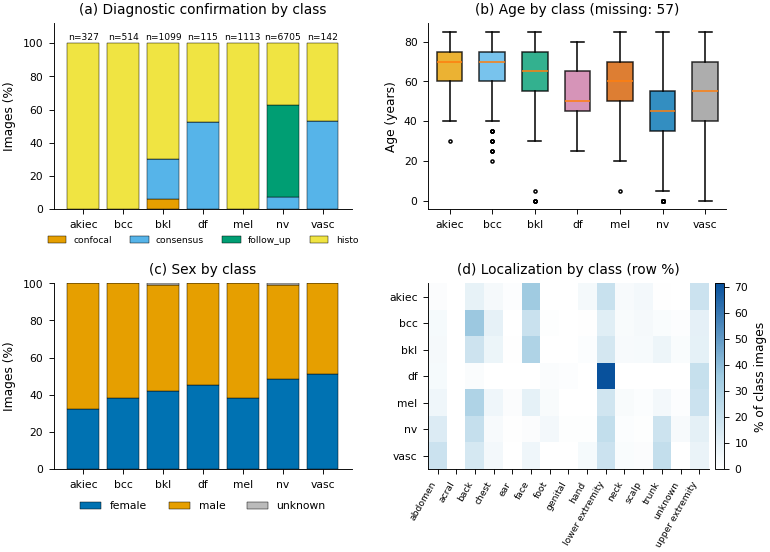

  saved figure: fig_eda_overview.png, fig_eda_overview.pdf


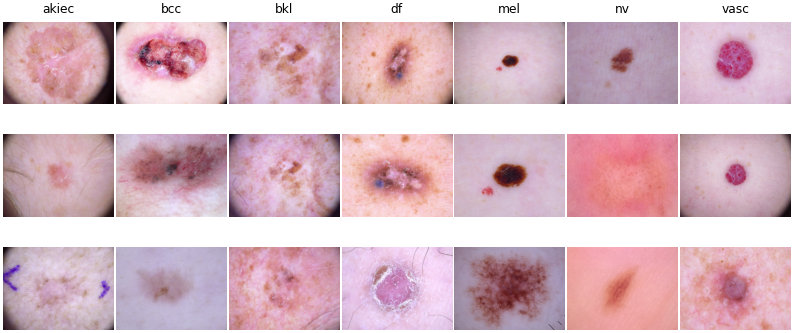

  saved figure: fig_eda_examples.png, fig_eda_examples.pdf


In [5]:
# [WORKER-SKIP]
# [RQ-11][R1-2] Dataset description table and EDA figures
def describe_dataset(frame, class_col="dx", site_col="localization", conf_col="dx_type", classes=CLASS_NAMES):
    rows = []
    for c in classes:
        g = frame[frame[class_col] == c]
        if g.empty:
            continue
        sx = g.sex.fillna("unknown").str.lower().value_counts(normalize=True) * 100
        top = g[site_col].fillna("unknown").value_counts(normalize=True).head(3) * 100
        row = dict(cls=c, images=len(g), lesions=g.lesion_id.nunique() if "lesion_id" in g else np.nan,
                   age_mean=g.age.mean(), age_sd=g.age.std(), age_missing=int(g.age.isna().sum()),
                   male_pct=sx.get("male", 0.0), female_pct=sx.get("female", 0.0),
                   top_sites="; ".join(f"{k} {v:.0f}%" for k, v in top.items()))
        if conf_col and conf_col in g:
            row.update({f"conf_{k}": int(v) for k, v in g[conf_col].value_counts().items()})
        rows.append(row)
    return pd.DataFrame(rows)
desc_ham = describe_dataset(df)
desc_ham.round(1).to_csv(DIRS["results"] / "dataset_description_ham10000.csv", index=False)
display(desc_ham.round(1))

counts = df.label.value_counts().sort_index().values
fig, axs = plt.subplots(2, 2, figsize=(FIG_W2, 5.2))
ax = axs[0, 0]
conf_ct = pd.crosstab(df.dx, df.dx_type, normalize="index").reindex(CLASS_NAMES).fillna(0) * 100
bottom = np.zeros(N_CLASSES)
for col, colr in zip(conf_ct.columns, OKABE_ITO):
    ax.bar(CLASS_NAMES, conf_ct[col].values, bottom=bottom, label=col, color=colr, edgecolor="black", linewidth=0.3)
    bottom += conf_ct[col].values
for i, v in enumerate(counts):
    ax.text(i, 101, f"n={v}", ha="center", va="bottom", fontsize=6)
ax.set_ylim(0, 112); ax.set_ylabel("Images (%)"); ax.set_title("(a) Diagnostic confirmation by class")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1), fontsize=6)

ax = axs[0, 1]
data = [df.loc[(df.label == i) & df.age.notna(), "age"].values for i in range(N_CLASSES)]
bp = ax.boxplot(data, **{("tick_labels" if tuple(map(int, matplotlib.__version__.split(".")[:2])) >= (3, 9) else "labels"): CLASS_NAMES}, patch_artist=True, widths=0.6, flierprops=dict(markersize=2))
for patch, c in zip(bp["boxes"], CLASS_NAMES):
    patch.set_facecolor(CLASS_COLORS[c]); patch.set_alpha(0.8)
ax.set_ylabel("Age (years)"); ax.set_title(f"(b) Age by class (missing: {raw_audit['age_missing']})")

ax = axs[1, 0]
sex_ct = pd.crosstab(df.dx, df.sex.fillna("unknown"), normalize="index").reindex(CLASS_NAMES) * 100
bottom = np.zeros(N_CLASSES)
for col, colr in zip(sex_ct.columns, ["#0072B2", "#E69F00", "#BBBBBB"]):
    ax.bar(CLASS_NAMES, sex_ct[col].values, bottom=bottom, label=col, color=colr, edgecolor="black", linewidth=0.3)
    bottom += sex_ct[col].values
ax.set_ylabel("Images (%)"); ax.set_title("(c) Sex by class"); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))

ax = axs[1, 1]
loc_ct = pd.crosstab(df.dx, df.localization.fillna("unknown"), normalize="index").reindex(CLASS_NAMES) * 100
im = ax.imshow(loc_ct.values, aspect="auto", cmap=SEQ_CMAP, vmin=0)
ax.set_yticks(range(N_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xticks(range(loc_ct.shape[1])); ax.set_xticklabels(loc_ct.columns, rotation=60, ha="right", fontsize=6)
ax.set_title("(d) Localization by class (row %)")
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.set_label("% of class images")
fig.tight_layout()
save_fig(fig, "fig_eda_overview")

fig, axs = plt.subplots(3, N_CLASSES, figsize=(FIG_W2, 3.4))
for j, c in enumerate(CLASS_NAMES):
    paths = df.loc[df.dx == c, "filepath"].iloc[:3].tolist()
    for i in range(3):
        ax = axs[i, j]; ax.axis("off")
        if i < len(paths):
            ax.imshow(plt.imread(paths[i]))
        if i == 0:
            ax.set_title(c, fontsize=8)
fig.tight_layout(pad=0.2)
save_fig(fig, "fig_eda_examples")

## 6. Leakage-controlled splits (stratified and lesion-grouped)
**Request:** R4-4 (test split grouped but not stratified), R1-3 (stratified k-fold), R3-3 (lesion-level separation), R3-4 (identical folds for every arm).

**Purpose.** Create the splits once and store them in `data/splits.csv`, the single source of truth for every experiment.

**Method.**
1. Hold-out test set (`TEST_SPLIT_MODE='stratified_group'`, default): the first fold of `StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)`, i.e. ≈ 14.3 % of images, **grouped by `lesion_id` and stratified by class**. `'original'` reproduces the original `GroupShuffleSplit(test_size=0.15, random_state=42)` split, which is grouped but not stratified.
2. Remaining train/val pool: `StratifiedGroupKFold(n_splits=5)` (deterministic) grouped by `lesion_id`, stratified by label.

**Implementation details.**
* The class proportions of the test set and of every validation fold are compared with the full dataset below; the largest deviation is printed.
* With `'original'`, the test counts and fold sizes are checked against those printed by the original notebook and a mismatch stops the run.
* Because the test split changed, **all previous results are superseded**; the new split is stated in the manuscript.

**Expected output.** `splits.csv`, a stratification table, `fig_split_composition`.

Test counts: {'akiec': 34, 'bcc': 89, 'bkl': 168, 'df': 9, 'mel': 146, 'nv': 974, 'vasc': 21} | val sizes: [1715, 1715, 1714, 1715, 1715]


,All,Test,Val F1,Val F2,Val F3,Val F4,Val F5,Test n
akiec,3.27,2.36,3.44,3.38,3.44,3.44,3.38,34
bcc,5.13,6.18,4.96,4.96,4.96,4.96,4.96,89
bkl,10.97,11.66,10.85,10.85,10.85,10.90,10.85,168
df,1.15,0.62,1.22,1.22,1.23,1.22,1.28,9
mel,11.11,10.13,11.31,11.25,11.26,11.25,11.31,146
nv,66.95,67.59,66.82,66.88,66.86,66.82,66.82,974
vasc,1.42,1.46,1.40,1.46,1.40,1.40,1.40,21


Largest absolute deviation of test class % from full data: 1.04 percentage points (split mode: stratified_group).


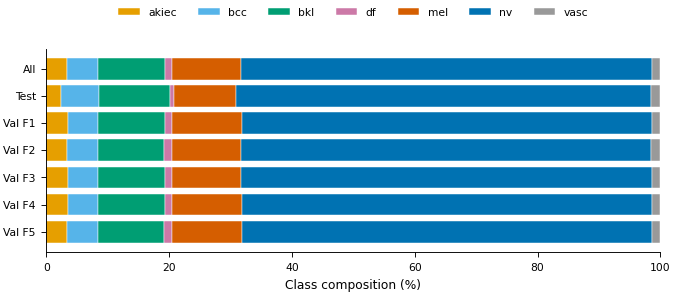

  saved figure: fig_split_composition.png, fig_split_composition.pdf


In [6]:
# [RQ-04][RQ-01] Splits
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit

if CFG["TEST_SPLIT_MODE"] == "original":
    gss = GroupShuffleSplit(n_splits=1, test_size=CFG["TEST_SIZE"], random_state=SEED)
    trainval_idx, test_idx = next(gss.split(df, df["label"], groups=df["lesion_id"]))
else:   # [R4-4] stratified AND lesion-grouped hold-out: first fold of StratifiedGroupKFold(round(1/TEST_SIZE))
    _k = max(2, int(round(1 / CFG["TEST_SIZE"])))
    _sg = StratifiedGroupKFold(n_splits=_k, shuffle=True, random_state=SEED)
    trainval_idx, test_idx = next(_sg.split(df, df["label"], groups=df["lesion_id"]))
trainval_df = df.iloc[trainval_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

sgkf = StratifiedGroupKFold(n_splits=CFG["N_FOLDS"])
fold_of = np.zeros(len(trainval_df), dtype=int)
for k, (_, va) in enumerate(sgkf.split(trainval_df, trainval_df["label"], groups=trainval_df["lesion_id"]), start=1):
    fold_of[va] = k
trainval_df["cv_fold"] = fold_of
test_df["cv_fold"] = 0

splits = pd.concat([trainval_df.assign(split="trainval"), test_df.assign(split="test")], ignore_index=True)
splits = splits.sort_values("row_idx").reset_index(drop=True)
if not WORKER:
    splits[["row_idx", "image_id", "lesion_id", "label", "dx", "split", "cv_fold"]].to_csv(DIRS["data"] / "splits.csv", index=False)

# ---- Verify reproduction of the original splits -----------------------------
test_counts = test_df.label.value_counts().reindex(range(N_CLASSES), fill_value=0).tolist()
val_sizes = [int((trainval_df.cv_fold == k).sum()) for k in range(1, CFG["N_FOLDS"] + 1)]
print("Test counts:", dict(zip(CLASS_NAMES, test_counts)), "| val sizes:", val_sizes)
if CFG["EXPECTED_TEST_COUNTS"] is not None:
    assert test_counts == CFG["EXPECTED_TEST_COUNTS"], "Test split differs from the original notebook!"
    assert val_sizes == CFG["EXPECTED_VAL_SIZES"], "CV folds differ from the original notebook!"
    print("Splits reproduce the original notebook exactly.")

# ---- Stratification report ---------------------------------------------------
def class_pct(frame):
    return frame.label.value_counts(normalize=True).reindex(range(N_CLASSES), fill_value=0).values * 100
strat = pd.DataFrame({"All": class_pct(df), "Test": class_pct(test_df)}, index=CLASS_NAMES)
for k in range(1, CFG["N_FOLDS"] + 1):
    strat[f"Val F{k}"] = class_pct(trainval_df[trainval_df.cv_fold == k])
strat["Test n"] = test_counts
strat.round(2).to_csv(DIRS["results"] / "split_stratification.csv")
display(strat.round(2))
print("Largest absolute deviation of test class % from full data: "
      f"{(strat['Test'] - strat['All']).abs().max():.2f} percentage points (split mode: {CFG['TEST_SPLIT_MODE']}).")

fig, ax = plt.subplots(figsize=(FIG_W2, 2.4))
cols = ["All", "Test"] + [f"Val F{k}" for k in range(1, CFG["N_FOLDS"] + 1)]
left = np.zeros(len(cols))
for c in CLASS_NAMES:
    v = strat.loc[c, cols].values
    ax.barh(cols, v, left=left, color=CLASS_COLORS[c], label=c, edgecolor="white", linewidth=0.3)
    left += v
ax.invert_yaxis(); ax.set_xlabel("Class composition (%)"); ax.set_xlim(0, 100)
ax.legend(ncol=7, loc="upper center", bbox_to_anchor=(0.5, 1.25))
save_fig(fig, "fig_split_composition")

def get_fold_frames(fold):
    """Return (train, val, test) frames for CV fold `fold` (1-based). Metadata untouched here."""
    tr = trainval_df[trainval_df.cv_fold != fold].reset_index(drop=True)
    va = trainval_df[trainval_df.cv_fold == fold].reset_index(drop=True)
    return tr, va, test_df.copy()

## 7. Deterministic image cache (efficiency only)
**Request:** RQ-12 (avoid repeated preprocessing on a single P100 with limited CPU cores).

**Purpose.** JPEG decoding and resizing are deterministic and were repeated every epoch in the original notebook. Each image is decoded and resized **once** with the same TensorFlow operations as the original `parse_image` (bilinear resize to 300 × 300) and stored as an `uint8` memory-mapped array (≈ 2.7 GB on disk; it is not held in GPU memory).

**Implementation details.** The only difference from on-the-fly decoding is rounding the resized values to integers (≤ 0.5 grey level). All *random* augmentation still happens on-the-fly per epoch. No label information is used, so the cache cannot leak information. Set `USE_IMAGE_CACHE=False` to use the original per-epoch decoding.

**Expected output.** `data/image_cache_300.npy` built once, then reused by all experiments and sessions.

In [7]:
# [RQ-12] Build / open the deterministic resized-image cache
CACHE_PATH = DIRS["data"] / f"image_cache_{IMG_SIZE}.npy"
CACHE_META = DIRS["data"] / f"image_cache_{IMG_SIZE}.json"

def _decode_resize(path):
    img = tf.image.decode_jpeg(tf.io.read_file(path), channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])                 # same op as original parse_image
    return tf.cast(tf.clip_by_value(tf.round(img), 0, 255), tf.uint8)

def build_image_cache(frame=None, cache_path=None, meta_path=None):
    frame = df if frame is None else frame
    cache_path, meta_path = cache_path or CACHE_PATH, meta_path or CACHE_META
    if WORKER:
        raise RuntimeError("Image cache missing in a background worker; it must be built by the main notebook first.")
    n = len(frame)
    arr = np.lib.format.open_memmap(cache_path, mode="w+", dtype=np.uint8, shape=(n, IMG_SIZE, IMG_SIZE, 3))
    ds = tf.data.Dataset.from_tensor_slices(frame["filepath"].values).map(_decode_resize, num_parallel_calls=tf.data.AUTOTUNE).batch(256)
    i, t0 = 0, time.time()
    for b in ds:
        b = b.numpy(); arr[i:i + len(b)] = b; i += len(b)
    arr.flush(); del arr
    with open(meta_path, "w") as f:
        json.dump({"n": n, "img_size": IMG_SIZE, "image_ids_md5": hashlib.md5("".join(frame.image_id).encode()).hexdigest()}, f)
    print(f"Cache built: {n} images in {time.time() - t0:.0f}s -> {cache_path}")

IMAGE_CACHE = None
if CFG["USE_IMAGE_CACHE"]:
    ok = False
    if CACHE_PATH.exists() and CACHE_META.exists():
        meta_c = json.load(open(CACHE_META))
        ok = meta_c.get("n") == len(df) and meta_c.get("image_ids_md5") == hashlib.md5("".join(df.image_id).encode()).hexdigest()
    if not ok:
        build_image_cache()
    IMAGE_CACHE = np.load(CACHE_PATH, mmap_mode="r")
    print("Image cache:", IMAGE_CACHE.shape, IMAGE_CACHE.dtype, f"{CACHE_PATH.stat().st_size / 1e9:.2f} GB on disk")

I0000 00:00:1790441317.818653      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790441317.821614      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Cache built: 10015 images in 59s -> /kaggle/working/skinnet_revision/data/image_cache_300.npy
Image cache: (10015, 300, 300, 3) uint8 2.70 GB on disk


## 8. Data-leakage audit
**Request:** RQ-04.

**Purpose.** Programmatically verify the leakage-control claims instead of asserting them in text.

**Checks performed** (results saved to `results/leakage_audit.json`):
1. `lesion_id` sets are disjoint between test and train/val, and between train and val in every fold.
2. Every `image_id` appears in exactly one split.
3. **Byte-identical duplicate images** (MD5 of the JPEG files) across splits.
4. **Near-duplicate screening** with a 64-bit difference hash (dHash) on the cached images. Cross-split pairs with Hamming distance ≤ 4 are listed in `near_duplicate_pairs.csv` for **manual inspection**. dHash is a screening tool with many false alarms on dermoscopy (centred round lesions look alike at 8 × 9 pixels), so each flagged pair is **confirmed by the Pearson correlation of 64 × 64 grey-scale versions** (≥ 0.95 = likely duplicate) and the most similar pairs are shown in `fig_near_duplicate_candidates` for manual review. Nothing is removed automatically.
5. Structural checks of the pipeline (documented and asserted where code can check them): scalers, imputers, encoders and class weights are fitted on the training fold only (Section 9–10 asserts); oversampling touches only training rows; augmentation, MixUp/CutMix are training-only; TTA is inference-only; checkpoint selection uses only the validation fold; the test set is never used for any fitting or selection.

**Known limitation (must be stated in the manuscript).** HAM10000 has no patient identifier. Images of *different* lesions from the same patient may fall in different splits. Separation is **lesion-level**, not patient-level.

**Expected output.** A PASS/FAIL table and counts of exact and near duplicates.

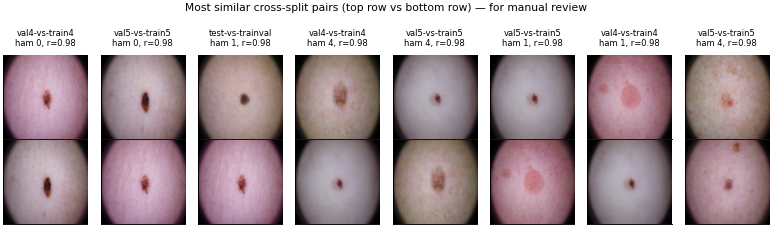

  saved figure: fig_near_duplicate_candidates.png, fig_near_duplicate_candidates.pdf


,check,pass
0,Test vs train/val lesion overlap = 0,True
1,Train vs val lesion overlap = 0 (all folds),True
2,Each image_id in exactly one split,True
3,No byte-identical image across splits/folds,True


Near-duplicate screening (dHash, Hamming <= 4): {'test-vs-trainval': 7105, 'val1-vs-train1': 7181, 'val2-vs-train2': 7252, 'val3-vs-train3': 7441, 'val4-vs-train4': 8636, 'val5-vs-train5': 8080} | confirmed by pixel correlation >= 0.95: 327 (manual review: fig_near_duplicate_candidates)


In [8]:
# [WORKER-SKIP]
# [RQ-04] Leakage audit
audit = {}
tv_les, te_les = set(trainval_df.lesion_id), set(test_df.lesion_id)
audit["test_vs_trainval_lesion_overlap"] = len(tv_les & te_les)
for k in range(1, CFG["N_FOLDS"] + 1):
    tr, va, _ = get_fold_frames(k)
    audit[f"fold{k}_train_vs_val_lesion_overlap"] = len(set(tr.lesion_id) & set(va.lesion_id))
audit["image_id_in_multiple_splits"] = int(splits.image_id.duplicated().sum())

# ---- exact duplicates (file bytes) -----------------------------------------
def md5_file(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()
splits["md5"] = [md5_file(p) for p in df.set_index("row_idx").loc[splits.row_idx, "filepath"]]
dup = splits[splits.md5.duplicated(keep=False)]
cross = 0
for _, g in dup.groupby("md5"):
    if g.split.nunique() > 1 or g.cv_fold.nunique() > 1:
        cross += 1
audit["exact_duplicate_groups_total"] = int(dup.md5.nunique())
audit["exact_duplicate_groups_crossing_splits_or_folds"] = cross

# ---- near duplicates (dHash on cached images) ---------------------------------
def dhash_all():
    src = IMAGE_CACHE if IMAGE_CACHE is not None else None
    hashes = np.zeros(len(df), dtype=np.uint64)
    for s in range(0, len(df), 512):
        if src is not None:
            batch = tf.convert_to_tensor(np.asarray(src[s:s + 512]))
        else:
            batch = tf.stack([_decode_resize(p) for p in df.filepath.values[s:s + 512]])
        g = tf.image.resize(tf.image.rgb_to_grayscale(tf.cast(batch, tf.float32)), [8, 9], antialias=True).numpy()[..., 0]
        bits = (g[:, :, 1:] > g[:, :, :-1]).reshape(len(g), 64)
        hashes[s:s + len(g)] = np.packbits(bits, axis=1).view(">u8").ravel().astype(np.uint64)
    return hashes

def cross_pairs(hashes, idx_a, idx_b, thr=4, tag=""):
    out = []
    hb = hashes[idx_b]
    for i in idx_a:
        x = np.bitwise_xor(hb, hashes[i])
        d = np.unpackbits(x.view(np.uint8).reshape(-1, 8), axis=1).sum(1)
        for j in np.where(d <= thr)[0]:
            out.append((tag, int(i), int(idx_b[j]), int(d[j])))
    return out

HASHES = dhash_all()
row_of = lambda frame: frame.row_idx.values
pairs = cross_pairs(HASHES, row_of(test_df), row_of(trainval_df), tag="test-vs-trainval")
for k in range(1, CFG["N_FOLDS"] + 1):
    tr, va, _ = get_fold_frames(k)
    pairs += cross_pairs(HASHES, row_of(va), row_of(tr), tag=f"val{k}-vs-train{k}")
nd = pd.DataFrame(pairs, columns=["comparison", "row_a", "row_b", "hamming"])
if len(nd):
    nd["image_a"] = df.image_id.values[nd.row_a]; nd["image_b"] = df.image_id.values[nd.row_b]
    nd["lesion_a"] = df.lesion_id.values[nd.row_a]; nd["lesion_b"] = df.lesion_id.values[nd.row_b]
    nd["dx_a"] = df.dx.values[nd.row_a]; nd["dx_b"] = df.dx.values[nd.row_b]
# second-stage confirmation: pixel correlation of 64x64 grey-scale versions (dHash alone gives many false alarms on dermoscopy)
def pair_pixel_corr(cache_a, ia, cache_b, ib, size=64):
    out = []
    for s in range(0, len(ia), 256):
        a = tf.image.resize(tf.image.rgb_to_grayscale(tf.cast(np.asarray(cache_a[np.asarray(ia[s:s + 256])]), tf.float32)), [size, size]).numpy().reshape(-1, size * size)
        b = tf.image.resize(tf.image.rgb_to_grayscale(tf.cast(np.asarray(cache_b[np.asarray(ib[s:s + 256])]), tf.float32)), [size, size]).numpy().reshape(-1, size * size)
        a = (a - a.mean(1, keepdims=True)) / (a.std(1, keepdims=True) + 1e-6); b = (b - b.mean(1, keepdims=True)) / (b.std(1, keepdims=True) + 1e-6)
        out += list((a * b).mean(1))
    return np.asarray(out, np.float32)

def pair_montage(cache_a, ia, cache_b, ib, labels, name, title, n=8):
    n = min(n, len(ia))
    if n == 0:
        return
    fig, axs = plt.subplots(2, n, figsize=(min(FIG_W2, 0.95 * n + 0.3), 2.2)); axs = np.array(axs).reshape(2, n)
    for k in range(n):
        axs[0, k].imshow(np.asarray(cache_a[ia[k]])); axs[1, k].imshow(np.asarray(cache_b[ib[k]]))
        axs[0, k].set_title(labels[k], fontsize=5.5)
        for ax in axs[:, k]:
            ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(title, fontsize=7); fig.tight_layout(); save_fig(fig, name)

CORR_DUP = 0.95
if len(nd):
    nd["pixel_corr"] = pair_pixel_corr(IMAGE_CACHE, nd.row_a.values, IMAGE_CACHE, nd.row_b.values)
    nd["likely_duplicate"] = nd.pixel_corr >= CORR_DUP
    top = nd.sort_values("pixel_corr", ascending=False).head(8)
    pair_montage(IMAGE_CACHE, top.row_a.values, IMAGE_CACHE, top.row_b.values,
                 [f"{r.comparison}\nham {r.hamming}, r={r.pixel_corr:.2f}" for r in top.itertuples()],
                 "fig_near_duplicate_candidates", "Most similar cross-split pairs (top row vs bottom row) — for manual review")
audit["near_duplicate_pairs_pixel_corr_ge_0.95"] = int(nd.likely_duplicate.sum()) if len(nd) else 0
nd.to_csv(DIRS["results"] / "near_duplicate_pairs.csv", index=False)
audit["near_duplicate_pairs_hamming_le4"] = nd.groupby("comparison").size().to_dict() if len(nd) else {}
audit["near_duplicate_pairs_hamming_0"] = int((nd.hamming == 0).sum()) if len(nd) else 0
audit["patient_level_independence_verifiable"] = False

checks = pd.DataFrame([
    ("Test vs train/val lesion overlap = 0", audit["test_vs_trainval_lesion_overlap"] == 0),
    ("Train vs val lesion overlap = 0 (all folds)", all(audit[f"fold{k}_train_vs_val_lesion_overlap"] == 0 for k in range(1, CFG["N_FOLDS"] + 1))),
    ("Each image_id in exactly one split", audit["image_id_in_multiple_splits"] == 0),
    ("No byte-identical image across splits/folds", cross == 0),
], columns=["check", "pass"])
display(checks)
print("Near-duplicate screening (dHash, Hamming <= 4):", audit["near_duplicate_pairs_hamming_le4"],
      f"| confirmed by pixel correlation >= {CORR_DUP}: {audit['near_duplicate_pairs_pixel_corr_ge_0.95']} (manual review: fig_near_duplicate_candidates)")
with open(DIRS["results"] / "leakage_audit.json", "w") as f:
    json.dump(audit, f, indent=2)
assert checks["pass"].iloc[:3].all(), "Lesion-level leakage detected - stop."

## 8A. External dataset: BCN20000 (loading, mapping, description, cross-dataset audit)
**Request:** R7-2 and R1-8 (external validation on an independent dataset), R1-2 (dataset description).

**Scope [R7-2].** BCN20000 is an *independent* dataset from a *different centre and country* (Hospital Clínic Barcelona) than HAM10000 (Vienna, Queensland), but it is **single-centre**; this external validation does not replace a multi-centre or prospective study, and the manuscript must say so.

**Purpose.** Prepare BCN20000 (Hospital Clínic Barcelona, 2010–2016, dermoscopy; CC-BY 4.0) as an **external test set that is never used for training, model selection, calibration or threshold choice**.

**Data used.** Only `bcn_20k_train.csv` (12,413 images with diagnoses). The official BCN20000 test partition has no public diagnoses and is not used.

**Mappings (fixed before evaluation; state them in the manuscript).**
* Diagnosis → HAM10000 classes: `CFG['EXT_CLASS_MAP']` (AK → akiec; NV, MEL, BCC, BKL, DF, VASC unchanged). **SCC is not a HAM10000 class**: SCC images are excluded from the 7-class metrics and analysed separately as out-of-distribution (Section 22A). Note that HAM10000's `akiec` includes intra-epidermal carcinoma (Bowen's disease), so AK → akiec is the closest but not an identical definition.
* Missing sites (BCN20000 records no site for a sizeable fraction of images) are set to `unknown`; their number is reported in `external_audit.json` and the description table.
* Anatomical site → HAM10000 site vocabulary: `CFG['EXT_SITE_MAP']`; unmatched or missing values become `unknown`. BCN20000 uses coarser sites (e.g. `head/neck` vs HAM's face/scalp/ear/neck), so a site-sensitivity analysis (all sites set to `unknown`) is reported in Section 22A.
* Age: `age_approx` (5-year bins); sex: male/female, otherwise unknown. The metadata preprocessors fitted on each HAM10000 training fold are applied unchanged.
* Images are resized to the same S × S input as HAM10000 (BCN images are square crops; HAM images are 600 × 450 and are squashed to square, as in the original pipeline). This difference is part of the domain shift being measured.

**Cross-dataset audit.** Image IDs shared with HAM10000 are excluded, and a dHash near-duplicate screen between BCN20000 and HAM10000 (Hamming distance ≤ 2) is reported for manual review.

**Expected output.** `bcn_external.csv`, `dataset_description_bcn20000.csv`, `external_audit.json`, `bcn_ham_near_duplicates.csv`, and a BCN image cache `data/bcn_cache_{S}.npy`.

,cls,images,lesions,age_mean,age_sd,age_missing,male_pct,female_pct,top_sites
0,akiec,737,236,67.8,12.5,3,49.8,49.8,face 68%; trunk 12%; upper extremity 8%
1,bcc,2809,983,65.5,14.9,6,59.9,39.9,trunk 37%; face 35%; lower extremity 14%
2,bkl,1138,353,62.6,15.5,11,54.9,44.1,face 46%; trunk 26%; lower extremity 18%
3,df,124,40,50.4,16.9,0,47.6,52.4,lower extremity 44%; trunk 31%; upper extremit...
4,mel,2857,524,60.5,15.8,13,51.3,48.3,trunk 39%; face 22%; lower extremity 17%
5,nv,4206,1281,43.4,15.7,41,46.3,52.8,trunk 56%; lower extremity 19%; face 10%
6,vasc,111,37,55.6,16.9,0,53.2,46.8,trunk 41%; lower extremity 28%; face 21%
7,SCC_OOD,431,122,72.1,10.7,0,68.4,31.6,face 31%; lower extremity 29%; trunk 23%


Cache built: 12413 images in 179s -> /kaggle/working/skinnet_revision/data/bcn_cache_300.npy


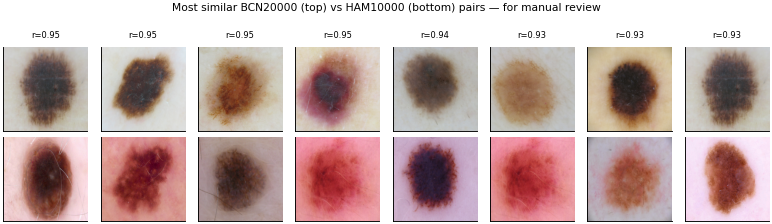

  saved figure: fig_bcn_ham_duplicate_candidates.png, fig_bcn_ham_duplicate_candidates.pdf
BCN20000 used: 12413 images (11982 in the 7 HAM classes, 431 SCC), 3576 lesions | IDs shared with HAM: 0 | dHash candidates: 26442, confirmed (r >= 0.95): 1
Unmapped diagnoses: {} | sites mapped to 'unknown': {'nan': 173}


In [9]:
# [R7-2][R1-8][R1-2] BCN20000 external dataset (workers load it too, for predictions right after training)
def make_synthetic_bcn(root, per_class=12, size=96, seed=1):
    from PIL import Image
    rng = np.random.default_rng(seed); root = Path(root); (root / "BCN_20k_train" / "img").mkdir(parents=True, exist_ok=True)
    rows, k = [], 0
    for c, dx in enumerate(["NV", "MEL", "BCC", "BKL", "AK", "DF", "VASC", "SCC"]):
        for i in range(per_class):
            k += 1; fn = f"BCN_{k:07d}.jpg"
            arr = (rng.random((size, size, 3)) * 80 + np.array([30 + 20 * c, 100, 140 - 10 * c])).clip(0, 255)
            Image.fromarray(arr.astype(np.uint8)).save(root / "BCN_20k_train" / "img" / fn)
            rows.append(dict(bcn_filename=fn, age_approx=float(rng.choice([np.nan, 35, 50, 65, 80])),
                             anatom_site_general=str(rng.choice(["anterior torso", "head/neck", "lower extremity", "palms/soles", "nan"])),
                             diagnosis=dx, lesion_id=f"BCN_L{k // 2:06d}", capture_date="2012-01-01",
                             sex=str(rng.choice(["male", "female", "nan"])), split="train"))
    pd.DataFrame(rows).to_csv(root / "bcn_20k_train.csv", index=False)
    return root / "bcn_20k_train.csv"

def find_bcn_csv():
    if SYNTHETIC:
        p = WORK.parent / "synthetic_bcn" / "bcn_20k_train.csv"
        return p if p.exists() else make_synthetic_bcn(p.parent)
    hits = sorted(glob.glob(str(BCN_DIR / "**" / "bcn_20k_train.csv"), recursive=True)) if BCN_DIR.exists() else []
    if hits:
        return Path(hits[0])
    for pat in ["/kaggle/input/*/bcn_20k_train.csv", "/kaggle/input/*/*/bcn_20k_train.csv",
                "/kaggle/input/*/*/*/bcn_20k_train.csv", "/kaggle/input/*/*/*/*/bcn_20k_train.csv"]:
        hits = sorted(glob.glob(pat))
        if hits:
            return Path(hits[0])
    return None

BCN_CSV = find_bcn_csv()
BCN_AVAILABLE = BCN_CSV is not None
ext_audit = {"available": BCN_AVAILABLE, "csv": str(BCN_CSV)}
bcn_df, BCN_CACHE = None, None
if not BCN_AVAILABLE:
    print("BCN20000 not attached: external validation (Section 22A) will be skipped. Attach pasutchien/bcn20000.")
else:
    raw = pd.read_csv(BCN_CSV)
    root = BCN_CSV.parent
    lookup = {}
    for pth in glob.glob(str(root / "**" / "*.*"), recursive=True):
        if pth.lower().endswith((".jpg", ".jpeg", ".png")):
            lookup.setdefault(Path(pth).stem, pth)
    b = pd.DataFrame({"image_id": raw.bcn_filename.astype(str).map(lambda s: Path(s).stem)})
    b["filepath"] = b.image_id.map(lookup)
    b["diagnosis_raw"] = raw.diagnosis.astype(str).str.upper().str.strip()
    b["dx"] = b.diagnosis_raw.map(CFG["EXT_CLASS_MAP"])
    b["site_raw"] = raw.anatom_site_general.astype(str).str.lower().str.strip()
    b["localization"] = b.site_raw.map(CFG["EXT_SITE_MAP"]).fillna("unknown")
    b["age"] = pd.to_numeric(raw.age_approx, errors="coerce")
    b["sex"] = raw.sex.astype(str).str.lower().str.strip()
    b["lesion_id"] = raw.lesion_id.astype(str).where(raw.lesion_id.notna(), b.image_id)
    ext_audit.update(n_rows_csv=len(raw), missing_image_files=int(b.filepath.isna().sum()),
                     diagnosis_values=b.diagnosis_raw.value_counts().to_dict(),
                     unmapped_diagnoses=b.loc[b.dx.isna(), "diagnosis_raw"].value_counts().to_dict(),
                     site_values=b.site_raw.value_counts().to_dict(),
                     sites_mapped_to_unknown=b.loc[b.localization == "unknown", "site_raw"].value_counts().to_dict(),
                     sex_values=b.sex.value_counts().to_dict(), age_missing=int(b.age.isna().sum()))
    b = b.dropna(subset=["filepath", "dx"])
    ham_overlap = b.image_id.isin(set(df.image_id))
    ext_audit["excluded_ids_shared_with_ham10000"] = int(ham_overlap.sum())
    b = b[~ham_overlap]
    if SMOKE_TEST and not SYNTHETIC:
        _rng, _keep = np.random.default_rng(SEED), []
        for _c, _g in b.groupby("dx"):
            _les = _g.lesion_id.drop_duplicates().values.copy(); _rng.shuffle(_les)
            _keep += list(_les[:CFG["SMOKE_BCN_PER_CLASS"]])
        b = b[b.lesion_id.isin(_keep)]
    b = b.reset_index(drop=True)
    b["label"] = b.dx.map({c: i for i, c in enumerate(CLASS_NAMES)}).fillna(-1).astype(int)   # SCC_OOD -> -1
    b["row_idx"] = np.arange(len(b))
    bcn_df = b
    ext_audit.update(n_used=len(b), n_7class=int((b.label >= 0).sum()), n_scc_ood=int((b.label < 0).sum()),
                     n_lesions=int(b.lesion_id.nunique()), class_counts=b.dx.value_counts().to_dict())
    bcn_df.to_csv(DIRS["data"] / "bcn_external.csv", index=False)

    if not WORKER:
        desc_bcn = describe_dataset(b.assign(sex=b.sex.where(b.sex.isin(["male", "female"]), "unknown")), conf_col=None,
                                    classes=CLASS_NAMES + ["SCC_OOD"])
        desc_bcn.round(1).to_csv(DIRS["results"] / "dataset_description_bcn20000.csv", index=False)
        display(desc_bcn.round(1))

    # ---- image cache (same deterministic resize as HAM10000) ----
    BCN_CACHE_PATH = DIRS["data"] / f"bcn_cache_{IMG_SIZE}.npy"; BCN_CACHE_META = DIRS["data"] / f"bcn_cache_{IMG_SIZE}.json"
    ok = False
    if BCN_CACHE_PATH.exists() and BCN_CACHE_META.exists():
        mc = json.load(open(BCN_CACHE_META))
        ok = mc.get("n") == len(b) and mc.get("image_ids_md5") == hashlib.md5("".join(b.image_id).encode()).hexdigest()
    if not ok:
        build_image_cache(b, BCN_CACHE_PATH, BCN_CACHE_META)
    BCN_CACHE = np.load(BCN_CACHE_PATH, mmap_mode="r")

    if not WORKER:
      # ---- cross-dataset near-duplicate screen (dHash, Hamming <= 2) ----
      def dhash_array(arr, bs=512):
          out = np.zeros(len(arr), dtype=np.uint64)
          for s in range(0, len(arr), bs):
              g = tf.image.resize(tf.image.rgb_to_grayscale(tf.cast(np.asarray(arr[s:s + bs]), tf.float32)), [8, 9], antialias=True).numpy()[..., 0]
              out[s:s + len(g)] = np.packbits((g[:, :, 1:] > g[:, :, :-1]).reshape(len(g), 64), axis=1).view(">u8").ravel().astype(np.uint64)
          return out
      POP8 = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
      h_bcn = dhash_array(BCN_CACHE)
      h_ham = HASHES if "HASHES" in globals() else dhash_array(IMAGE_CACHE)
      near = []
      for i, h in enumerate(h_bcn):
          dist = POP8[np.bitwise_xor(h_ham, h).view(np.uint8).reshape(-1, 8)].sum(1)
          for j in np.where(dist <= 2)[0]:
              near.append((b.image_id.iat[i], df.image_id.iat[j], int(dist[j]), b.dx.iat[i], df.dx.iat[j]))
      near = pd.DataFrame(near, columns=["bcn_image", "ham_image", "hamming", "bcn_dx", "ham_dx"])
      if len(near):
          _bi = {v: i for i, v in enumerate(b.image_id)}; _hi = {v: i for i, v in enumerate(df.image_id)}
          ia_, ib_ = near.bcn_image.map(_bi).values, near.ham_image.map(_hi).values
          near["pixel_corr"] = pair_pixel_corr(BCN_CACHE, ia_, IMAGE_CACHE, ib_); near["likely_duplicate"] = near.pixel_corr >= CORR_DUP
          o_ = np.argsort(-near.pixel_corr.values)[:8]
          pair_montage(BCN_CACHE, ia_[o_], IMAGE_CACHE, ib_[o_], [f"r={near.pixel_corr.iat[k]:.2f}" for k in o_],
                       "fig_bcn_ham_duplicate_candidates", "Most similar BCN20000 (top) vs HAM10000 (bottom) pairs — for manual review")
      ext_audit["bcn_ham_pairs_pixel_corr_ge_0.95"] = int(near.likely_duplicate.sum()) if len(near) else 0
      near.to_csv(DIRS["results"] / "bcn_ham_near_duplicates.csv", index=False)
      ext_audit["near_duplicates_bcn_vs_ham_hamming_le2"] = len(near)
      print(f"BCN20000 used: {len(b)} images ({ext_audit['n_7class']} in the 7 HAM classes, {ext_audit['n_scc_ood']} SCC), "
            f"{ext_audit['n_lesions']} lesions | IDs shared with HAM: {ext_audit['excluded_ids_shared_with_ham10000']} | "
            f"dHash candidates: {len(near)}, confirmed (r >= {CORR_DUP}): {ext_audit['bcn_ham_pairs_pixel_corr_ge_0.95']}")
      print("Unmapped diagnoses:", ext_audit["unmapped_diagnoses"], "| sites mapped to 'unknown':", ext_audit["sites_mapped_to_unknown"])
with open(DIRS["results"] / "external_audit.json", "w") as f:
    json.dump(ext_audit, f, indent=2, default=str)

## 9. Metadata preprocessing (fold-wise fitting) and metadata audit
**Request:** RQ-05 (age, sex, localization encoding; missing values; scaling; consistency with the mathematical description), RQ-04 (fit on training fold only).

**Purpose.** Convert age, sex and anatomical localization into the metadata vector **m** used by the network. Every statistic is fitted on the **training fold only** and then applied unchanged to that fold's validation set and to the test set.

| Variable | Type | Missing values | Encoding | Dim. |
|---|---|---|---|---|
| Age | numeric | median of the **training fold** | min–max scaling fitted on the training fold (after imputation); val/test values outside the training range are not clipped | 1 |
| Sex | nominal {male, female, unknown} | NaN → `unknown` | one-hot | 3 |
| Localization | **nominal** (15 HAM10000 sites incl. `unknown`) | NaN / unseen → `unknown` | **one-hot** over the training-fold vocabulary (default) | K (= 15 when all sites occur in the training fold) |

**Why the localization encoding changed (reviewer concern).** In the original model the site was an integer index into an `Embedding(16, 8)` layer. An embedding lookup does not impose an order, so it was not an ordinal encoding. However, the representation is easily misread as an integer feature, and it cannot be interpolated by MixUp/CutMix. One-hot input followed by the first dense layer is the same function class as an embedding followed by that dense layer (one-hot × W equals a row lookup), so the methodology is preserved while removing both problems. The original variant stays available via `LOC_ENCODING='embedding'`.

**Mathematical description to use in the manuscript** (`onehot` mode):
m = [ a ; s ; ℓ ] ∈ ℝ^{1+3+K},  a = (age − min_train)/(max_train − min_train),  s ∈ {0,1}³,  ℓ ∈ {0,1}^K.
h_meta = ReLU(W_m m + b_m) ∈ ℝ³²,  z = [ GAP(F) ; h_meta ] ∈ ℝ^{384+32}.

**Expected output.** Per-fold fitted statistics and a metadata specification table (`metadata_spec.csv`). Assertions confirm that the scaler statistics equal the training-fold statistics.

In [10]:
# [RQ-05][RQ-04] Fold-wise metadata preprocessing
from sklearn.preprocessing import MinMaxScaler

SEX_CATS = ["male", "female", "unknown"]

def _clean_sex(s):
    s = s.fillna("unknown").astype(str).str.lower().str.strip()
    return s.where(s.isin(["male", "female"]), "unknown")

def _clean_loc(s):
    return s.fillna("unknown").astype(str).str.lower().str.strip()

META_FEATURES = ("age", "sex", "site")

class MetaPreprocessor:
    """Fitted on a training fold only; transform() is applied to train, val, test and external data.
    `features` selects a subset of (age, sex, site) for the leave-one-feature-out arms [R7-3]."""
    def __init__(self, loc_encoding="onehot", features=META_FEATURES):
        self.loc_encoding = loc_encoding
        self.features = tuple(features)

    def fit(self, train):
        self.age_median = float(train.age.median())
        self.scaler = MinMaxScaler().fit(train.age.fillna(self.age_median).values.reshape(-1, 1))
        seen = sorted(set(_clean_loc(train.localization)) - {"unknown"})
        self.loc_vocab = seen + ["unknown"]
        self.loc_index = {v: i for i, v in enumerate(self.loc_vocab)}
        self.n_fit_rows = len(train)
        return self

    @property
    def dense_dim(self):   # dimension of the float metadata vector fed to the network
        return len(self.feature_names())

    def feature_groups(self):
        """Column indices of each feature group in the dense vector (used by SHAP / permutation importance)."""
        names, groups = self.feature_names(), {}
        for i, n in enumerate(names):
            g = "age" if n.startswith("age") else ("sex" if n.startswith("sex=") else "site")
            groups.setdefault(g, []).append(i)
        return groups

    def to_json(self):
        return dict(loc_encoding=self.loc_encoding, features=list(self.features), age_median=self.age_median,
                    age_min=float(self.scaler.data_min_[0]), age_max=float(self.scaler.data_max_[0]),
                    sex_categories=SEX_CATS, loc_vocab=self.loc_vocab, feature_order=self.feature_names())

    def transform(self, frame):
        age = self.scaler.transform(frame.age.fillna(self.age_median).values.reshape(-1, 1)).astype(np.float32)
        sex = _clean_sex(frame.sex)
        sex_oh = np.stack([(sex == c).values for c in SEX_CATS], 1).astype(np.float32)
        loc = _clean_loc(frame.localization).map(lambda v: self.loc_index.get(v, self.loc_index["unknown"])).values.astype(np.int32)
        parts = []
        if "age" in self.features: parts.append(age)
        if "sex" in self.features: parts.append(sex_oh)
        if "site" in self.features and self.loc_encoding == "onehot":
            parts.append(np.eye(len(self.loc_vocab), dtype=np.float32)[loc])
        dense = np.concatenate(parts, 1) if parts else np.zeros((len(frame), 0), np.float32)
        return dense.astype(np.float32), loc.reshape(-1, 1)

    def feature_names(self):
        names = []
        if "age" in self.features: names.append("age_minmax")
        if "sex" in self.features: names += [f"sex={c}" for c in SEX_CATS]
        if "site" in self.features and self.loc_encoding == "onehot": names += [f"loc={v}" for v in self.loc_vocab]
        return names

spec_rows = []
for k in range(1, CFG["N_FOLDS"] + 1):
    tr, va, te = get_fold_frames(k)
    mp = MetaPreprocessor(CFG["LOC_ENCODING"]).fit(tr)
    # leakage assertions: statistics equal those of the training fold alone
    assert np.isclose(mp.age_median, tr.age.median())
    imputed = tr.age.fillna(tr.age.median())
    assert np.isclose(mp.scaler.data_min_[0], imputed.min()) and np.isclose(mp.scaler.data_max_[0], imputed.max())
    assert mp.n_fit_rows == len(tr)
    d_va, _ = mp.transform(va); d_te, _ = mp.transform(te)
    spec_rows.append(dict(fold=k, age_median=mp.age_median, age_min=mp.scaler.data_min_[0], age_max=mp.scaler.data_max_[0],
                          n_loc_vocab=len(mp.loc_vocab), meta_dim=mp.dense_dim,
                          val_age_outside_0_1=int(((d_va[:, 0] < 0) | (d_va[:, 0] > 1)).sum()),
                          test_age_outside_0_1=int(((d_te[:, 0] < 0) | (d_te[:, 0] > 1)).sum()),
                          test_unseen_loc=int((~_clean_loc(te.localization).isin(mp.loc_vocab)).sum())))
meta_spec = pd.DataFrame(spec_rows)
meta_spec.to_csv(DIRS["results"] / "metadata_spec.csv", index=False)
display(meta_spec)
print("Metadata feature order:", MetaPreprocessor(CFG["LOC_ENCODING"]).fit(get_fold_frames(1)[0]).feature_names())

,fold,age_median,age_min,age_max,n_loc_vocab,meta_dim,val_age_outside_0_1,test_age_outside_0_1,test_unseen_loc
0,1,50.0,0.0,85.0,15,19,0,0,0
1,2,50.0,0.0,85.0,15,19,0,0,0
2,3,50.0,0.0,85.0,15,19,0,0,0
3,4,50.0,0.0,85.0,15,19,0,0,0
4,5,50.0,0.0,85.0,15,19,0,0,0


Metadata feature order: ['age_minmax', 'sex=male', 'sex=female', 'sex=unknown', 'loc=abdomen', 'loc=acral', 'loc=back', 'loc=chest', 'loc=ear', 'loc=face', 'loc=foot', 'loc=genital', 'loc=hand', 'loc=lower extremity', 'loc=neck', 'loc=scalp', 'loc=trunk', 'loc=upper extremity', 'loc=unknown']


## 10. Class-imbalance strategy (documented and quantified)
**Request:** RQ-07 (oversampling cap, class weighting, focal loss, augmentation), RQ-04 (training fold only).

**Purpose.** Reproduce the original training-fold balancing and make every component explicit and switchable, so that the ablation can quantify each part.

**Components of the SkinNet imbalance strategy (configuration E):**
1. **Capped oversampling / majority downsampling** (`smart_oversample`, unchanged). For a class with *n* training images, the target is `min(TARGET_PER_CLASS, MAX_OVERSAMPLE_X · n) = min(3000, 5n)`. Classes above 3000 (only `nv`) are downsampled without replacement to 3000. Smaller classes are topped up by sampling **with replacement** from their own training images. The **5× cap** prevents the rarest classes (df ≈ 84, vasc ≈ 90 images per training fold) from being replicated about 35×, which would encourage memorisation. With the cap, df and vasc reach 420–455 images; bkl and mel reach 3000 (≈ 4×, under the cap).
2. **Class weights**: `compute_class_weight('balanced')` on the **original** training-fold labels (before resampling), applied **per sample inside the loss** (corrected; see finding F2).
3. **Class-adaptive augmentation**: stronger photometric augmentation and an extra cutout for akiec, bcc, df, vasc.
4. **Focal loss** (γ = 2, α = 0.25) with label smoothing 0.1 (configuration G/H).

**Double compensation (transparency note).** Components 1 and 2 both act on class frequency. The table below prints the *effective class mass* (resampled count × class weight). With both active, capped classes receive roughly 7–8 times the mass of `nv`. The supplementary configurations `E_OS` (no class weights), `E_CW` (class weights only) and `E_RS` (resampling only) quantify this. Choose the Full SkinNet definition **before** seeing test results.

Only the training fold is resampled. Validation and test sets are never resampled, weighted or augmented.

**Expected output.** Per-fold balancing report (should match the original notebook) and `fig_imbalance_strategy`.

,cls,original,effective_target,final,action,fold,class_weight,effective_mass_resample_plus_cw,total_after_balancing
0,akiec,234,1170,1170,oversample 5.0x,1,4.187,4899.286,12780
1,bcc,340,1700,1700,oversample 5.0x,1,2.882,4899.286,12780
2,bkl,745,3000,3000,oversample 4.0x,1,1.315,3945.733,12780
3,df,85,425,425,oversample 5.0x,1,11.528,4899.286,12780
4,mel,773,3000,3000,oversample 3.9x,1,1.268,3802.809,12780
5,nv,4585,3000,3000,downsample,1,0.214,641.128,12780
6,vasc,97,485,485,oversample 5.0x,1,10.102,4899.286,12780


Total after balancing per fold: [12780, 12780, 12780, 12780, 12780] (original notebook: [12785, 12775, 12780, 12780, 12780])


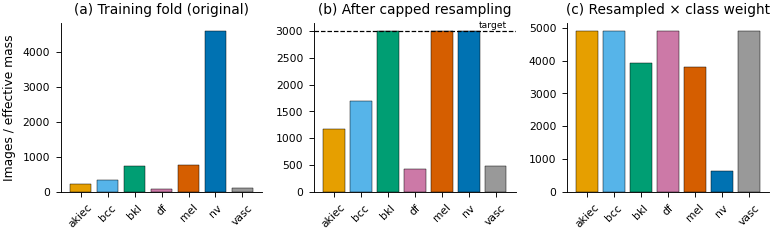

  saved figure: fig_imbalance_strategy.png, fig_imbalance_strategy.pdf


In [11]:
# [RQ-07] Imbalance components
from sklearn.utils.class_weight import compute_class_weight

def smart_oversample(train_fold, target, max_x, random_state=42):
    """Original SkinNet balancing (unchanged): cap = min(target, max_x * n); majority downsampled."""
    parts, reports = [], []
    for c in range(N_CLASSES):
        cls_df = train_fold[train_fold.label == c]
        n = len(cls_df)
        if n == 0:
            continue
        eff = min(target, n * max_x)
        if n >= target:
            out, action = cls_df.sample(n=target, replace=False, random_state=random_state), "downsample"
        elif n < eff:
            extra = cls_df.sample(n=eff - n, replace=True, random_state=random_state)
            out, action = pd.concat([cls_df, extra], ignore_index=True), f"oversample {eff / n:.1f}x"
        else:
            out, action = cls_df, "keep"
        parts.append(out)
        reports.append(dict(cls=CLASS_NAMES[c], original=n, effective_target=eff, final=len(out), action=action))
    out_df = pd.concat(parts, ignore_index=True).sample(frac=1, random_state=random_state).reset_index(drop=True)
    return out_df, pd.DataFrame(reports)

def fold_class_weights(train_fold):
    return compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=train_fold.label.values).astype(np.float32)

rows = []
for k in range(1, CFG["N_FOLDS"] + 1):
    tr, _, _ = get_fold_frames(k)
    rs, rep = smart_oversample(tr, CFG["TARGET_PER_CLASS"], CFG["MAX_OVERSAMPLE_X"], SEED)
    assert set(rs.image_id) <= set(tr.image_id), "Resampled rows must come from the training fold only"
    cw = fold_class_weights(tr)
    rep["fold"] = k; rep["class_weight"] = cw[[CLASS_NAMES.index(c) for c in rep.cls]]
    rep["effective_mass_resample_plus_cw"] = rep.final * rep.class_weight
    rep["total_after_balancing"] = len(rs)
    rows.append(rep)
balance = pd.concat(rows, ignore_index=True)
balance.to_csv(DIRS["results"] / "imbalance_report.csv", index=False)
display(balance[balance.fold == 1].round(3))
print("Total after balancing per fold:", balance.groupby("fold").total_after_balancing.first().tolist(),
      "(original notebook: [12785, 12775, 12780, 12780, 12780])")

b1 = balance[balance.fold == 1].set_index("cls").reindex(CLASS_NAMES)
fig, axs = plt.subplots(1, 3, figsize=(FIG_W2, 2.3))
for ax, col, title in zip(axs, ["original", "final", "effective_mass_resample_plus_cw"],
                          ["(a) Training fold (original)", "(b) After capped resampling", "(c) Resampled × class weight"]):
    ax.bar(CLASS_NAMES, b1[col], color=[CLASS_COLORS[c] for c in CLASS_NAMES], edgecolor="black", linewidth=0.3)
    ax.set_title(title); ax.tick_params(axis="x", rotation=45)
axs[0].set_ylabel("Images / effective mass")
axs[1].axhline(CFG["TARGET_PER_CLASS"], ls="--", lw=0.8, color="black")
axs[1].text(6.4, CFG["TARGET_PER_CLASS"] * 1.02, "target", ha="right", fontsize=6)
fig.tight_layout()
save_fig(fig, "fig_imbalance_strategy")

## 11. Augmentation, corrected multimodal MixUp/CutMix and `tf.data` pipelines
**Request:** R4-2 (multimodal MixUp/CutMix described mathematically and algorithmically), R8-8 (rationale), R1-2 (augmentation details); earlier RQ-06/07/08/12.

**Per-sample augmentation (unchanged from the original training cells).** Random horizontal/vertical flip, random 90° rotation, brightness ±25.5, contrast/saturation 0.8–1.2, hue ±0.05, random crop (85–100 %) resized back, cutout (40-px half-size, p = 0.5). The strong variant used for minority classes adds contrast 0.7–1.4, brightness ±40 and a second cutout (20 px, p = 0.4).

**Corrected batch mixing (applied only to training batches, Phase 2 in two-phase training, as in the original).** For a batch with permutation π and mixing coefficient λ:

| Item | CutMix (p = 0.3) | MixUp (p = 1.0 of batches) |
|---|---|---|
| λ | u ~ U(0,1) = Beta(1,1); the box has side √(1−u)·S; **λ is recomputed from the clipped box area**: λ = 1 − area/S² (one box per batch) | per sample λᵢ ~ Beta(0.2, 0.2), then λᵢ ← max(λᵢ, 1−λᵢ) (the "keep the dominant sample" rule of the original code) |
| image | x̃ = M ⊙ x_π + (1−M) ⊙ x | x̃ = λ x + (1−λ) x_π |
| label | ỹ = λ y + (1−λ) y_π | same |
| metadata (dense: age, sex one-hot, site one-hot) | m̃ = λ m + (1−λ) m_π (**new**) | same (**new**) |
| class weight | enters through ỹ inside the loss: w̃ = Σ_c cw_c ỹ_c = λ w + (1−λ) w_π | same |

**Rationale [R8-8].** CutMix keeps local lesion texture intact while forcing the model to use more than one region; MixUp smooths the decision boundaries between visually similar classes (e.g. nv/mel/bkl) and improves calibration. Both act only on Phase-2 training batches, after the head has been trained on clean images in Phase 1. Their joint contribution is measured by F vs E (and H vs G).

CutMix and MixUp are applied sequentially (as in the original). Each step is a convex combination with one shared (π, λ) for image, label and metadata, so the pairing stays consistent through the composition.

**Loss with mixed targets.** The loss below is linear in the target vector. Evaluating it on ỹ therefore equals λ·L(y) + (1−λ)·L(y_π) (label smoothing is applied after mixing). A separate "mixed-loss" formulation is unnecessary.

If `LOC_ENCODING='embedding'`, the integer site index cannot be interpolated. The index of the dominant sample (λ ≥ 0.5) is used and this is flagged as an approximation.

**TTA** (`make_eval_dataset(..., tta_view=v)`) exists only in the evaluation pipeline. Deterministic views: identity, horizontal flip, vertical flip, rotate 90°, rotate 270°.

**Expected output.** A unit test proving image/label/metadata alignment after mixing, and the λ distributions of the corrected and legacy MixUp rules. (Augmented examples are plotted in Section 14.)

In [12]:
# [RQ-06][RQ-07][RQ-08][RQ-12] Augmentation, mixing and datasets
AUTOTUNE = tf.data.AUTOTUNE
MINORITY = tf.constant(CFG["MINORITY_IDX"], dtype=tf.int32)
S = IMG_SIZE

def load_image(src):
    if IMAGE_CACHE is not None:
        img = tf.numpy_function(lambda i: np.asarray(IMAGE_CACHE[int(i)]), [src], tf.uint8)
        img.set_shape([S, S, 3])
        return tf.cast(img, tf.float32)
    img = tf.image.decode_jpeg(tf.io.read_file(src), channels=3)
    return tf.cast(tf.image.resize(img, [S, S]), tf.float32)      # original parse_image, range [0,255]

def cutout(img, pad_size, prob=0.5):
    def apply():
        cy = tf.random.uniform([], 0, S, dtype=tf.int32); cx = tf.random.uniform([], 0, S, dtype=tf.int32)
        y1, y2 = tf.maximum(0, cy - pad_size), tf.minimum(S, cy + pad_size)
        x1, x2 = tf.maximum(0, cx - pad_size), tf.minimum(S, cx + pad_size)
        mask = 1.0 - tf.pad(tf.ones([y2 - y1, x2 - x1, 3], img.dtype), [[y1, S - y2], [x1, S - x2], [0, 0]])
        return img * mask
    return tf.cond(tf.random.uniform([]) < prob, apply, lambda: img)

def standard_aug(img):
    img = tf.image.random_flip_left_right(img); img = tf.image.random_flip_up_down(img)
    img = tf.image.rot90(img, tf.random.uniform([], 0, 4, dtype=tf.int32))
    img = tf.image.random_brightness(img, 25.5); img = tf.image.random_contrast(img, 0.8, 1.2)
    img = tf.image.random_saturation(img, 0.8, 1.2); img = tf.image.random_hue(img, 0.05)
    crop = tf.cast(tf.random.uniform([], 0.85, 1.0) * S, tf.int32)
    img = tf.image.resize(tf.image.random_crop(img, [crop, crop, 3]), [S, S])
    img = cutout(img, pad_size=max(1, int(round(40 * S / 300))), prob=0.5)
    return tf.clip_by_value(img, 0.0, 255.0)

def strong_aug(img):
    img = standard_aug(img)
    img = tf.image.random_contrast(img, 0.7, 1.4); img = tf.image.random_brightness(img, 40.0)
    img = cutout(img, pad_size=max(1, int(round(20 * S / 300))), prob=0.4)
    return tf.clip_by_value(img, 0.0, 255.0)

def sample_beta(a, b, shape):
    x = tf.random.gamma(shape, a); y = tf.random.gamma(shape, b)
    return x / (x + y + 1e-12)

def cutmix_batch(img, y, meta, loc, prob, alpha):
    def apply():
        bs = tf.shape(img)[0]
        u = sample_beta(alpha, alpha, [])                         # alpha=1 -> U(0,1) (original)
        cut = tf.cast(S * tf.sqrt(1.0 - u), tf.int32)
        cx = tf.random.uniform([], 0, S, dtype=tf.int32); cy = tf.random.uniform([], 0, S, dtype=tf.int32)
        x1 = tf.clip_by_value(cx - cut // 2, 0, S); x2 = tf.clip_by_value(cx + cut // 2, 0, S)
        y1 = tf.clip_by_value(cy - cut // 2, 0, S); y2 = tf.clip_by_value(cy + cut // 2, 0, S)
        mask = tf.pad(tf.ones([y2 - y1, x2 - x1, 1], img.dtype), [[y1, S - y2], [x1, S - x2], [0, 0]])
        perm = tf.random.shuffle(tf.range(bs))
        lam = 1.0 - tf.cast((y2 - y1) * (x2 - x1), tf.float32) / float(S * S)   # exact area ratio
        img_m = img * (1.0 - mask) + tf.gather(img, perm) * mask
        y_m = lam * y + (1.0 - lam) * tf.gather(y, perm)
        meta_m = lam * meta + (1.0 - lam) * tf.gather(meta, perm)
        loc_m = tf.where(lam >= 0.5, loc, tf.gather(loc, perm))
        return img_m, y_m, meta_m, loc_m
    return tf.cond(tf.random.uniform([]) < prob, apply, lambda: (img, y, meta, loc))

def mixup_batch(img, y, meta, loc, prob, alpha, mode):
    def apply():
        bs = tf.shape(img)[0]
        if mode == "beta":
            lam = sample_beta(alpha, alpha, [bs]); lam = tf.maximum(lam, 1.0 - lam)
        else:   # legacy rule of the original notebook
            lam = tf.maximum(tf.random.uniform([bs]), 1.0 - tf.random.uniform([bs]))
        perm = tf.random.shuffle(tf.range(bs))
        li, lv = tf.reshape(lam, [-1, 1, 1, 1]), tf.reshape(lam, [-1, 1])
        return (li * img + (1 - li) * tf.gather(img, perm), lv * y + (1 - lv) * tf.gather(y, perm),
                lv * meta + (1 - lv) * tf.gather(meta, perm), loc)          # lam>=0.5: own site index dominates
    return tf.cond(tf.random.uniform([]) < prob, apply, lambda: (img, y, meta, loc))

def _to_inputs(exp):
    def f(img, y, meta, loc):
        x = {}
        if exp.use_image:
            x["image_input"] = img
        if exp.use_meta:
            x["meta_input"] = meta
            if CFG["LOC_ENCODING"] == "embedding":
                x["loc_index_input"] = loc
        return x, y
    return f

def _source(frame):
    return frame.row_idx.values.astype(np.int64) if IMAGE_CACHE is not None else frame.filepath.values

def make_train_dataset(frame, meta_dense, loc_idx, exp, apply_mix, seed):
    y = np.eye(N_CLASSES, dtype=np.float32)[frame.label.values]
    ds = tf.data.Dataset.from_tensor_slices((_source(frame), y, meta_dense, loc_idx))
    ds = ds.shuffle(len(frame), seed=seed, reshuffle_each_iteration=True).repeat()
    minority_aug = exp.minority_aug
    def load_aug(src, yy, m, l):
        if not exp.use_image:
            return tf.zeros([1, 1, 3]), yy, m, l
        img = load_image(src)
        if minority_aug:
            is_min = tf.reduce_any(tf.equal(tf.cast(tf.argmax(yy), tf.int32), MINORITY))
            img = tf.cond(is_min, lambda: strong_aug(img), lambda: standard_aug(img))
        else:
            img = standard_aug(img)
        return img, yy, m, l
    ds = ds.map(load_aug, num_parallel_calls=AUTOTUNE).batch(getattr(exp, "batch_size", 0) or BATCH_SIZE, drop_remainder=True)
    mm = getattr(exp, "mix_mode", "both")          # "both" (default, all original arms) | "cutmix" | "mixup" [R7-4]
    if apply_mix and exp.use_image and mm in ("both", "cutmix"):
        ds = ds.map(lambda i, yy, m, l: cutmix_batch(i, yy, m, l, CFG["CUTMIX_PROB"], CFG["CUTMIX_ALPHA"]), num_parallel_calls=AUTOTUNE)
    if apply_mix and exp.use_image and mm in ("both", "mixup"):
        ds = ds.map(lambda i, yy, m, l: mixup_batch(i, yy, m, l, CFG["MIXUP_PROB"], CFG["MIXUP_ALPHA"], CFG["MIXUP_LAMBDA_MODE"]), num_parallel_calls=AUTOTUNE)
    return ds.map(_to_inputs(exp), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

def tta_transform(img, view):
    if CFG["TTA_MODE"] == "deterministic":
        return [lambda x: x, tf.image.flip_left_right, tf.image.flip_up_down,
                lambda x: tf.image.rot90(x, 1), lambda x: tf.image.rot90(x, 3)][view](img)
    if view == 0:      # legacy: clean pass + random photometric/geometric passes
        return img
    img = tf.image.random_flip_left_right(img); img = tf.image.random_flip_up_down(img)
    img = tf.image.rot90(img, tf.random.uniform([], 0, 4, dtype=tf.int32))
    img = tf.image.random_brightness(img, 20.0); img = tf.image.random_contrast(img, 0.85, 1.15)
    return tf.clip_by_value(img, 0.0, 255.0)

def make_eval_dataset(frame, meta_dense, loc_idx, exp, tta_view=None, cache=None):
    """Validation/test/external pipeline: no shuffling, resampling, augmentation or mixing. TTA only here.
    `cache`: another uint8 image array (e.g. BCN20000) indexed by frame.row_idx."""
    y = np.eye(N_CLASSES, dtype=np.float32)[np.clip(frame.label.values.astype(int), 0, None)]   # external OOD rows: label -1
    if cache is None:
        src_arr, loader = _source(frame), load_image
    else:
        src_arr = frame.row_idx.values.astype(np.int64)
        def loader(src):
            img = tf.numpy_function(lambda i: np.asarray(cache[int(i)]), [src], tf.uint8)
            img.set_shape([S, S, 3])
            return tf.cast(img, tf.float32)
    ds = tf.data.Dataset.from_tensor_slices((src_arr, y, meta_dense, loc_idx))
    def load(src, yy, m, l):
        if not exp.use_image:
            return tf.zeros([1, 1, 3]), yy, m, l
        img = loader(src)
        if tta_view is not None:
            img = tta_transform(img, tta_view)
        return img, yy, m, l
    ds = ds.map(load, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE * 2)
    return ds.map(_to_inputs(exp), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

# ---------------- Unit tests: alignment of image, label and metadata ----------------
def _alignment_test(n=16, trials=20):
    """Encode the sample identity k in all three modalities; after mixing they must still agree."""
    for t in range(trials):
        k = np.arange(n) % N_CLASSES
        y = np.eye(N_CLASSES, dtype=np.float32)[k]
        meta = np.concatenate([np.zeros((n, 4), np.float32), y], 1)            # "site one-hot" == label
        img = np.broadcast_to(k[:, None, None, None].astype(np.float32), (n, S, S, 3)).copy()
        loc = k.reshape(-1, 1).astype(np.int32)
        a = [tf.constant(v) for v in (img, y, meta, loc)]
        a = cutmix_batch(*a, prob=1.0, alpha=1.0)
        a = mixup_batch(*a, prob=1.0, alpha=0.2, mode="beta")
        im, yy, mm, _ = [v.numpy() for v in a]
        assert np.allclose(mm[:, 4:], yy, atol=1e-5), "metadata not aligned with labels"
        assert np.allclose(im.mean(axis=(1, 2, 3)), yy @ np.arange(N_CLASSES), atol=1e-3), "image not aligned with labels"
        assert np.allclose(yy.sum(1), 1.0, atol=1e-5)
    return True
print("MixUp/CutMix alignment test:", "PASS" if _alignment_test() else "FAIL")

lam_beta = np.maximum(*(lambda b: (b, 1 - b))(np.random.default_rng(0).beta(CFG["MIXUP_ALPHA"], CFG["MIXUP_ALPHA"], 100000)))
lam_legacy = np.maximum(np.random.default_rng(1).random(100000), 1 - np.random.default_rng(2).random(100000))
print(f"MixUp lambda mean: beta mode = {lam_beta.mean():.3f}, legacy rule = {lam_legacy.mean():.3f}")

MixUp/CutMix alignment test: PASS
MixUp lambda mean: beta mode = 0.898, legacy rule = 0.667


## 12. Loss function and learning-rate schedule
**Request:** RQ-07 (class weighting, focal loss, label smoothing), RQ-06 (loss under mixed targets), RQ-01 (one loss family for every ablation).

**Purpose.** One loss class covers every ablation arm:

L(y, p) = w(y) · α · Σ_c ỹ_c (1 − p_c)^γ (−log p_c),  with ỹ = (1 − ε) y + ε / C and w(y) = Σ_c cw_c y_c.

| Setting | γ | α | ε | Used by |
|---|---|---|---|---|
| Cross-entropy | 0 | 1 | 0 | A–F, E_* |
| Focal + label smoothing (original SkinNet) | 2 | 0.25 | 0.1 | G, H |
| Focal only | 2 | 0.25 | 0 | G_F |
| Cross-entropy + label smoothing | 0 | 1 | 0.1 | G_LS |

**Implementation details.**
* The focal term is applied element-wise to every class (the original formulation). The loss is computed in float32 even under FP16.
* **Class weights** `w(y)` are computed from the *unsmoothed* (possibly mixed) target, per sample. For hard labels this is exactly the intended per-sample class weight. `legacy_batch_scalar` reproduces the original behaviour (loss × batch-mean weight) for transparency.
* **Schedule** (unchanged): linear warm-up for 3 epochs, then cosine decay to `MIN_LR`, per phase. Adam with gradient-norm clipping 1.0.

**Expected output.** Unit tests: (i) γ = 0, α = 1, ε = 0 reproduces categorical cross-entropy; (ii) the per-sample weighting differs from the legacy batch-scalar behaviour and matches a manual computation; (iii) the loss is linear in the target (mixed-target identity).

In [13]:
# [RQ-07][RQ-06] Unified loss + LR schedule
@keras.saving.register_keras_serializable(package="skinnet")
class SkinNetLoss(keras.losses.Loss):
    def __init__(self, gamma=0.0, alpha=1.0, label_smoothing=0.0, class_weights=None,
                 weight_mode="per_sample", name="skinnet_loss", **kwargs):
        super().__init__(name=name, **kwargs)
        self.gamma, self.alpha, self.label_smoothing = float(gamma), float(alpha), float(label_smoothing)
        self.class_weights = None if class_weights is None else np.asarray(class_weights, np.float32)
        self.weight_mode = weight_mode

    def call(self, y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32); y_pred = tf.cast(y_pred, tf.float32)
        k = tf.cast(tf.shape(y_true)[-1], tf.float32)
        y_s = y_true * (1.0 - self.label_smoothing) + self.label_smoothing / k
        p = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        term = -y_s * tf.math.log(p)
        if self.gamma > 0:
            term = term * tf.pow(1.0 - p, self.gamma)
        per_sample = self.alpha * tf.reduce_sum(term, axis=-1)
        if self.class_weights is not None:
            w = tf.reduce_sum(y_true * tf.constant(self.class_weights), axis=-1)   # mixed targets -> mixed weights
            if self.weight_mode == "legacy_batch_scalar":
                return tf.reduce_mean(per_sample) * tf.reduce_mean(w)
            per_sample = per_sample * w
        return per_sample

    def get_config(self):
        cfg = super().get_config()
        cfg.update(gamma=self.gamma, alpha=self.alpha, label_smoothing=self.label_smoothing, weight_mode=self.weight_mode,
                   class_weights=None if self.class_weights is None else self.class_weights.tolist())
        return cfg

LOSS_SETTINGS = {
    "ce":       dict(gamma=0.0, alpha=1.0, label_smoothing=0.0),
    "focal_ls": dict(gamma=CFG["FOCAL_GAMMA"], alpha=CFG["FOCAL_ALPHA"], label_smoothing=CFG["LABEL_SMOOTHING"]),
    "focal":    dict(gamma=CFG["FOCAL_GAMMA"], alpha=CFG["FOCAL_ALPHA"], label_smoothing=0.0),
    "ce_ls":    dict(gamma=0.0, alpha=1.0, label_smoothing=CFG["LABEL_SMOOTHING"]),
}

@keras.saving.register_keras_serializable(package="skinnet")
class CosineWarmupSchedule(keras.optimizers.schedules.LearningRateSchedule):
    def __init__(self, peak_lr, warmup_steps, total_steps, min_lr=1e-7):
        self.peak_lr, self.warmup_steps = float(peak_lr), float(warmup_steps)
        self.total_steps, self.min_lr = float(total_steps), float(min_lr)
    def __call__(self, step):
        step = tf.cast(step, tf.float32)
        warm = self.peak_lr * step / tf.maximum(self.warmup_steps, 1.0)
        prog = tf.clip_by_value((step - self.warmup_steps) / tf.maximum(self.total_steps - self.warmup_steps, 1.0), 0.0, 1.0)
        cos = self.min_lr + 0.5 * (self.peak_lr - self.min_lr) * (1.0 + tf.cos(math.pi * prog))
        return tf.where(step < self.warmup_steps, warm, cos)
    def get_config(self):
        return dict(peak_lr=self.peak_lr, warmup_steps=self.warmup_steps, total_steps=self.total_steps, min_lr=self.min_lr)

# ---------------- unit tests ----------------
_rng = np.random.default_rng(0)
_y = np.eye(N_CLASSES, dtype=np.float32)[_rng.integers(0, N_CLASSES, 32)]
_p = tf.nn.softmax(tf.constant(_rng.normal(size=(32, N_CLASSES)), tf.float32)).numpy()
_cw = np.linspace(0.2, 5, N_CLASSES).astype(np.float32)
ce_ref = keras.losses.CategoricalCrossentropy()(_y, _p).numpy()
assert np.isclose(SkinNetLoss()(_y, _p).numpy(), ce_ref, atol=1e-5), "CE reproduction failed"
manual = np.mean((_y @ _cw) * -np.log(np.clip((_y * _p).sum(1), 1e-7, 1)))
assert np.isclose(SkinNetLoss(class_weights=_cw)(_y, _p).numpy(), manual, atol=1e-4), "per-sample weighting failed"
legacy = SkinNetLoss(class_weights=_cw, weight_mode="legacy_batch_scalar")(_y, _p).numpy()
lam = 0.7; _y2 = _y[::-1]
fl = SkinNetLoss(**LOSS_SETTINGS["focal_ls"])
lin = fl(lam * _y + (1 - lam) * _y2, _p).numpy() - (lam * fl(_y, _p).numpy() + (1 - lam) * fl(_y2, _p).numpy())
assert abs(lin) < 1e-5, "loss not linear in target"
print(f"Loss tests PASS | CE={ce_ref:.4f} | per-sample weighted={manual:.4f} vs legacy batch-scalar={legacy:.4f}")

Loss tests PASS | CE=2.6923 | per-sample weighted=7.4525 vs legacy batch-scalar=7.4038


## 13. Model architecture (configurable SkinNet)
**Request:** RQ-01 (ablation switches), RQ-05 (metadata branch), RQ-10 (parameter counts).

**Purpose.** A single builder produces every ablation variant from switches, so components are removed without changing anything else.

**Architecture (unchanged for Full SkinNet):** RGB [0, 255] → EfficientNetB3 (ImageNet; built-in Rescaling + Normalization) → **CNN refinement block** (depthwise 3×3 → BN → ReLU → 1×1 conv 384 → BN → ReLU, plus a projected residual) → **CBAM** (channel attention, ratio 8, then 7×7 spatial attention) → GAP (384) → ⊕ metadata branch (Dense 32, ReLU, L2) → Dense 256–BN–ReLU–Dropout 0.4 → Dense 128–BN–ReLU–Dropout 0.2 → Dense 7 → softmax (float32).

**Switches.** `use_meta` (drop the metadata branch), `use_cbam` (drop both attention modules; the refinement block is kept in **every** image configuration so the only difference is CBAM), `use_image=False` (metadata-only baseline: metadata branch + identical head).

**Two-phase fine-tuning.** Phase 1 freezes the backbone. Phase 2 unfreezes it but keeps all backbone BatchNorm layers frozen, and the backbone is always called with `training=False` (as in the original). The *same* model object is re-compiled between phases (no duplicate model in GPU memory), and Phase 2 starts from the **best** Phase-1 weights.

The original no-op layers `EfficientNetPreprocess` and `CastLayer` were removed: Keras mixed precision casts inputs to FP16 automatically, and `preprocess_input` is an identity in Keras 3 (finding F6).

**Benchmark models [R1-6, R3-5, R4-10].** ResNet50, DenseNet121, ConvNeXt-Tiny, EfficientNetV2-S (ImageNet, `keras.applications`) and ViT-B/16 (ImageNet-21k→1k, KerasHub preset, input resized to 224 inside the model) replace the EfficientNetB3 + refinement + CBAM image path; each keeps the **same metadata branch, fusion head, loss, imbalance strategy, augmentation, two-phase schedule, folds and selection rule** as Full SkinNet. Each backbone receives the input normalisation it was pre-trained with (ResNet50: Caffe BGR mean subtraction; DenseNet121: ImageNet mean/std; ConvNeXt, EfficientNetV2: built-in; ViT: the preset's scale/offset). The comparison therefore isolates the image encoder. Published numbers of other papers are **not** compared row-by-row, because their splits differ.

**Expected output.** Parameter counts (total / trainable in Phase 1 and Phase 2) for each architecture variant.

In [14]:
# [RQ-01][RQ-05][RQ-10] Model builder
@keras.saving.register_keras_serializable(package="skinnet")
class ChannelAttention(layers.Layer):
    def __init__(self, channels, ratio=8, **kw):
        super().__init__(**kw)
        self.channels, self.ratio = channels, ratio
        self.d1 = layers.Dense(max(1, channels // ratio), activation="relu", use_bias=False)
        self.d2 = layers.Dense(channels, use_bias=False)
        self.gap, self.gmp = layers.GlobalAveragePooling2D(), layers.GlobalMaxPooling2D()
    def call(self, x):
        attn = keras.ops.sigmoid(self.d2(self.d1(self.gap(x))) + self.d2(self.d1(self.gmp(x))))
        return x * keras.ops.reshape(keras.ops.cast(attn, x.dtype), (-1, 1, 1, self.channels))
    def get_config(self):
        return {**super().get_config(), "channels": self.channels, "ratio": self.ratio}

@keras.saving.register_keras_serializable(package="skinnet")
class SpatialAttention(layers.Layer):
    def __init__(self, **kw):
        super().__init__(**kw)
        self.conv = layers.Conv2D(1, 7, padding="same", activation="sigmoid", use_bias=False, dtype="float32")
    def attention_map(self, x):
        pooled = keras.ops.concatenate([keras.ops.cast(keras.ops.mean(x, -1, keepdims=True), "float32"),
                                        keras.ops.cast(keras.ops.max(x, -1, keepdims=True), "float32")], -1)
        return self.conv(pooled)
    def call(self, x):
        return keras.ops.cast(keras.ops.cast(x, "float32") * self.attention_map(x), x.dtype)

def refinement_block(x, out_ch):
    out = layers.DepthwiseConv2D(3, padding="same", use_bias=False, name="refine_dw")(x)
    out = layers.Activation("relu", name="refine_relu1")(layers.BatchNormalization(name="refine_bn1")(out))
    out = layers.Conv2D(out_ch, 1, padding="same", use_bias=False, name="refine_pw")(out)
    out = layers.Activation("relu", name="refine_relu2")(layers.BatchNormalization(name="refine_bn2")(out))
    if x.shape[-1] != out_ch:
        x = layers.BatchNormalization(name="refine_proj_bn")(layers.Conv2D(out_ch, 1, padding="same", use_bias=False, name="refine_proj")(x))
    return layers.Add(name="refine_out")([out, x])

def get_backbone(weights):
    try:
        return keras.applications.EfficientNetB3(include_top=False, weights=weights, input_shape=(S, S, 3))
    except Exception as e:
        path = CFG.get("BACKBONE_WEIGHTS_PATH")
        if weights == "imagenet" and path:
            bb = keras.applications.EfficientNetB3(include_top=False, weights=None, input_shape=(S, S, 3))
            bb.load_weights(path); return bb
        raise RuntimeError("Could not obtain ImageNet weights. Turn Kaggle Internet ON or set BACKBONE_WEIGHTS_PATH.") from e

@keras.saving.register_keras_serializable(package="skinnet")
class InputNormalize(layers.Layer):
    """Backbone-specific input normalisation from RGB [0, 255] (float32 arithmetic)."""
    def __init__(self, mode="torch", scale=None, offset=None, **kw):
        kw.setdefault("dtype", "float32")
        super().__init__(**kw)
        self.mode, self.scale, self.offset = mode, scale, offset
    def call(self, x):
        x = keras.ops.cast(x, "float32")
        if self.mode == "caffe":                     # ResNet50: RGB->BGR, ImageNet mean subtraction
            x = keras.ops.flip(x, axis=-1) - keras.ops.convert_to_tensor([103.939, 116.779, 123.68], "float32")
        elif self.mode == "torch":                   # DenseNet121: [0,1] then ImageNet mean/std
            x = (x / 255.0 - keras.ops.convert_to_tensor([0.485, 0.456, 0.406], "float32")) / keras.ops.convert_to_tensor([0.229, 0.224, 0.225], "float32")
        elif self.mode == "scale_offset":            # ViT: preset image-converter scale/offset
            x = x * keras.ops.convert_to_tensor(np.asarray(self.scale, "float32")) + keras.ops.convert_to_tensor(np.asarray(self.offset, "float32"))
        return x
    def get_config(self):
        return {**super().get_config(), "mode": self.mode, "scale": self.scale, "offset": self.offset}

@keras.saving.register_keras_serializable(package="skinnet")
class ClassToken(layers.Layer):
    def call(self, x):
        return x[:, 0, :]

BACKBONES = {   # name: (constructor, input normalisation, output kind, display name)
    "effb3": (None, None, "map", "EfficientNetB3"),
    "resnet50": (lambda **k: keras.applications.ResNet50(**k), "caffe", "map", "ResNet50"),
    "densenet121": (lambda **k: keras.applications.DenseNet121(**k), "torch", "map", "DenseNet121"),
    "convnext_tiny": (lambda **k: keras.applications.ConvNeXtTiny(include_preprocessing=True, **k), None, "map", "ConvNeXt-Tiny"),
    "effv2s": (lambda **k: keras.applications.EfficientNetV2S(include_preprocessing=True, **k), None, "map", "EfficientNetV2-S"),
    "vit_b16": (None, "scale_offset", "vec", "ViT-B/16"),
}
VIT_NORM = {}
_VIT_SRC = []

def vit_preset_source():
    """Local copy of the KerasHub ViT preset attached as a Kaggle *Model* input (Add Input -> Models -> keras/vit ->
    vit_base_patch16_224_imagenet). Kaggle refuses to attach models during a committed (non-interactive) run, so the preset
    must be attached beforehand; the directory is found automatically under /kaggle/input."""
    if _VIT_SRC:
        return _VIT_SRC[0]
    if (VIT_DIR / "config.json").exists():               # path set in Section 2
        _VIT_SRC.append(str(VIT_DIR)); return _VIT_SRC[0]
    hits = []
    for pat in ["/kaggle/input/*/*/*/*/config.json", "/kaggle/input/*/*/*/*/*/config.json", "/kaggle/input/*/*/*/config.json",
                "/kaggle/input/*/*/*/*/*/*/config.json"]:
        hits += [Path(h).parent for h in glob.glob(pat) if CFG["VIT_PRESET"] in h]
    if hits:
        _VIT_SRC.append(str(sorted(hits)[-1]))          # highest version if several are attached
    else:
        _VIT_SRC.append(CFG["VIT_PRESET"])               # online preset: works only in interactive sessions
    return _VIT_SRC[0]

def get_comparator_backbone(name, weights):
    """Returns (backbone model named 'backbone', normalisation layer or None, output kind)."""
    ctor, norm, kind, _ = BACKBONES[name]
    if name == "vit_b16":
        import keras_hub
        vs = CFG["VIT_SIZE"]
        if not SYNTHETIC:                           # preset architecture; weights loaded only for training
            core = keras_hub.models.ViTBackbone.from_preset(vit_preset_source(), load_weights=(weights == "imagenet"))
            if not VIT_NORM:
                try:
                    conv = keras_hub.layers.ViTImageConverter.from_preset(vit_preset_source())
                    VIT_NORM.update(scale=np.asarray(conv.scale, "float32").tolist(), offset=np.asarray(conv.offset, "float32").tolist(), source="preset image converter")
                except Exception as e:
                    VIT_NORM.update(scale=1 / 127.5, offset=-1.0,
                                    source=f"[-1, 1], as in the google/vit-base-patch16-224 preprocessing config (converter unavailable: {type(e).__name__})")
                print("ViT input normalisation:", VIT_NORM)
        else:
            core = keras_hub.models.ViTBackbone(image_shape=(vs, vs, 3), patch_size=16 if vs % 16 == 0 else 8, num_layers=2,
                                               num_heads=2, hidden_dim=32, mlp_dim=64)
            VIT_NORM.update(scale=1 / 127.5, offset=-1.0, source="random-init check")
        inp = keras.Input((S, S, 3), dtype="float32")
        x = layers.Resizing(vs, vs, dtype="float32")(inp)
        x = InputNormalize("scale_offset", VIT_NORM["scale"], VIT_NORM["offset"])(x)
        return keras.Model(inp, ClassToken()(core(x)), name="backbone"), None, "vec"
    bb = ctor(include_top=False, weights=weights, input_shape=(S, S, 3))     # keep default names (EfficientNetV2 uses `name` internally)
    return bb, (InputNormalize(norm, name="input_normalize") if norm else None), kind

def build_skinnet(exp, meta_dim, n_loc=None, weights="cfg"):
    """weights: "cfg" -> CFG['BACKBONE_WEIGHTS'] (training); None -> random init (only for loading trained weights)."""
    weights = CFG["BACKBONE_WEIGHTS"] if weights == "cfg" else weights
    reg = keras.regularizers.l2(CFG["L2"])
    inputs, branches = {}, []
    if exp.use_image:
        img_in = keras.Input((S, S, 3), name="image_input", dtype="float32"); inputs["image_input"] = img_in
        if exp.backbone == "effb3":
            backbone = get_backbone(weights)
            backbone.trainable = False
            x = backbone(img_in, training=False)
            x = refinement_block(x, CFG["REFINE_CH"])
            if exp.use_cbam:
                x = ChannelAttention(x.shape[-1], CFG["CBAM_RATIO"], name="channel_attention")(x)
                x = SpatialAttention(name="spatial_attention")(x)
            feat = layers.GlobalAveragePooling2D(name="gap")(x)
        else:   # [R1-6] benchmark: comparator backbone + the same metadata fusion head and training recipe
            backbone, norm, kind = get_comparator_backbone(exp.backbone, weights)
            backbone.trainable = False
            x = norm(img_in) if norm is not None else img_in
            x = backbone(x, training=False)
            feat = layers.GlobalAveragePooling2D(name="gap")(x) if kind == "map" else x
        branches.append(layers.Activation("linear", dtype="float32", name="img_features")(feat))
    if exp.use_meta:
        meta_in = keras.Input((meta_dim,), name="meta_input", dtype="float32"); inputs["meta_input"] = meta_in
        m = meta_in
        if CFG["LOC_ENCODING"] == "embedding":
            loc_in = keras.Input((1,), name="loc_index_input", dtype="int32"); inputs["loc_index_input"] = loc_in
            e = layers.Flatten()(layers.Embedding(n_loc, CFG["LOC_EMB_DIM"], name="loc_embedding")(loc_in))
            m = layers.Concatenate(name="meta_concat")([meta_in, e])
        branches.append(layers.Dense(CFG["META_DENSE"], activation="relu", kernel_regularizer=reg, dtype="float32", name="meta_dense")(m))
    z = layers.Concatenate(name="fusion", dtype="float32")(branches) if len(branches) > 1 else branches[0]
    h = layers.Dense(CFG["DENSE_1"], kernel_regularizer=reg, name="dense_1")(z)
    h = layers.Dropout(CFG["DROPOUT_1"], name="drop_1")(layers.Activation("relu")(layers.BatchNormalization(name="bn_1")(h)))
    h = layers.Dense(CFG["DENSE_2"], kernel_regularizer=reg, name="dense_2")(h)
    h = layers.Dropout(CFG["DROPOUT_2"], name="drop_2")(layers.Activation("relu")(layers.BatchNormalization(name="bn_2")(h)))
    out = layers.Activation("softmax", dtype="float32", name="output")(layers.Dense(N_CLASSES, kernel_regularizer=reg, name="logits")(h))
    return keras.Model(inputs, out, name=f"SkinNet_{exp.code}")

def set_phase(model, phase):
    """phase 1: frozen backbone; phase 2: backbone trainable except BatchNorm layers."""
    bb = next((l for l in model.layers if isinstance(l, keras.Model)), None)   # the (only) nested backbone model
    if bb is None:
        return                                      # metadata-only model
    if phase == 1:
        bb.trainable = False
    else:
        bb.trainable = True
        stack = list(bb.layers)
        while stack:                                # also nested sub-models (e.g. ViT inside its wrapper)
            l = stack.pop()
            if isinstance(l, layers.BatchNormalization):
                l.trainable = False
            stack += list(getattr(l, "layers", []))

def split_image_head(model):
    """(feature_model: image -> img_features, head_model: [img_features, metadata] -> probabilities).
    Used by SHAP and permutation importance so that the expensive image path runs once per image [R7-3, R1-4]."""
    feat_model = keras.Model(model.get_layer("image_input").output, model.get_layer("img_features").output)
    head_inputs = [model.get_layer("img_features").output, model.get_layer("meta_input").output]
    if CFG["LOC_ENCODING"] == "embedding":
        head_inputs.append(model.get_layer("loc_index_input").output)
    return feat_model, keras.Model(head_inputs, model.output)

def count_params(model):
    tr = int(sum(np.prod(v.shape) for v in model.trainable_weights))
    nt = int(sum(np.prod(v.shape) for v in model.non_trainable_weights))
    return tr, nt

## 14. Ablation registry (A–J, supplementary comparisons, metadata-only baselines)
**Request:** RQ-01 (A–J and the component comparisons), RQ-07, RQ-08.

**Purpose.** Declare every configuration once. Each is saved to `config/experiments.json` and hashed. A training unit refuses to resume from files produced under a different configuration, so settings cannot change silently.

**Fairness rules (identical for all arms unless the component itself is ablated).** Same splits, the same seed per fold and phase (`SEED + 10·fold + phase`, so arms are *paired* by fold), same architecture apart from the ablated component, same two-phase schedule (15 + 20 epochs, early-stopping patience 6 / 5), **the same number of training images per epoch for every arm** (`STEPS_PER_EPOCH = 800` batches of 16 ≈ one pass over the balanced training fold; arms without resampling see ≈ 1.9 passes over their smaller fold, so no arm receives more parameter updates than another), the same selection metric on the validation fold (macro one-vs-rest ROC-AUC, maximised), and evaluation **without TTA** except configuration J.

**Phase-1 reuse.** F differs from E, and H from G, only by MixUp/CutMix, which is applied in Phase 2 only; their Phase 1 is therefore identical and is reused (`p1_from`), saving ≈ 10 GPU-units of Phase-1 training. If the source is not finished yet, Phase 1 is trained normally.

**Run profiles.** `core` = M0, A–H, S1_1P, H_REP (repeat of H, fold 1). `reviewer` (default) = core + 5 benchmarks. `full` = reviewer + M1, imbalance and loss decompositions, metadata leave-one-feature-out and batch-size arms.

**Configuration I and J** reuse the trained weights of H, evaluated on the same test images without TTA (I) and with TTA (J). H and I are the same numbers by construction; H appears in the A→H ladder and I/J in the TTA contrast.

Metadata-only baselines take minutes.

**Expected output.** The registry table and `fig_augmentation_examples` (training pipeline of Full SkinNet, fold 1).

ViT-B/16 preset: /kaggle/input/models/keras/vit/keras/vit_base_patch16_224_imagenet/3


,code,name,backbone,use_meta,use_cbam,resample,class_weight,minority_aug,mix,loss,two_phase,meta_features,group,priority
0,A,EfficientNetB3 only (image-only baseline),effb3,False,False,False,False,False,False,ce,True,"(age, sex, site)",core,1
1,B,EfficientNetB3 + Metadata,effb3,True,False,False,False,False,False,ce,True,"(age, sex, site)",core,1
2,C,EfficientNetB3 + CBAM,effb3,False,True,False,False,False,False,ce,True,"(age, sex, site)",core,1
3,D,EfficientNetB3 + CBAM + Metadata,effb3,True,True,False,False,False,False,ce,True,"(age, sex, site)",core,1
4,E,D + Imbalance strategy,effb3,True,True,True,True,True,False,ce,True,"(age, sex, site)",core,1
5,F,E + MixUp/CutMix,effb3,True,True,True,True,True,True,ce,True,"(age, sex, site)",core,1
6,G,E + Focal loss + Label smoothing,effb3,True,True,True,True,True,False,focal_ls,True,"(age, sex, site)",core,1
7,H,Full SkinNet,effb3,True,True,True,True,True,True,focal_ls,True,"(age, sex, site)",core,1
8,S1_1P,"Full SkinNet, single-phase fine-tuning",effb3,True,True,True,True,True,True,focal_ls,False,"(age, sex, site)",supp,2
9,E_OS,D + resampling + minority aug (no class weights),effb3,True,True,True,False,True,False,ce,True,"(age, sex, site)",supp,2


Run profiles: {'core': 11, 'reviewer': 23, 'full': 31} | selected: reviewer


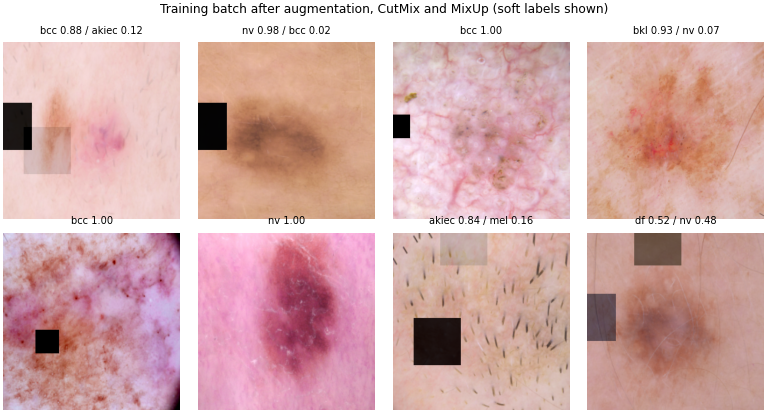

  saved figure: fig_augmentation_examples.png, fig_augmentation_examples.pdf
TTA verification: PASS (views = identity, h-flip, v-flip, rot90, rot270 of the clean test image; eval pipeline only)


In [15]:
# [RQ-01] Experiment registry
@dataclass(frozen=True)
class Exp:
    code: str
    name: str
    use_image: bool = True
    use_meta: bool = True
    use_cbam: bool = True
    resample: bool = False
    class_weight: bool = False
    minority_aug: bool = False
    mix: bool = False
    loss: str = "ce"
    two_phase: bool = True
    tta_eval: bool = False
    single_lr: float = 0.0          # peak LR if two_phase=False (0 -> CFG LR_P2)
    group: str = "core"
    priority: int = 1
    backbone: str = "effb3"         # "effb3" (SkinNet) or a benchmark backbone (Section 13)
    meta_features: tuple = ("age", "sex", "site")
    batch_size: int = 0             # 0 -> CFG BATCH_SIZE (batch-size sensitivity arms only)
    folds: tuple = ()               # () -> all folds; e.g. (1,) for single-fold checks
    p1_from: str = ""               # reuse the Phase-1 weights of this arm (identical Phase 1)
    rep: int = 0                    # repeated run index (reproducibility check)
    mix_mode: str = "both"          # "both" | "cutmix" | "mixup" (individual augmentation arms) [R7-4]
    optimizer: str = "adam"         # "adam" | "sgd" (optimiser ablation) [R1-5]
    precision: str = "mixed"        # "mixed" (FP16 compute) | "fp32" (mixed-precision ablation) [R2-M1]

SKN = dict(resample=True, class_weight=True, minority_aug=True)
EXPERIMENTS = {e.code: e for e in [
    Exp("A", "EfficientNetB3 only (image-only baseline)", use_meta=False, use_cbam=False),
    Exp("B", "EfficientNetB3 + Metadata", use_cbam=False),
    Exp("C", "EfficientNetB3 + CBAM", use_meta=False),
    Exp("D", "EfficientNetB3 + CBAM + Metadata"),
    Exp("E", "D + Imbalance strategy", **SKN),
    Exp("F", "E + MixUp/CutMix", mix=True, p1_from="E", **SKN),
    Exp("G", "E + Focal loss + Label smoothing", loss="focal_ls", **SKN),
    Exp("H", "Full SkinNet", mix=True, loss="focal_ls", tta_eval=True, p1_from="G", **SKN),
    Exp("S1_1P", "Full SkinNet, single-phase fine-tuning", mix=True, loss="focal_ls", two_phase=False, group="supp", priority=2, **SKN),
    Exp("E_OS", "D + resampling + minority aug (no class weights)", resample=True, minority_aug=True, group="supp", priority=2),
    Exp("E_CW", "D + class weights only", class_weight=True, group="supp", priority=2),
    Exp("E_RS", "D + resampling only", resample=True, group="supp", priority=3),
    Exp("G_F", "E + Focal loss only", loss="focal", group="supp", priority=3, **SKN),
    Exp("G_LS", "E + Label smoothing only (CE)", loss="ce_ls", group="supp", priority=3, **SKN),
    Exp("F_CM", "E + CutMix only", mix=True, mix_mode="cutmix", p1_from="E", group="supp", priority=2, **SKN),
    Exp("F_MU", "E + MixUp only", mix=True, mix_mode="mixup", p1_from="E", group="supp", priority=2, **SKN),
    Exp("H_SGD", "Full SkinNet, SGD + Nesterov instead of Adam", mix=True, loss="focal_ls", optimizer="sgd", group="supp", priority=2, **SKN),
    Exp("H_FP32", "Full SkinNet, FP32 training (no mixed precision)", mix=True, loss="focal_ls", precision="fp32", folds=(1,),
        group="repro", priority=2, **SKN),
    Exp("M0", "Metadata-only baseline (CE)", use_image=False, two_phase=False, single_lr=CFG["LR_P1"], group="meta", priority=1),
    Exp("M1", "Metadata-only + imbalance + focal/LS", use_image=False, two_phase=False, single_lr=CFG["LR_P1"],
        resample=True, class_weight=True, loss="focal_ls", group="meta", priority=2),
    # ---- reproducibility and batch-size checks (fold 1 only) [R4-9, R3 minor, R6] ----
    Exp("H_REP", "Full SkinNet, repeated run (same seed)", mix=True, loss="focal_ls", folds=(1,), rep=1, group="repro", priority=2, **SKN),
    Exp("H_BS8", "Full SkinNet, batch size 8", mix=True, loss="focal_ls", folds=(1,), batch_size=8, group="bs", priority=3, **SKN),
    Exp("H_BS32", "Full SkinNet, batch size 32", mix=True, loss="focal_ls", folds=(1,), batch_size=32, group="bs", priority=3, **SKN),
    # ---- metadata leave-one-feature-out (retrained) [R7-3] ----
    Exp("H_noAge", "Full SkinNet without age", mix=True, loss="focal_ls", meta_features=("sex", "site"), group="metafeat", priority=3, **SKN),
    Exp("H_noSex", "Full SkinNet without sex", mix=True, loss="focal_ls", meta_features=("age", "site"), group="metafeat", priority=3, **SKN),
    Exp("H_noSite", "Full SkinNet without anatomical site", mix=True, loss="focal_ls", meta_features=("age", "sex"), group="metafeat", priority=3, **SKN),
    # ---- benchmarks retrained under the same protocol [R1-6, R3-5, R4-10] ----
    *[Exp(code, f"{BACKBONES[bb][3]} + metadata (same training protocol)", use_cbam=False, mix=True, loss="focal_ls",
          backbone=bb, group="bench", priority=2, **SKN)
      for code, bb in [("BM_R50", "resnet50"), ("BM_D121", "densenet121"), ("BM_V2S", "effv2s"), ("BM_VIT", "vit_b16"), ("BM_CNXT", "convnext_tiny")]],
]}
PROFILES = {"core": ["M0", "A", "B", "C", "D", "E", "F", "G", "H", "S1_1P", "H_REP"]}
# "reviewer": every experiment a reviewer asked for (component decompositions R2-M1/R7-4, optimiser R1-5,
#             mixed precision R2-M1, benchmarks R1-6/R3-5 = classic CNN, modern CNN, transformer)
PROFILES["reviewer"] = PROFILES["core"] + ["E_OS", "E_CW", "E_RS", "G_F", "G_LS", "F_CM", "F_MU", "H_SGD", "H_FP32",
                                           "BM_R50", "BM_VIT", "BM_CNXT"]
PROFILES["full"] = PROFILES["reviewer"] + ["M1", "BM_D121", "BM_V2S", "H_noAge", "H_noSex", "H_noSite", "H_BS8", "H_BS32"]
try:
    import keras_hub  # noqa: F401
    KERAS_HUB_OK = True
except Exception as _e:
    KERAS_HUB_OK = False
    print("KerasHub not available: BM_VIT cannot be trained in this session.", _e)
VIT_READY = KERAS_HUB_OK and (SYNTHETIC or vit_preset_source() != CFG["VIT_PRESET"])
if not SYNTHETIC:
    print("ViT-B/16 preset:", vit_preset_source() if VIT_READY else
          "NOT ATTACHED -> BM_VIT is skipped. Attach it: Add Input -> Models -> keras/vit -> Keras -> vit_base_patch16_224_imagenet")
def exp_folds(exp):
    return [f for f in range(1, CFG["N_FOLDS"] + 1) if not exp.folds or f in exp.folds]
# Evaluation-only configurations derived from H
EVAL_ALIASES = {"I": ("H", "test", "Full SkinNet without TTA"), "J": ("H", "test_tta", "Full SkinNet with TTA")}
TABLE_ORDER = list("ABCDEFGHIJ") + ["S1_1P", "E_OS", "E_CW", "E_RS", "G_F", "G_LS", "F_CM", "F_MU", "H_SGD", "M0", "M1",
                                    "H_noAge", "H_noSex", "H_noSite", "BM_R50", "BM_D121", "BM_V2S", "BM_VIT", "BM_CNXT"]
SINGLE_FOLD_CHECKS = ["H_REP", "H_BS8", "H_BS32", "H_FP32"]     # reported in Sections 21A/21B, not in the ablation table

def exp_hash(exp):
    keys = ["IMG_SIZE", "BATCH_SIZE", "EPOCHS_P1", "EPOCHS_P2", "WARMUP_EPOCHS", "LR_P1", "LR_P2", "PATIENCE_P1", "PATIENCE_P2",
            "MIN_STEPS", "TARGET_PER_CLASS", "MAX_OVERSAMPLE_X", "CUTMIX_PROB", "MIXUP_PROB", "MIXUP_ALPHA", "LOC_ENCODING",
            "CLASS_WEIGHT_MODE", "MIXUP_LAMBDA_MODE", "SELECTION_METRIC", "FOCAL_GAMMA", "FOCAL_ALPHA", "LABEL_SMOOTHING", "SEED",
            "TEST_SPLIT_MODE", "N_FOLDS", "STEPS_PER_EPOCH", "BACKBONE_WEIGHTS"] + (["VIT_PRESET", "VIT_SIZE"] if exp.backbone == "vit_b16" else [])
    blob = json.dumps({"exp": asdict(exp), "cfg": {k: CFG.get(k) for k in keys}}, sort_keys=True, default=str)
    return hashlib.sha1(blob.encode()).hexdigest()[:12]

registry_df = pd.DataFrame([{**asdict(e), "hash": exp_hash(e)} for e in EXPERIMENTS.values()])
with open(DIRS["config"] / "experiments.json", "w") as f:
    json.dump({"experiments": registry_df.to_dict("records"), "eval_aliases": EVAL_ALIASES}, f, indent=2)
display(registry_df[["code", "name", "backbone", "use_meta", "use_cbam", "resample", "class_weight", "minority_aug", "mix", "loss", "two_phase", "meta_features", "group", "priority"]])
print("Run profiles:", {k: len(v) for k, v in PROFILES.items()}, "| selected:", CFG["RUN_PROFILE"])

# ---- augmented training examples (Full SkinNet pipeline, fold 1, phase-2 mixing) ----
_tr, _, _ = get_fold_frames(1)
_mp = MetaPreprocessor(CFG["LOC_ENCODING"]).fit(_tr)
_rs, _ = smart_oversample(_tr, CFG["TARGET_PER_CLASS"], CFG["MAX_OVERSAMPLE_X"], SEED)
_d, _l = _mp.transform(_rs)
_x, _y = next(iter(make_train_dataset(_rs, _d, _l, EXPERIMENTS["H"], apply_mix=True, seed=SEED)))
fig, axs = plt.subplots(2, 4, figsize=(FIG_W2, 3.9))
for i, ax in enumerate(axs.flat):
    ax.imshow(np.clip(_x["image_input"][i].numpy() / 255.0, 0, 1)); ax.axis("off")
    top = np.argsort(-_y[i].numpy())[:2]
    ax.set_title(" / ".join(f"{CLASS_NAMES[t]} {_y[i][t]:.2f}" for t in top if _y[i][t] > 0.005), fontsize=6.5)
fig.suptitle("Training batch after augmentation, CutMix and MixUp (soft labels shown)", fontsize=8)
fig.tight_layout()
save_fig(fig, "fig_augmentation_examples")
del _x, _y

# ---- [RQ-09] TTA pipeline verification: each view is the stated transform of the clean image ----
_te = test_df.iloc[:8]; _dte, _lte = _mp.transform(_te)
_views = [next(iter(make_eval_dataset(_te, _dte, _lte, EXPERIMENTS["H"], tta_view=v)))[0]["image_input"].numpy()
          for v in range(CFG["TTA_VIEWS"])]
if CFG["TTA_MODE"] == "deterministic":
    _ref = [lambda a: a, lambda a: a[:, :, ::-1], lambda a: a[:, ::-1], lambda a: np.rot90(a, 1, axes=(1, 2)), lambda a: np.rot90(a, 3, axes=(1, 2))]
    assert all(np.allclose(_views[v], _ref[v](_views[0])) for v in range(CFG["TTA_VIEWS"])), "TTA views are not the stated transforms"
    assert all(not np.allclose(_views[v], _views[0]) for v in range(1, CFG["TTA_VIEWS"])), "a TTA view equals the clean image"
    print("TTA verification: PASS (views = identity, h-flip, v-flip, rot90, rot270 of the clean test image; eval pipeline only)")
del _views

## 14A. Training sessions and progress monitor (reporting only)
**Purpose.** Make the training run easy to follow on Kaggle: which session, model, fold, phase and epoch are running on which GPU, how much is done, and how long the rest will take.

**What this cell does *not* change.** Nothing in the experiment: architectures, data, splits, folds, preprocessing, augmentation, losses, optimiser, learning rates, batch size, epochs, seeds, metrics, checkpoint selection and the GPU scheduling are exactly as before. The queue order is unchanged; *sessions* are labels over consecutive groups of that queue. With two GPUs, the next session can already start on a free GPU while the other GPU finishes the previous one.

**Sessions** (only arms selected by the run profile are shown):
1. Baselines and architecture ablations: M0, M1, A, B, C, D
2. Imbalance, augmentation, loss and training-strategy ablations: E–H and their decompositions, S1_1P, H_REP, batch-size and metadata-feature arms
3. Benchmark models under the same protocol: BM_*

**How it works.** The training code emits small events (unit start/end, phase start/end, epoch, stop, failure) to `runs/_live/events.jsonl`. Background GPU workers write events to that file; the main notebook renders them as complete, labelled blocks (so output from two GPUs never interleaves inside a block) and keeps a live status board. The ETA uses the measured durations of finished fold-runs (same model if available, otherwise all models) divided by the number of GPUs. `MON_LEVEL = "fold"` hides the per-epoch blocks.

In [16]:
# [MONITOR] Sessions, events and progress display (reporting only; no influence on training)
MON_LEVEL = "epoch"            # "epoch": every epoch; "fold": fold/phase level only
STATUS_EVERY_MIN = 10          # a text status board is printed at this interval (the live board updates continuously)
SESSION_PLAN = [
    ("BASELINES AND ARCHITECTURE ABLATIONS", ["M0", "M1", "A", "B", "C", "D"]),
    ("IMBALANCE, AUGMENTATION, LOSS AND TRAINING-STRATEGY ABLATIONS",
     ["E", "E_OS", "E_CW", "E_RS", "F", "F_CM", "F_MU", "G", "G_F", "G_LS", "H", "S1_1P", "H_SGD", "H_REP", "H_FP32",
      "H_BS8", "H_BS32", "H_noAge", "H_noSex", "H_noSite"]),
    ("BENCHMARK MODELS (SAME PROTOCOL)", ["BM_R50", "BM_D121", "BM_V2S", "BM_VIT", "BM_CNXT"]),
]
GPU_LABEL = os.environ.get("SKINNET_WORKER_ID", "0" if GPUS else "CPU")
LIVE_DIR = DIRS["runs"] / "_live"; LIVE_DIR.mkdir(parents=True, exist_ok=True)
EVENTS_PATH = LIVE_DIR / "events.jsonl"
MONITOR = None                 # set by the run controller in the main notebook
LINE = "─" * 64

def session_of(code):
    for i, (_, codes) in enumerate(SESSION_PLAN):
        if code in codes:
            return i
    return len(SESSION_PLAN) - 1

def hms(sec):
    if sec is None or not np.isfinite(sec):
        return "--:--:--"
    sec = int(round(sec)); return f"{sec // 3600:02d}:{sec % 3600 // 60:02d}:{sec % 60:02d}"

def pbar(frac, width=24):
    frac = min(max(frac, 0.0), 1.0); n = int(round(frac * width))
    return "[" + "█" * n + "░" * (width - n) + f"] {frac * 100:3.0f}%"

def phase_name(code, phase):
    e = EXPERIMENTS[code]
    if not e.two_phase:
        return "Training (metadata network)" if not e.use_image else "Single-phase fine-tuning"
    return "Head training (frozen backbone)" if phase == 1 else "Fine-tuning (backbone unfrozen, BatchNorm frozen)"

def phase_counter(code, phase):
    return f"{phase}/2" if EXPERIMENTS[code].two_phase else "1/1"

def _jsonable(v):
    if isinstance(v, (np.floating, np.integer)):
        return v.item()
    return v

def emit(kind, **kw):
    """Record a progress event. Reporting only: never alters training state."""
    rec = {"t": time.time(), "gpu": GPU_LABEL, "kind": kind, **{k: _jsonable(v) for k, v in kw.items()}}
    try:
        with open(EVENTS_PATH, "a") as f:
            f.write(json.dumps(rec, default=str) + "\n")
    except Exception:
        pass
    mon = MONITOR if MONITOR is not None else _WORKER_MON
    if mon is not None:
        mon.handle(rec)

def unit_is_done(code, fold):
    st_ = read_status(DIRS["runs"] / code / f"fold_{fold}")
    return bool(st_.get("done")) and st_.get("hash") == exp_hash(EXPERIMENTS[code])

def best_val_metrics(code, fold):
    """Validation metrics of the saved (best) checkpoint of the final phase, read from the stored history."""
    d = DIRS["runs"] / code / f"fold_{fold}"; st_ = read_status(d)
    ph = 2
    hp = d / f"history_p{ph}.csv"
    if not hp.exists() or not st_.get(f"p{ph}_best_epoch"):
        return None
    h_ = pd.read_csv(hp); r_ = h_[h_.epoch == st_[f"p{ph}_best_epoch"]]
    if r_.empty:
        return None
    r_ = r_.iloc[-1]
    return dict(val_macro_auc=float(r_.val_macro_auc), val_bal_acc=float(r_.val_bal_acc), val_macro_f1=float(r_.val_macro_f1),
                best_epoch=int(st_[f"p{ph}_best_epoch"]))

class Monitor:
    """Renders progress events as labelled blocks and keeps overall / per-GPU status and ETA."""
    def __init__(self, queue, n_workers=1, t0=None, live_board=True, echo=True):
        self.queue = list(queue); self.total = len(self.queue)
        self.n_workers = max(1, n_workers); self.t0 = t0 or time.time(); self.echo = echo
        self.running, self.durations = {}, {}          # gpu -> state; code -> [seconds of fold-runs finished in this run]
        self.sessions_started, self.sessions_done, self.models_reported = set(), set(), set()
        self.session_t0 = {}
        self.refresh()
        self.done_at_start = set(self.done)
        self.models_reported = {c for c in self.codes() if all(u in self.done for u in self.units_of(c))}
        self.last_board = time.time(); self.handle_board = None
        if live_board:
            try:
                from IPython.display import display as _d, Pretty
                self._Pretty = Pretty; self.handle_board = _d(Pretty(self.board()), display_id=True)
            except Exception:
                self.handle_board = None

    # ---------- bookkeeping ----------
    def codes(self):
        return list(dict.fromkeys(c for c, _ in self.queue))
    def units_of(self, code):
        return [(c, f) for c, f in self.queue if c == code]
    def refresh(self):
        self.done = {u for u in self.queue if unit_is_done(*u)}
    def session_units(self, s):
        return [u for u in self.queue if session_of(u[0]) == s]
    def active_sessions(self):
        return sorted({session_of(c) for c in self.codes()})
    def fold_label(self, code, fold):
        folds = exp_folds(EXPERIMENTS[code])
        return f"{fold}/{len(folds)}" if len(folds) > 1 else f"{fold} (single-fold check)"
    def est_unit_seconds(self, code):
        if self.durations.get(code):
            return float(np.mean(self.durations[code]))
        prev = [read_status(DIRS["runs"] / c / f"fold_{f}").get("unit_seconds") for c, f in self.units_of(code) if (c, f) in self.done]
        prev = [p for p in prev if p]
        if prev:
            return float(np.mean(prev))
        allv = [x for v in self.durations.values() for x in v]
        return float(np.mean(allv)) if allv else None
    def eta(self):
        pending = [u for u in self.queue if u not in self.done]
        if not pending:
            return 0.0
        tot = 0.0
        for c, f in pending:
            e = self.est_unit_seconds(c)
            if e is None:
                return None
            r = next((s for s in self.running.values() if s.get("code") == c and s.get("fold") == f), None)
            tot += max(e - (time.time() - r["t_unit"]), 0.0) if r else e
        return tot / self.n_workers
    def avg_fold(self):
        allv = [x for v in self.durations.values() for x in v]
        return float(np.mean(allv)) if allv else None
    def current_session(self):
        run_s = [session_of(s["code"]) for s in self.running.values() if s.get("code")]
        if run_s:
            return min(run_s)
        pend = [session_of(c) for c, f in self.queue if (c, f) not in self.done]
        return min(pend) if pend else (self.active_sessions()[-1] if self.active_sessions() else 0)

    # ---------- output ----------
    def out(self, text):
        if self.echo:
            print(text, flush=True)
    def plan(self):
        sess = self.active_sessions(); lines = ["=" * 64, "SKINNET TRAINING PLAN", "=" * 64]
        for k, s in enumerate(sess):
            us = self.session_units(s); nd = sum(u in self.done for u in us)
            lines.append(f"SESSION {k + 1}/{len(sess)} — {SESSION_PLAN[s][0]}   ({nd}/{len(us)} fold-runs done)")
            for c in [c for c in self.codes() if session_of(c) == s]:
                marks = " ".join("✓" if u in self.done else "○" for u in self.units_of(c))
                n_d = sum(u in self.done for u in self.units_of(c))
                lines.append(f"   {c:<9} {EXPERIMENTS[c].name[:44]:<44} {marks}  ({n_d}/{len(self.units_of(c))})")
        lines += ["", f"Total fold-runs: {self.total} | already completed: {len(self.done)} | to run: {self.total - len(self.done)}",
                  f"GPU workers: {self.n_workers}      Legend: ✓ completed (skipped, resumable)   ○ pending", "=" * 64]
        self.out("\n".join(lines))
    def session_header(self, s):
        sess = self.active_sessions(); us = self.session_units(s); codes = [c for c in self.codes() if session_of(c) == s]
        self.session_t0[s] = time.time()
        self.out("\n" + "=" * 64 + f"\nSESSION {sess.index(s) + 1}/{len(sess)} — {SESSION_PLAN[s][0]}\n" + "=" * 64 +
                 f"\nModels          : {len(codes)}  ({', '.join(codes)})\nFold-runs       : {len(us)}  "
                 f"(already completed: {sum(u in self.done for u in us)})\nStatus          : RUNNING\n" + "=" * 64)
    def board(self):
        n_d = len(self.done); s = self.current_session(); sess = self.active_sessions()
        lines = ["=" * 64, "SKINNET TRAINING STATUS", "=" * 64,
                 f"Overall   : {n_d} / {self.total} fold-runs   {pbar(n_d / max(self.total, 1))}",
                 f"Session   : {(sess.index(s) + 1) if s in sess else '-'} / {len(sess)} — {SESSION_PLAN[s][0] if sess else ''}",
                 f"Completed : {n_d}      Remaining : {self.total - n_d}",
                 f"Elapsed   : {hms(time.time() - self.t0)}      ETA : {hms(self.eta()) if self.eta() is not None else 'estimating after the first fold-run'}",
                 LINE]
        for g in sorted(self.running, key=str):
            r = self.running[g]
            if not r.get("code"):
                lines.append(f"GPU {g}  idle"); continue
            ep = f"Epoch {r.get('epoch', 0)}/{r.get('n_epochs', '?')}" if r.get("phase") else "starting"
            best = f"best val mAUC {r['best']:.4f}" if r.get("best") is not None else ""
            lines.append(f"GPU {g}  └── {r['code']} — Fold {self.fold_label(r['code'], r['fold'])} — "
                         f"Phase {phase_counter(r['code'], r.get('phase') or 1)} — {ep}  {best}")
            lines.append(f"        {EXPERIMENTS[r['code']].name[:52]}  | fold time {hms(time.time() - r['t_unit'])}")
        lines.append("=" * 64)
        return "\n".join(lines)
    def update_board(self, force_print=False):
        if self.handle_board is not None:
            try: self.handle_board.update(self._Pretty(self.board()))
            except Exception: pass
        if force_print or (time.time() - self.last_board) / 60 >= STATUS_EVERY_MIN:
            self.out("\n" + self.board()); self.last_board = time.time()

    # ---------- events ----------
    def handle(self, r):
        k, g = r["kind"], r["gpu"]
        if k == "unit_start":
            self.refresh(); c, f = r["code"], r["fold"]; s = session_of(c)
            if s not in self.sessions_started:
                self.sessions_started.add(s); self.session_header(s)
            self.running[g] = dict(code=c, fold=f, t_unit=r["t"], phase=None, best=None)
            mdone = sum(u in self.done for u in self.units_of(c))
            self.out(f"\n{LINE}\nMODEL    : {c} — {EXPERIMENTS[c].name}\nFOLD     : {self.fold_label(c, f)}\n"
                     f"PROGRESS : model {mdone}/{len(self.units_of(c))} folds completed | overall {len(self.done)}/{self.total} fold-runs completed\n"
                     f"GPU      : {g}\n{LINE}\n[CHECKPOINT] → Fold {self.fold_label(c, f)} started")
        elif k == "phase_start":
            rr = self.running.setdefault(g, {}); rr.update(phase=r["phase"], epoch=0, n_epochs=r["epochs"], best=None)
            self.out(f"  GPU {g} │ {r['code']} │ Fold {self.fold_label(r['code'], r['fold'])} │ precision {r.get('policy', '?')}\n"
                     f"  PHASE {phase_counter(r['code'], r['phase'])} — {phase_name(r['code'], r['phase'])}\n"
                     f"  ├─ Max epochs : {r['epochs']}   Steps/epoch : {r['steps']}\n"
                     f"  ├─ LR (peak)  : {r['lr']:g}   MixUp/CutMix : {'on' if r['mix'] else 'off'}\n"
                     f"  └─ Trainable  : {r['trainable']:,} parameters")
        elif k == "phase_reused":
            self.out(f"  GPU {g} │ {r['code']} │ Fold {self.fold_label(r['code'], r['fold'])}\n"
                     f"  PHASE 1/2 — reused from {r['source']} (identical Phase 1)   [CHECKPOINT] ✓ Phase 1 completed")
        elif k == "epoch":
            rr = self.running.setdefault(g, {}); rr.update(epoch=r["epoch"], n_epochs=r["n_epochs"])
            if r["saved"]:
                rr["best"] = r["val_macro_auc"] if CFG["SELECTION_METRIC"] == "val_macro_auc" else rr.get("best")
            if MON_LEVEL == "epoch":
                ck = "✓ SAVED (new best)" if r["saved"] else f"— not improved ({r['wait']}/{r['patience']} patience)"
                self.out(f"  GPU {g} │ {r['code']} │ Fold {self.fold_label(r['code'], r['fold'])} │ Phase {phase_counter(r['code'], r['phase'])} │ "
                         f"Epoch {r['epoch']}/{r['n_epochs']} │ Steps {r['steps']}/{r['steps']} │ {r['seconds']:.0f} s\n"
                         f"  ├─ Train Loss : {r['loss']:.4f}\n  ├─ Val mAUC   : {r['val_macro_auc']:.4f}\n"
                         f"  ├─ Val BalAcc : {r['val_bal_acc']:.4f}\n  ├─ Val mF1    : {r['val_macro_f1']:.4f}\n  └─ Checkpoint : {ck}")
        elif k == "phase_end":
            stop = " (early stopping)" if r["epochs_run"] < r["epochs"] else ""
            self.out(f"  [CHECKPOINT] ✓ Phase {phase_counter(r['code'], r['phase'])} completed — {r['epochs_run']} epochs{stop} — "
                     f"best epoch {r['best_epoch']} (val mAUC {r['best']:.4f}) — {hms(r['seconds'])}")
        elif k == "unit_end":
            c, f = r["code"], r["fold"]; self.durations.setdefault(c, []).append(r["seconds"]); self.running[g] = {}
            self.refresh(); mdone = sum(u in self.done for u in self.units_of(c)); eta = self.eta()
            self.out(f"  [CHECKPOINT] ✓ Fold {self.fold_label(c, f)} completed — best checkpoint saved (best_p2.weights.h5)\n"
                     f"  TIME     : elapsed {hms(time.time() - self.t0)} | this fold {hms(r['seconds'])} | "
                     f"average fold {hms(self.avg_fold())} | ETA {hms(eta) if eta is not None else 'estimating'}\n"
                     f"  OVERALL  : {pbar(len(self.done) / max(self.total, 1))}  {len(self.done)}/{self.total} fold-runs | "
                     f"model {c}: {mdone}/{len(self.units_of(c))}")
            if c not in self.models_reported and all(u in self.done for u in self.units_of(c)):
                self.models_reported.add(c); self.model_summary(c)
            s = session_of(c)
            if s not in self.sessions_done and all(u in self.done for u in self.session_units(s)):
                self.sessions_done.add(s); sess = self.active_sessions()
                self.out(f"\n{'=' * 64}\n✓ SESSION {sess.index(s) + 1}/{len(sess)} COMPLETE — {SESSION_PLAN[s][0]}   "
                         f"(session time {hms(time.time() - self.session_t0.get(s, self.t0))})\n{'=' * 64}")
            self.update_board(force_print=False)
        elif k == "unit_fail":
            self.running[g] = {}
            self.out(f"  ⚠ FAILED  GPU {g} │ {r['code']} │ Fold {self.fold_label(r['code'], r['fold'])} │ {r['error']}")
        elif k in ("stop", "warn"):
            self.out(f"  ⚠ GPU {g}: {r['message']}")
        if k in ("phase_start", "epoch", "unit_start"):
            self.update_board()
    def model_summary(self, c):
        rows = [(f, best_val_metrics(c, f)) for _, f in self.units_of(c)]
        rows = [(f, m) for f, m in rows if m]
        lines = [f"\n{'=' * 64}", f"MODEL COMPLETE: {c}", "=" * 64, EXPERIMENTS[c].name, "",
                 f"Folds completed : {len(self.units_of(c))} / {len(self.units_of(c))}"]
        if rows:
            lines += [f"Mean Val mAUC   : {np.mean([m['val_macro_auc'] for _, m in rows]):.4f}",
                      f"Mean Val BalAcc : {np.mean([m['val_bal_acc'] for _, m in rows]):.4f}",
                      f"Mean Val mF1    : {np.mean([m['val_macro_f1'] for _, m in rows]):.4f}"]
            fb, mb = max(rows, key=lambda t: t[1]["val_macro_auc"])
            lines += [f"Best fold       : {fb}  (val mAUC {mb['val_macro_auc']:.4f})",
                      "Per fold (val, saved checkpoint): " + "  ".join(f"f{f}={m['val_macro_auc']:.4f}" for f, m in rows),
                      "(validation values of the selected checkpoints; test metrics are computed in Section 18)"]
        lines += ["", "Status: ✓ COMPLETE", "=" * 64]
        self.out("\n".join(lines))
    def final_summary(self):
        self.refresh(); sess = self.active_sessions(); codes = self.codes()
        s_done = sum(all(u in self.done for u in self.session_units(s)) for s in sess)
        m_done = sum(all(u in self.done for u in self.units_of(c)) for c in codes)
        complete = len(self.done) == self.total
        lines = ["\n" + "=" * 64, "SKINNET TRAINING COMPLETE" if complete else ("SKINNET TRAINING FINISHED WITH FAILURES" if any((DIRS["runs"] / c / f"fold_{f}" / "failed.json").exists() for c, f in self.queue) else "SKINNET TRAINING STOPPED (resume in the next session)"), "=" * 64,
                 f"Sessions completed : {s_done} / {len(sess)}", f"Models completed   : {m_done} / {len(codes)}",
                 f"Fold-runs          : {len(self.done)} / {self.total}   (this run: {len(self.done - self.done_at_start)})",
                 f"Total time         : {hms(time.time() - self.t0)}", "", "MODEL STATUS"]
        failed = [(c, f) for c, f in self.queue if (DIRS["runs"] / c / f"fold_{f}" / "failed.json").exists() and (c, f) not in self.done]
        for c in codes:
            n_d = sum(u in self.done for u in self.units_of(c)); n = len(self.units_of(c)); n_f = sum(u in failed for u in self.units_of(c))
            mark = "✓" if n_d == n else ("✗" if n_f else ("◐" if n_d else "○"))
            lines.append(f"{mark} {c:<9} — {n_d}/{n} folds" + (f", {n_f} FAILED" if n_f else "") + f"   {EXPERIMENTS[c].name[:40]}")
        if failed:
            lines += ["", f"⚠ FAILED fold-runs ({len(failed)}) — they are retried in the next session:"]
            for c, f in failed:
                err = json.loads((DIRS["runs"] / c / f"fold_{f}" / "failed.json").read_text()).get("error", "")
                lines.append(f"   ✗ {c} fold {f}: {err[:160]}")
        lines += ["", "Results saved to:", f"  {DIRS['runs']}  (checkpoints, predictions, histories)", f"  {DIRS['results']}  (tables)",
                  f"Disk free: {shutil.disk_usage(WORK).free / 2**30:.1f} GB", "=" * 64]
        self.out("\n".join(lines))
        self.update_board()

# a worker renders its own events into its log file (overall counts are read from the shared status files)
_WORKER_MON = None

## 15. Training engine (checkpointing, early stopping, resumable units)
**Request:** RQ-12 (checkpoints, resumability, memory hygiene), RQ-04 (model selection on validation only), fixes finding F1.

**Purpose.** Train one *unit* = (experiment, fold) and save everything needed to evaluate it without re-training.

**Implementation details.**
* `ValMonitor` runs after every epoch on the **validation fold only**. It computes macro one-vs-rest ROC-AUC (the selection metric), balanced accuracy, macro-F1 and unweighted validation cross-entropy, appends a row to `history_p{phase}.csv`, saves the weights **only when the selection metric increases** (explicit maximisation, fixing F1) and stops after `patience` epochs without improvement. Keras' own validation pass is disabled, so validation is computed once per epoch.
* After each phase, the best weights are re-loaded. Phase 2 starts from the best Phase-1 weights. The final evaluated model is identical to the saved `best_p2.weights.h5`.
* **Resumability:** `status.json` records completed phases and the configuration hash. A unit interrupted during Phase 2 resumes from the saved best Phase-1 weights, so at most one phase is repeated. A completed unit is never re-trained.
* **Outputs per unit:** `preds_val.npz` (validation fold), `preds_test.npz` (clean test), `preds_test_tta.npz` for H (all TTA views stored individually), histories, timings and peak GPU memory.
* **Memory:** one model per unit, `clear_keras_session()`, `gc.collect()` and `malloc_trim` between units; host RAM is logged per unit and the run controller stops starting new units above `MAX_HOST_RAM_FRAC` of system RAM (resume in a new session). Images stream from the memory-mapped cache; nothing is loaded wholesale into GPU memory.
* **Selection bias note:** the validation fold drives early stopping and checkpoint selection, so fold-validation metrics are optimistically biased. The untouched **test set** is the primary estimate.

**Expected output.** None when defined; used by the Run Controller.

In [17]:
# [RQ-12][RQ-04] Training engine
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, f1_score, log_loss
import ctypes

def host_rss_gb():
    """Resident host memory of this kernel (GB)."""
    try:
        with open("/proc/self/status") as f:
            for line in f:
                if line.startswith("VmRSS"):
                    return int(line.split()[1]) / 1024**2
    except Exception:
        pass
    return float("nan")

def release_host_memory():
    """Free Python/TF objects and return freed heap pages to the OS (limits RAM growth across units)."""
    gc.collect()
    try:
        ctypes.CDLL("libc.so.6").malloc_trim(0)
    except Exception:
        pass

def macro_auc_safe(y, probs):
    aucs = []
    for c in range(N_CLASSES):
        yc = (y == c).astype(int)
        if 0 < yc.sum() < len(yc):
            aucs.append(roc_auc_score(yc, probs[:, c]))
    return float(np.mean(aucs)) if aucs else float("nan")

def _brier_fn(y_true, y_pred):
    return keras.ops.sum(keras.ops.square(keras.ops.cast(y_pred, "float32") - keras.ops.cast(y_true, "float32")), axis=-1)

@keras.saving.register_keras_serializable(package="skinnet")
class BrierScore(keras.metrics.MeanMetricWrapper):
    """Multi-class Brier score, sum_c (p_c - y_c)^2, on the (possibly mixed) training targets [R6]."""
    def __init__(self, name="brier", dtype=None):
        super().__init__(fn=_brier_fn, name=name, dtype=dtype)
    def get_config(self):
        return {"name": self.name, "dtype": self.dtype}

def predict_probs(model, ds):
    return model.predict(ds, verbose=0).astype(np.float32)

class ValMonitor(keras.callbacks.Callback):
    def __init__(self, val_ds, y_val, patience, best_path, hist_path, phase):
        super().__init__()
        self.val_ds, self.y_val, self.patience = val_ds, y_val, patience
        self.best_path, self.hist_path, self.phase = best_path, hist_path, phase
        self.best, self.best_epoch, self.wait = -np.inf, 0, 0
    def on_epoch_begin(self, epoch, logs=None):
        self.t0 = time.time()
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        pr = predict_probs(self.model, self.val_ds)
        yp = pr.argmax(1)
        row = dict(phase=self.phase, epoch=epoch + 1, train_loss=float(logs.get("loss", np.nan)),
                   train_acc=float(logs.get("accuracy", np.nan)), train_brier=float(logs.get("brier", np.nan)),
                   val_brier=float(np.mean(np.sum((pr - np.eye(N_CLASSES)[self.y_val]) ** 2, 1))),
                   val_macro_auc=macro_auc_safe(self.y_val, pr), val_bal_acc=balanced_accuracy_score(self.y_val, yp),
                   val_macro_f1=f1_score(self.y_val, yp, average="macro", zero_division=0),
                   val_ce=log_loss(self.y_val, np.clip(pr, 1e-7, 1), labels=list(range(N_CLASSES))),
                   lr=float(keras.ops.convert_to_numpy(self.model.optimizer.learning_rate)),
                   epoch_seconds=time.time() - self.t0)
        score = row[CFG["SELECTION_METRIC"]]
        improved = np.isfinite(score) and score > self.best + 1e-6
        if improved:
            self.best, self.best_epoch, self.wait = score, epoch + 1, 0
            self.model.save_weights(self.best_path)
        else:
            self.wait += 1
        row["improved"] = bool(improved)
        pd.DataFrame([row]).to_csv(self.hist_path, mode="a", header=not Path(self.hist_path).exists(), index=False)
        emit("epoch", code=getattr(self, "code", "?"), fold=getattr(self, "fold", 0), phase=self.phase, epoch=epoch + 1,
             n_epochs=self.params.get("epochs"), steps=self.params.get("steps"), loss=row["train_loss"],
             val_macro_auc=row["val_macro_auc"], val_bal_acc=row["val_bal_acc"], val_macro_f1=row["val_macro_f1"],
             saved=bool(improved), wait=self.wait, patience=self.patience, seconds=row["epoch_seconds"])
        if self.wait >= self.patience:
            self.model.stop_training = True

def unit_dir(code, fold, create=True):
    d = DIRS["runs"] / code / f"fold_{fold}"
    if create:
        d.mkdir(parents=True, exist_ok=True)
    return d

def read_status(d):
    p = d / "status.json"
    return json.load(open(p)) if p.exists() else {}

def write_status(d, st):
    with open(d / "status.json", "w") as f:
        json.dump(st, f, indent=2, default=float)

def save_preds(path, frame, probs, views=None):
    np.savez_compressed(path, image_id=np.array(frame.image_id.astype(str).tolist(), dtype="U"), lesion_id=np.array(frame.lesion_id.astype(str).tolist(), dtype="U"),
                        y_true=frame.label.values.astype(np.int16), probs=probs.astype(np.float32),
                        **({"view_probs": views.astype(np.float32)} if views is not None else {}))

TRAIN_PRED_EXPS = {"D", "E", "E_OS", "E_CW", "E_RS", "F", "F_CM", "F_MU", "G", "H"}   # overfitting / synthetic-pattern check [R7-4]

def compile_phase(model, exp, phase, steps, class_weights, epochs, peak_lr, min_lr):
    set_phase(model, phase)
    if getattr(exp, "optimizer", "adam") == "sgd":            # [R1-5] optimiser ablation: SGD needs a larger step size
        peak_lr, min_lr = peak_lr * CFG["SGD_LR_MULT"], min_lr * CFG["SGD_LR_MULT"]
    sched = CosineWarmupSchedule(peak_lr, CFG["WARMUP_EPOCHS"] * steps, epochs * steps, min_lr)
    loss = SkinNetLoss(**LOSS_SETTINGS[exp.loss], class_weights=class_weights, weight_mode=CFG["CLASS_WEIGHT_MODE"])
    opt = (keras.optimizers.SGD(learning_rate=sched, momentum=0.9, nesterov=True, clipnorm=CFG["GRAD_CLIP"])
           if getattr(exp, "optimizer", "adam") == "sgd" else keras.optimizers.Adam(learning_rate=sched, clipnorm=CFG["GRAD_CLIP"]))
    model.compile(optimizer=opt,
                  loss=loss, metrics=[keras.metrics.CategoricalAccuracy(name="accuracy"), BrierScore()])

def train_unit(exp, fold, verbose=True):
    """Precision wrapper [R2-M1]: FP32 arms train under a float32 policy; all other arms under the default policy."""
    if getattr(exp, "precision", "mixed") == "fp32":
        old = keras.mixed_precision.global_policy().name
        keras.mixed_precision.set_global_policy("float32")
        try:
            return _train_unit(exp, fold, verbose)
        finally:
            keras.mixed_precision.set_global_policy(old)
    return _train_unit(exp, fold, verbose)

def _train_unit(exp, fold, verbose=True):
    d = unit_dir(exp.code, fold)
    st = read_status(d)
    h = exp_hash(exp)
    if st.get("done"):
        if st.get("hash") != h:
            emit("warn", message=f"{exp.code} fold {fold} finished under a different configuration hash; not reused. Delete {d} to retrain.")
        return st
    if st and st.get("hash") != h:
        raise RuntimeError(f"{d} holds partial results from a different configuration. Delete it to retrain.")
    st.update(exp=exp.code, fold=fold, hash=h, started=st.get("started", time.strftime("%Y-%m-%d %H:%M:%S")))
    t_unit = time.time()
    set_seed(SEED + 10 * fold)                                    # identical seed per fold across arms (paired design)
    tr, va, te = get_fold_frames(fold)
    mp = MetaPreprocessor(CFG["LOC_ENCODING"], features=exp.meta_features).fit(tr)   # fitted on the raw training fold only
    cw = fold_class_weights(tr) if exp.class_weight else None
    tr_used = smart_oversample(tr, CFG["TARGET_PER_CLASS"], CFG["MAX_OVERSAMPLE_X"], SEED)[0] if exp.resample else tr
    bs = exp.batch_size or BATCH_SIZE
    steps = CFG.get("MAX_STEPS_OVERRIDE") or max(1, CFG["STEPS_PER_EPOCH"] * BATCH_SIZE // bs)   # same images per epoch for all arms
    d_tr, l_tr = mp.transform(tr_used); d_va, l_va = mp.transform(va); d_te, l_te = mp.transform(te)
    val_ds = make_eval_dataset(va, d_va, l_va, exp)
    st["dtype_policy"] = keras.mixed_precision.global_policy().name       # recorded for the audit (mixed_float16 expected)
    st.update(n_train_raw=len(tr), n_train_used=len(tr_used), n_val=len(va), n_test=len(te), steps_per_epoch=steps, batch_size=bs,
              gpu=HW.get("gpu_name"), meta_features=list(exp.meta_features), meta_feature_order=mp.feature_names(),
              class_weights=None if cw is None else cw.tolist(), meta_dim=mp.dense_dim, loc_vocab=mp.loc_vocab)

    clear_keras_session(); gc.collect()
    if GPUS:
        try: tf.config.experimental.reset_memory_stats("GPU:0")
        except Exception: pass
    model = build_skinnet(exp, mp.dense_dim, n_loc=len(mp.loc_vocab))
    if exp.two_phase:
        phases = [(1, CFG["EPOCHS_P1"], CFG["LR_P1"], CFG["MIN_LR_P1"], CFG["PATIENCE_P1"], False),
                  (2, CFG["EPOCHS_P2"], CFG["LR_P2"], CFG["MIN_LR_P2"], CFG["PATIENCE_P2"], exp.mix)]
    else:
        lr = exp.single_lr or CFG["LR_P2"]
        phases = [(2, CFG["EPOCHS_P1"] + CFG["EPOCHS_P2"], lr, CFG["MIN_LR_P2"], CFG["PATIENCE_P2"], exp.mix)]
    for i, (ph, epochs, lr, min_lr, patience, mix) in enumerate(phases):
        best_path, hist_path = d / f"best_p{ph}.weights.h5", d / f"history_p{ph}.csv"
        if st.get(f"p{ph}_done") and best_path.exists():
            model.load_weights(best_path); continue
        if i > 0:                                                 # start next phase from BEST previous weights
            model.load_weights(d / f"best_p{phases[i - 1][0]}.weights.h5")
        if ph == 1 and CFG["REUSE_P1"] and exp.p1_from:           # identical Phase 1 already trained by the source arm
            src = EXPERIMENTS[exp.p1_from]; sd = unit_dir(src.code, fold, create=False); sst = read_status(sd)
            if sst.get("p1_done") and sst.get("hash") == exp_hash(src) and (sd / "best_p1.weights.h5").exists():
                shutil.copy2(sd / "best_p1.weights.h5", best_path)
                if (sd / "history_p1.csv").exists():
                    shutil.copy2(sd / "history_p1.csv", hist_path)
                model.load_weights(best_path)
                st.update(p1_done=True, p1_source=src.code, p1_best_epoch=sst.get("p1_best_epoch"),
                          **{f"p1_best_{CFG['SELECTION_METRIC']}": sst.get(f"p1_best_{CFG['SELECTION_METRIC']}")},
                          p1_seconds=0.0, p1_trainable_params=sst.get("p1_trainable_params"), p1_nontrainable_params=sst.get("p1_nontrainable_params"))
                write_status(d, st)
                if verbose:
                    emit("phase_reused", code=exp.code, fold=fold, source=src.code)
                continue
        if hist_path.exists():
            hist_path.unlink()                                    # a phase is always re-run from its start
        compile_phase(model, exp, ph, steps, cw, epochs, lr, min_lr)
        tr_n, nt_n = count_params(model)
        if verbose:
            emit("phase_start", code=exp.code, fold=fold, phase=ph, epochs=epochs, steps=steps, lr=lr, mix=bool(mix), trainable=int(tr_n),
                 policy=keras.mixed_precision.global_policy().name)
        set_seed(SEED + 10 * fold + ph)                           # phase-specific seed: reuse and retraining are equivalent
        ds = make_train_dataset(tr_used, d_tr, l_tr, exp, apply_mix=mix, seed=SEED + 10 * fold + ph)
        mon = ValMonitor(val_ds, va.label.values, patience, best_path, hist_path, ph)
        mon.code, mon.fold = exp.code, fold                       # labels for the progress display only
        t0 = time.time()
        model.fit(ds, epochs=epochs, steps_per_epoch=steps, callbacks=[mon], verbose=0)
        model.load_weights(best_path)
        if verbose:
            emit("phase_end", code=exp.code, fold=fold, phase=ph, epochs=epochs, epochs_run=len(pd.read_csv(hist_path)),
                 best_epoch=mon.best_epoch, best=float(mon.best), seconds=time.time() - t0)
        st.update({f"p{ph}_done": True, f"p{ph}_best_epoch": mon.best_epoch, f"p{ph}_best_{CFG['SELECTION_METRIC']}": mon.best,
                   f"p{ph}_seconds": time.time() - t0, f"p{ph}_trainable_params": tr_n, f"p{ph}_nontrainable_params": nt_n})
        write_status(d, st)
    # ---------------- inference on the final (saved) weights ----------------
    t0 = time.time()
    save_preds(d / "preds_val.npz", va, predict_probs(model, val_ds))
    save_preds(d / "preds_test.npz", te, predict_probs(model, make_eval_dataset(te, d_te, l_te, exp)))
    st["inference_seconds_clean"] = time.time() - t0
    if exp.code in TRAIN_PRED_EXPS:                              # [R7-4] predictions on the raw (non-resampled) training fold
        d_trr, l_trr = mp.transform(tr)
        save_preds(d / "preds_train.npz", tr, predict_probs(model, make_eval_dataset(tr, d_trr, l_trr, exp)))
    if (exp.tta_eval or CFG["TTA_FOR_ALL_EXPERIMENTS"]) and exp.use_image:
        t0 = time.time()
        views = np.stack([predict_probs(model, make_eval_dataset(te, d_te, l_te, exp, tta_view=v)) for v in range(CFG["TTA_VIEWS"])])
        save_preds(d / "preds_test_tta.npz", te, views.mean(0), views=views)
        st["inference_seconds_tta"] = time.time() - t0
    # ---- external predictions (BCN20000) with the model already in memory [R7-2] ----
    if globals().get("BCN_CACHE") is not None and exp.code in set(CFG["EXT_EVAL_EXPS"]) | {"H"}:
        t0 = time.time()
        for kind, frame in [("ext", bcn_df), ("ext_nosite", bcn_df.assign(localization="unknown"))][: (2 if exp.code == "H" else 1)]:
            dx_, lx_ = mp.transform(frame)
            save_preds(d / f"preds_{kind}.npz", frame, predict_probs(model, make_eval_dataset(frame, dx_, lx_, exp, cache=BCN_CACHE)))
        if exp.code == "H":
            dx_, lx_ = mp.transform(bcn_df)
            views = np.stack([predict_probs(model, make_eval_dataset(bcn_df, dx_, lx_, exp, tta_view=v, cache=BCN_CACHE)) for v in range(CFG["TTA_VIEWS"])])
            save_preds(d / "preds_ext_tta.npz", bcn_df, views.mean(0), views=views)
        st["inference_seconds_external"] = time.time() - t0
    if GPUS:
        try: st["peak_gpu_mb"] = tf.config.experimental.get_memory_info("GPU:0")["peak"] / 2**20
        except Exception: pass
    p1_needed = any(e.p1_from == exp.code for e in EXPERIMENTS.values()) and CFG["REUSE_P1"]
    if not CFG["KEEP_P1_WEIGHTS"] and not p1_needed and exp.two_phase and (d / "best_p1.weights.h5").exists():
        (d / "best_p1.weights.h5").unlink()
    st.update(done=True, unit_seconds=st.get("unit_seconds", 0) + time.time() - t_unit, finished=time.strftime("%Y-%m-%d %H:%M:%S"),
              disk_free_gb=round(shutil.disk_usage(WORK).free / 2**30, 1))
    write_status(d, st)
    del model; clear_keras_session(); release_host_memory()
    return st

## 16. Run controller (edit this cell only)
**Request:** RQ-01 (execute the ablation), RQ-12 (session budget, resumability).

**Purpose.** Train the queued (experiment, fold) units in order, skip finished units, and stop starting new units before the Kaggle 12-hour session limit.

**How to use.**
* `CFG['RUN_PROFILE']` (Section 2) sets the queue; `RUN_EXPERIMENTS` / `RUN_FOLDS` here override it. I and J need no training (evaluated from H).
* **Two GPUs:** one background training process per GPU (`skinnet_worker.py`, generated from this notebook's own cells). Each process claims the next unfinished unit with a lock file, so both GPUs stay busy and no unit is trained twice. Progress lines are echoed here; full logs are in `logs/worker_gpu*.log`. With one GPU, units are trained in this kernel.
* Budget guard: a unit is started only if the session time used plus the mean duration of finished units of that arm stays below `SESSION_BUDGET_H`.
* Overrides: environment variables `SKINNET_RUN_EXPS="A,B"` and `SKINNET_RUN_FOLDS="1,2"`.

**Estimated cost on one T4** (probe notebook: EfficientNetB3 0.20 s/step full fine-tuning, 0.056 s/step frozen; 800 steps per epoch). One SkinNet unit ≈ 0.6–1.2 GPU-h depending on early stopping. `core` ≈ 35–45 GPU-h; the five benchmarks add ≈ 25–35 GPU-h (ConvNeXt-Tiny is ≈ 2.4× slower than EfficientNetB3). With **two T4s in parallel**, the `reviewer` profile needs ≈ 30–40 hours of session time, i.e. **3–4 Kaggle sessions**. These are estimates; the measured unit times are in `results/run_log.csv`.

**Expected output.** A progress log per unit and `results/run_log.csv`.

In [18]:
# [WORKER-SKIP]
# Source of the background training process (generated from this notebook's own cells when the notebook was built)
WORKER_SRC_B64 = "..."

In [19]:
# [RQ-01][RQ-12][R1-11] Run controller
RUN_TRAINING = True
RUN_EXPERIMENTS = list(PROFILES[CFG["RUN_PROFILE"]])
RUN_FOLDS = []                                     # [] = all folds of each arm
SMOKE_ONE_FOLD = set()                             # smoke test only: arms run on fold 1 (code-path check)
if SMOKE_TEST:                                     # every training code path of the reviewer profile once
    RUN_EXPERIMENTS = ["M0", "A", "D", "E", "G", "H", "S1_1P", "H_REP", "E_OS", "E_CW", "E_RS", "G_F", "G_LS", "F_CM", "F_MU",
                       "H_SGD", "H_FP32", "H_BS8", "H_noSite", "BM_R50", "BM_VIT", "BM_CNXT"]
    SMOKE_ONE_FOLD = {"E", "E_OS", "E_CW", "E_RS", "G_F", "G_LS", "F_CM", "F_MU", "H_SGD", "H_noSite"}
    if SYNTHETIC:
        RUN_EXPERIMENTS = ["M0", "A", "D", "E", "G", "H", "S1_1P", "H_REP", "F_CM", "H_SGD", "H_FP32", "BM_R50", "BM_VIT"]
if os.environ.get("SKINNET_RUN_EXPS"):
    RUN_EXPERIMENTS = os.environ["SKINNET_RUN_EXPS"].split(",")
if os.environ.get("SKINNET_RUN_FOLDS"):
    RUN_FOLDS = [int(x) for x in os.environ["SKINNET_RUN_FOLDS"].split(",")]
_skipped_vit = [c for c in RUN_EXPERIMENTS if c in EXPERIMENTS and EXPERIMENTS[c].backbone == "vit_b16" and not VIT_READY]
if _skipped_vit and not WORKER:
    print("⚠ ViT-B/16 preset not attached -> skipped:", _skipped_vit,
          "| Kaggle: Add Input -> Models -> keras/vit -> Keras -> vit_base_patch16_224_imagenet, then re-run.")
RUN_EXPERIMENTS = [c for c in RUN_EXPERIMENTS if c in EXPERIMENTS and c not in _skipped_vit]
QUEUE = [(c, f) for c in RUN_EXPERIMENTS for f in exp_folds(EXPERIMENTS[c])[: (1 if c in SMOKE_ONE_FOLD else None)]
         if not RUN_FOLDS or f in RUN_FOLDS]
SESSION_T0 = float(os.environ.get("SKINNET_SESSION_T0", globals().get("SESSION_T0", time.time())))

def done_unit_hours(code=None):
    hrs = []
    for p_ in DIRS["runs"].glob("*/fold_*/status.json"):
        s_ = read_status(p_.parent)
        if s_.get("done") and (code is None or s_.get("exp") == code) and EXPERIMENTS.get(s_.get("exp"), Exp("x", "x")).use_image:
            hrs.append(s_.get("unit_seconds", 0) / 3600)
    return float(np.mean(hrs)) if hrs else (done_unit_hours() if code is not None else 1.2)

def claim_unit(code, fold):
    lock = unit_dir(code, fold) / "claim.lock"
    try:
        fd = os.open(lock, os.O_CREAT | os.O_EXCL | os.O_WRONLY); os.write(fd, f"{os.getpid()} {time.time():.0f}".encode()); os.close(fd)
        return True
    except FileExistsError:
        return False

ONE_UNIT_PER_PROCESS = os.environ.get("SKINNET_ONE_UNIT", "0") == "1"   # workers: a fresh process per unit (frees all memory)

def failed_this_session(code, fold):
    return (unit_dir(code, fold, create=False) / "failed.json").exists()

def run_queue(queue, tag):
    """Returns 'unit' (one unit attempted and ONE_UNIT_PER_PROCESS), 'stop' (budget/RAM) or 'empty' (nothing left to claim)."""
    for code, fold in queue:
        exp = EXPERIMENTS[code]
        st = read_status(unit_dir(code, fold, create=False))
        if (st.get("done") and st.get("hash") == exp_hash(exp)) or failed_this_session(code, fold):
            continue
        rss = host_rss_gb()
        if HW.get("ram_gb") and rss > CFG["MAX_HOST_RAM_FRAC"] * HW["ram_gb"]:
            emit("stop", message=f"stopping: host RAM {rss:.1f} GB > {CFG['MAX_HOST_RAM_FRAC']:.0%} of {HW['ram_gb']} GB. Finished units are kept."); return "stop"
        elapsed = (time.time() - SESSION_T0) / 3600
        need = done_unit_hours(code) if exp.use_image else 0.05
        if elapsed + need > CFG["SESSION_BUDGET_H"]:
            emit("stop", message=f"stopping: {elapsed:.2f} h used; next unit needs ~{need:.2f} h (budget {CFG['SESSION_BUDGET_H']} h). Resume in a new session."); return "stop"
        if not claim_unit(code, fold):
            continue                                            # another GPU worker is training this unit
        emit("unit_start", code=code, fold=fold)
        t_u = time.time()
        try:
            st = train_unit(exp, fold)
            emit("unit_end", code=code, fold=fold, seconds=time.time() - t_u)
            pd.DataFrame([dict(exp=code, fold=fold, status="done", worker=tag, hours=st.get("unit_seconds", 0) / 3600, host_rss_gb=host_rss_gb(),
                               when=time.strftime("%Y-%m-%d %H:%M:%S"))]).to_csv(
                DIRS["runs"] / f"run_log_{tag}.csv", mode="a", header=not (DIRS["runs"] / f"run_log_{tag}.csv").exists(), index=False)
        except tf.errors.ResourceExhaustedError as e:
            emit("unit_fail", code=code, fold=fold, error=f"out of GPU memory: {str(e)[:200]}")
            clear_keras_session(); gc.collect(); raise
        except Exception as e:
            emit("unit_fail", code=code, fold=fold, error=f"{type(e).__name__}: {str(e)[:300]}")
            import traceback; traceback.print_exc()
            (unit_dir(code, fold) / "failed.json").write_text(json.dumps(dict(error=f"{type(e).__name__}: {str(e)[:1000]}", when=time.time())))
            clear_keras_session(); release_host_memory()
            if not SMOKE_TEST and not WORKER:
                raise
        finally:
            (unit_dir(code, fold) / "claim.lock").unlink(missing_ok=True)
        if ONE_UNIT_PER_PROCESS:
            return "unit"
    return "empty"

N_WORKERS = len(GPUS) if (CFG["PARALLEL_GPU_WORKERS"] and len(GPUS) >= 2 and not WORKER) else 0
if not WORKER and os.environ.get("SKINNET_FORCE_WORKERS"):          # testing only
    N_WORKERS = int(os.environ["SKINNET_FORCE_WORKERS"])
if WORKER:
    _WORKER_MON = Monitor(QUEUE, n_workers=int(os.environ.get("SKINNET_N_WORKERS", "1")), t0=SESSION_T0, live_board=False)
    _res = run_queue(QUEUE, f"gpu{os.environ.get('SKINNET_WORKER_ID', '0')}")
    sys.exit({"unit": 0, "stop": 3, "empty": 4}[_res])            # tells the main notebook whether to start a fresh worker
elif RUN_TRAINING and QUEUE:
    for lk in list(DIRS["runs"].glob("*/fold_*/claim.lock")) + list(DIRS["runs"].glob("*/fold_*/failed.json")):
        lk.unlink()                                             # stale claims / failure marks from an earlier session
    MONITOR = Monitor(QUEUE, n_workers=max(N_WORKERS, 1), t0=time.time())
    MONITOR.plan()
    _ev_offset = EVENTS_PATH.stat().st_size if EVENTS_PATH.exists() else 0     # ignore events of earlier sessions
    if N_WORKERS:
        import base64
        script = WORK / "skinnet_worker.py"
        script.write_text(base64.b64decode(WORKER_SRC_B64).decode("utf-8"))
        procs, procs_env = [], []
        for i in range(N_WORKERS):
            env = dict(os.environ, SKINNET_WORKER="1", SKINNET_WORKER_ID=str(i), CUDA_VISIBLE_DEVICES=str(i) if GPUS else "",
                       SKINNET_SMOKE_TEST="1" if SMOKE_TEST else "0", SKINNET_SYNTHETIC="1" if SYNTHETIC else "0",
                       SKINNET_SESSION_T0=str(SESSION_T0), SKINNET_RUN_EXPS=",".join(RUN_EXPERIMENTS),
                       SKINNET_RUN_FOLDS=",".join(map(str, RUN_FOLDS)), MPLBACKEND="Agg", TF_CPP_MIN_LOG_LEVEL="3",
                       SKINNET_N_WORKERS=str(N_WORKERS), SKINNET_ONE_UNIT="1")
            if not RUN_FOLDS:
                env.pop("SKINNET_RUN_FOLDS")
            procs_env.append(env)
            logf = open(DIRS["logs"] / f"worker_gpu{i}.log", "a")
            procs.append((subprocess.Popen([sys.executable, str(script)], env=env, stdout=logf, stderr=subprocess.STDOUT, cwd=str(WORK)), logf))
            time.sleep(20)                                      # stagger start-up (cache opening, weight download)
        print(f"Started {N_WORKERS} GPU workers (one per GPU). Full per-GPU logs: {DIRS['logs']}/worker_gpu*.log", flush=True)
        seen, restarts = [0] * N_WORKERS, [0] * N_WORKERS
        def _pending():
            return [(c, f) for c, f in QUEUE if not (read_status(unit_dir(c, f, create=False)).get("done")
                                                    and read_status(unit_dir(c, f, create=False)).get("hash") == exp_hash(EXPERIMENTS[c]))]
        def _claimable():
            return [(c, f) for c, f in _pending() if not failed_this_session(c, f) and not (unit_dir(c, f, create=False) / "claim.lock").exists()]
        n_fresh = [0] * N_WORKERS
        while True:
            for i, (pr, lf) in enumerate(procs):                # fresh process for the next unit (exit code 0 = one unit finished)
                if pr.poll() == 0 and _claimable():
                    n_fresh[i] += 1
                    procs[i] = (subprocess.Popen([sys.executable, str(script)], env=dict(procs_env[i]), stdout=lf,
                                                 stderr=subprocess.STDOUT, cwd=str(WORK)), lf)
            for i, (pr, lf) in enumerate(procs):                # restart a crashed worker (e.g. killed for memory) up to twice
                if pr.poll() is not None and pr.returncode not in (0, 3, 4) and restarts[i] < 2 and _claimable() \
                        and (time.time() - SESSION_T0) / 3600 < CFG["SESSION_BUDGET_H"] - 0.5:
                    for lk in DIRS["runs"].glob("*/fold_*/claim.lock"):
                        if lk.read_text().split()[0] == str(pr.pid):
                            lk.unlink()
                    restarts[i] += 1
                    MONITOR.handle(dict(t=time.time(), gpu=str(i), kind="warn", message=f"worker exited with code {pr.returncode}; restarting ({restarts[i]}/2)"))
                    MONITOR.running[str(i)] = {}
                    env_i = dict(procs_env[i]); procs[i] = (subprocess.Popen([sys.executable, str(script)], env=env_i, stdout=lf,
                                                                             stderr=subprocess.STDOUT, cwd=str(WORK)), lf)
            if EVENTS_PATH.exists():                            # render the workers' events as complete blocks
                with open(EVENTS_PATH) as f_:
                    f_.seek(_ev_offset); chunk = f_.read()
                cut = chunk.rfind("\n") + 1                    # only complete lines
                _ev_offset += len(chunk[:cut].encode())
                for ln in chunk[:cut].splitlines():
                    try:
                        MONITOR.handle(json.loads(ln))
                    except Exception:
                        pass
            MONITOR.update_board()
            if all(pr.poll() is not None for pr, _ in procs) and not (any(pr.poll() == 0 for pr, _ in procs) and _claimable()):
                break
            time.sleep(10)
        for i, (pr, lf) in enumerate(procs):
            lf.close()
            print(f"GPU {i} worker finished ({n_fresh[i] + 1} unit processes; last exit code {pr.returncode})"
                  + ("" if pr.returncode in (0, 3, 4) else " ⚠ see its log (last lines below)"))
            if pr.returncode not in (0, 3, 4):
                print("\n".join(open(DIRS["logs"] / f"worker_gpu{i}.log", errors="ignore").read().splitlines()[-30:]))
    else:
        run_queue(QUEUE, "main")

if not WORKER:
    logs = [pd.read_csv(p_) for p_ in DIRS["runs"].glob("run_log_*.csv")]
    if logs:
        pd.concat(logs, ignore_index=True).to_csv(DIRS["results"] / "run_log.csv", index=False)
    progress = pd.DataFrame([[("done" if read_status(unit_dir(c, f, create=False)).get("done") else ("n/a" if f not in exp_folds(EXPERIMENTS[c]) else "-"))
                              for f in range(1, CFG["N_FOLDS"] + 1)] for c in EXPERIMENTS],
                            index=list(EXPERIMENTS), columns=[f"fold{f}" for f in range(1, CFG["N_FOLDS"] + 1)])
    progress.to_csv(DIRS["results"] / "training_progress.csv")          # full fold table (all arms) is saved, not printed
    if MONITOR is None:
        MONITOR = Monitor(QUEUE, n_workers=max(N_WORKERS, 1), t0=time.time(), live_board=False)
    MONITOR.final_summary()

SKINNET TRAINING STATUS
Overall   : 35 / 107 fold-runs   [████████░░░░░░░░░░░░░░░░]  33%
Session   : 2 / 3 — IMBALANCE, AUGMENTATION, LOSS AND TRAINING-STRATEGY ABLATIONS
Completed : 35      Remaining : 72
Elapsed   : 10:39:32      ETA : 20:52:08
────────────────────────────────────────────────────────────────
GPU 0  idle
GPU 1  idle

SKINNET TRAINING PLAN
SESSION 1/3 — BASELINES AND ARCHITECTURE ABLATIONS   (0/25 fold-runs done)
   M0        Metadata-only baseline (CE)                  ○ ○ ○ ○ ○  (0/5)
   A         EfficientNetB3 only (image-only baseline)    ○ ○ ○ ○ ○  (0/5)
   B         EfficientNetB3 + Metadata                    ○ ○ ○ ○ ○  (0/5)
   C         EfficientNetB3 + CBAM                        ○ ○ ○ ○ ○  (0/5)
   D         EfficientNetB3 + CBAM + Metadata             ○ ○ ○ ○ ○  (0/5)
SESSION 2/3 — IMBALANCE, AUGMENTATION, LOSS AND TRAINING-STRATEGY ABLATIONS   (0/67 fold-runs done)
   E         D + Imbalance strategy                       ○ ○ ○ ○ ○  (0/5)
   F         E + MixUp/CutMix                             ○ ○ ○ ○ ○  (0/5)
   G         E + Focal loss + Label smoothing             ○ ○ ○ ○ ○  (0/5)
   H         Full SkinNet                                 ○ ○ ○ ○ ○  (0/5)
   S1_1P     Full SkinNet, single-phase fine-tuning       ○ ○ ○ ○ ○  (0/5)
   H_REP     Full SkinNet, repeated run (same seed)  

## 17. Metrics library (overall, per-class, calibration, confidence intervals)
**Request:** R2-M2 (MCC, κ, ECE must be reported), R6 (MCC and κ with micro and macro analysis; Brier score), R3 minor (definition of "weighted AUC"), R2-M4 (CIs); earlier RQ-02/03.

**Metrics computed for every prediction set.**
* Overall: accuracy, **balanced accuracy** (= macro recall), macro / micro / weighted precision, recall and F1, **MCC** and **Cohen's κ** (multiclass, unweighted because classes are nominal), top-3 accuracy, macro / micro **PR-AUC**, **ECE** (15 equal-width bins, top-label), **Brier score** BS = (1/N) Σᵢ Σ_c (p_ic − y_ic)², and log-loss.
* **ROC-AUC definitions.** Per class c: AUC_c = one-vs-rest ROC-AUC of p_·c. **Macro AUC** = (1/K) Σ_c AUC_c. **Weighted AUC** = Σ_c n_c·AUC_c / Σ_c n_c (n_c = class support); this is the "weighted AUC" reported in the original manuscript and is dominated by nv. **Micro AUC** = AUC of all (sample, class) pairs pooled. The selection metric and primary AUC is the **macro** AUC.
* **One-vs-rest MCC and κ [R6].** For each class, MCC_c and κ_c of the binary problem "c vs rest"; **macro** = their mean over classes; **micro** = MCC/κ computed on the pooled N × K binary indicator matrices.
* Per class: precision, recall (sensitivity), specificity, F1, MCC, κ, ROC-AUC, PR-AUC, support and number predicted.
* For single-label multiclass data, micro precision = micro recall = micro F1 = accuracy. They are reported once for completeness.

**Confidence intervals.**
* **Lesion-cluster bootstrap** (primary). Test images are clustered within lesions (up to 6 images per lesion), so i.i.d. resampling would make intervals too narrow. Lesions are resampled with replacement (B = 2000, percentile 95 % CI).
* **Wilson score intervals** for per-class recall and precision (image-level, shown for comparison). They assume independent images and are therefore optimistic for multi-image lesions.
* The minority classes of the test set have very small support (with the stratified split ≈ 16 df, 20 vasc and 47 akiec images). Their recall CIs are wide and point estimates must not be over-interpreted.

**Expected output.** None (functions only).

In [20]:
# [RQ-02][RQ-03] Metrics
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, matthews_corrcoef, cohen_kappa_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)
from scipy import stats

def ece_score(y, probs, n_bins=None):
    n_bins = n_bins or CFG["ECE_BINS"]
    conf, pred = probs.max(1), probs.argmax(1)
    bins = np.linspace(0, 1, n_bins + 1); ece = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs((pred[m] == y[m]).mean() - conf[m].mean())
    return float(ece)

def per_class_table(y, probs):
    yp = probs.argmax(1)
    p, r, f, s = precision_recall_fscore_support(y, yp, labels=range(N_CLASSES), zero_division=0)
    cm = confusion_matrix(y, yp, labels=range(N_CLASSES))
    rows = []
    for c in range(N_CLASSES):
        yc = (y == c).astype(int)
        tn = cm.sum() - cm[c].sum() - cm[:, c].sum() + cm[c, c]; fp = cm[:, c].sum() - cm[c, c]
        has_both = 0 < yc.sum() < len(yc)
        yb_c, pb_c = yc, (yp == c).astype(int)
        rows.append(dict(cls=CLASS_NAMES[c], support=int(s[c]), n_pred=int(cm[:, c].sum()), precision=p[c], recall=r[c],
                         specificity=tn / max(tn + fp, 1), f1=f[c],
                         mcc=matthews_corrcoef(yb_c, pb_c) if has_both else np.nan,
                         kappa=cohen_kappa_score(yb_c, pb_c) if has_both else np.nan,
                         auc=roc_auc_score(yc, probs[:, c]) if has_both else np.nan,
                         ap=average_precision_score(yc, probs[:, c]) if has_both else np.nan))
    return pd.DataFrame(rows)

def compute_metrics(y, probs):
    y = np.asarray(y); yp = probs.argmax(1)
    out = dict(n=len(y), accuracy=accuracy_score(y, yp), bal_acc=balanced_accuracy_score(y, yp),
               mcc=matthews_corrcoef(y, yp), kappa=cohen_kappa_score(y, yp))
    for avg in ["macro", "micro", "weighted"]:
        p, r, f, _ = precision_recall_fscore_support(y, yp, labels=range(N_CLASSES), average=avg, zero_division=0)
        out.update({f"{avg}_precision": p, f"{avg}_recall": r, f"{avg}_f1": f})
    pc = per_class_table(y, probs)
    yb = np.eye(N_CLASSES)[y]
    out["macro_auc"] = float(np.nanmean(pc.auc))
    out["weighted_auc"] = float(np.nansum(pc.auc * pc.support) / pc.support[pc.auc.notna()].sum())
    out["micro_auc"] = roc_auc_score(yb.ravel(), probs.ravel())
    out["macro_ap"] = float(np.nanmean(pc.ap)); out["micro_ap"] = average_precision_score(yb.ravel(), probs.ravel())
    out["ece"] = ece_score(y, probs); out["brier"] = float(np.mean(np.sum((probs - yb) ** 2, 1)))
    # [R2-M2][R6] MCC and Cohen's kappa: overall multiclass (above) + one-vs-rest per class, macro and micro averages
    out["macro_mcc_ovr"] = float(np.nanmean(pc.mcc)); out["macro_kappa_ovr"] = float(np.nanmean(pc.kappa))
    ypb = np.eye(N_CLASSES)[yp]
    out["micro_mcc_ovr"] = matthews_corrcoef(yb.ravel(), ypb.ravel()); out["micro_kappa_ovr"] = cohen_kappa_score(yb.ravel(), ypb.ravel())
    out["top3_acc"] = float(np.mean([y[i] in np.argsort(-probs[i])[:3] for i in range(len(y))]))
    out["log_loss"] = log_loss(y, np.clip(probs, 1e-7, 1), labels=list(range(N_CLASSES)))
    for _, r in pc.iterrows():
        for m in ["recall", "precision", "f1", "auc", "mcc"]:
            out[f"{r.cls}_{m}"] = r[m]
    return out, pc

def wilson_ci(k, n, z=1.959964):
    if n == 0:
        return (np.nan, np.nan)
    ph = k / n; den = 1 + z ** 2 / n
    c = (ph + z ** 2 / (2 * n)) / den; h = z * math.sqrt(ph * (1 - ph) / n + z ** 2 / (4 * n ** 2)) / den
    return (max(0.0, c - h), min(1.0, c + h))

BOOT_FNS = {
    "bal_acc": lambda y, p: balanced_accuracy_score(y, p.argmax(1)),
    "macro_f1": lambda y, p: f1_score(y, p.argmax(1), average="macro", labels=range(N_CLASSES), zero_division=0),
    "accuracy": lambda y, p: accuracy_score(y, p.argmax(1)),
    "macro_auc": macro_auc_safe,
    "mcc": lambda y, p: matthews_corrcoef(y, p.argmax(1)),
    **{f"{c}_recall": (lambda ci: (lambda y, p: np.nan if (y == ci).sum() == 0 else ((p.argmax(1) == ci) & (y == ci)).sum() / (y == ci).sum()))(i)
       for i, c in enumerate(CLASS_NAMES)},
}

def _cluster_index(groups):
    codes, uniq = pd.factorize(groups)
    members = [np.where(codes == g)[0] for g in range(len(uniq))]
    return members

def cluster_bootstrap(y, probs, groups, fns=None, n_boot=None, seed=0, probs_b=None):
    """Percentile CIs; if probs_b is given, bootstraps the paired difference fn(A) - fn(B)."""
    fns = fns or BOOT_FNS; n_boot = n_boot or CFG["N_BOOT"]
    members = _cluster_index(groups); rng = np.random.default_rng(seed); G = len(members)
    res = {k: [] for k in fns}
    for _ in range(n_boot):
        idx = np.concatenate([members[g] for g in rng.integers(0, G, G)])
        for k, fn in fns.items():
            v = fn(y[idx], probs[idx])
            if probs_b is not None:
                v = v - fn(y[idx], probs_b[idx])
            res[k].append(v)
    out = {}
    for k, v in res.items():
        v = np.asarray(v, float); v = v[np.isfinite(v)]
        out[k] = (np.percentile(v, 2.5), np.percentile(v, 97.5)) if len(v) else (np.nan, np.nan)
    return out
print("Metric functions ready.")

Metric functions ready.


## 18. Collect predictions and evaluate every completed unit
**Request:** RQ-02, RQ-03 (fold-wise results), RQ-08 (same test images for TTA and non-TTA).

**Purpose.** Load the saved predictions and compute:
1. **Fold-level validation metrics** (each fold model on its own validation fold; selection-biased, reported as CV performance).
2. **Fold-level test metrics** (each of the 5 fold models on the common hold-out test set). These give mean ± SD for the ablation table and pairing by fold.
3. **5-fold ensemble on the test set** (mean of the 5 fold models' probabilities). This is a single pre-specified final estimate per configuration. It is computed only when all folds are complete.

I = H evaluated on `preds_test.npz`; J = H evaluated on `preds_test_tta.npz` (identical test images, asserted).

**Expected output.** `fold_metrics_long.csv`, `per_class_fold_metrics.csv`, `ensemble_metrics.csv`, `ensemble_per_class.csv`, and a completeness table.

In [21]:
# [RQ-02][RQ-03][RQ-08] Evaluate all completed units
def load_preds(code, fold, kind):
    if code in EVAL_ALIASES:                    # I/J -> H; validation predictions are always the clean ones
        base, k = EVAL_ALIASES[code][0], ("val" if kind == "val" else EVAL_ALIASES[code][1])
    else:
        base, k = code, kind
    p = DIRS["runs"] / base / f"fold_{fold}" / f"preds_{k}.npz"
    st = read_status(DIRS["runs"] / base / f"fold_{fold}")
    if not p.exists() or not st.get("done"):
        return None
    z = np.load(p, allow_pickle=False)
    return {k2: z[k2] for k2 in z.files}

def exp_label(code):
    return EVAL_ALIASES[code][2] if code in EVAL_ALIASES else EXPERIMENTS[code].name

FOLDS = list(range(1, CFG["N_FOLDS"] + 1))
long_rows, pc_rows, ens, ens_pc = [], [], {}, []
ref_test_ids = test_df.image_id.values.astype(str)
for code in TABLE_ORDER:
    test_probs = {}
    for fold in FOLDS:
        for split, kind in [("val", "val"), ("test", "test")]:
            z = load_preds(code, fold, kind)
            if z is None:
                continue
            if split == "test":
                assert (z["image_id"] == ref_test_ids).all(), "test image order differs between runs"
                test_probs[fold] = z["probs"]
            m, pc = compute_metrics(z["y_true"].astype(int), z["probs"])
            long_rows.append(dict(exp=code, fold=fold, split=split, **m))
            pc_rows.append(pc.assign(exp=code, fold=fold, split=split))
    if len(test_probs) == len(FOLDS):
        pe = np.mean([test_probs[f] for f in FOLDS], 0)
        m, pc = compute_metrics(test_df.label.values, pe)
        ens[code] = dict(probs=pe, metrics=m)
        ens_pc.append(pc.assign(exp=code))

fold_metrics = pd.DataFrame(long_rows)
per_class_fold = pd.concat(pc_rows, ignore_index=True) if pc_rows else pd.DataFrame()
ensemble_metrics = pd.DataFrame([dict(exp=c, **v["metrics"]) for c, v in ens.items()])
ensemble_pc = pd.concat(ens_pc, ignore_index=True) if ens_pc else pd.DataFrame()
fold_metrics.to_csv(DIRS["results"] / "fold_metrics_long.csv", index=False)
per_class_fold.to_csv(DIRS["results"] / "per_class_fold_metrics.csv", index=False)
ensemble_metrics.to_csv(DIRS["results"] / "ensemble_metrics.csv", index=False)
ensemble_pc.to_csv(DIRS["results"] / "ensemble_per_class.csv", index=False)
for c, v in ens.items():
    np.save(DIRS["results"] / f"ensemble_probs_{c}.npy", v["probs"])

completeness = pd.DataFrame({c: {f"fold{f}": ("yes" if ((fold_metrics.exp == c) & (fold_metrics.fold == f) & (fold_metrics.split == "test")).any() else "-")
                                 for f in FOLDS} for c in TABLE_ORDER}).T
completeness["ensemble"] = ["yes" if c in ens else "-" for c in completeness.index]
display(completeness)
if len(fold_metrics):
    display(fold_metrics[fold_metrics.split == "test"][["exp", "fold", "accuracy", "bal_acc", "macro_f1", "macro_auc", "mcc", "mel_recall"]].round(4))

,fold1,fold2,fold3,fold4,fold5,ensemble
A,yes,yes,yes,yes,yes,yes
B,yes,yes,yes,yes,yes,yes
C,yes,yes,yes,yes,yes,yes
D,yes,yes,yes,yes,yes,yes
E,yes,yes,yes,yes,yes,yes
F,yes,yes,yes,yes,yes,yes
G,-,-,-,-,-,-
H,-,-,-,-,-,-
I,-,-,-,-,-,-
J,-,-,-,-,-,-


,exp,fold,accuracy,bal_acc,macro_f1,macro_auc,mcc,mel_recall
1,A,1,0.8154,0.6621,0.6650,0.9581,0.6553,0.5959
3,A,2,0.8036,0.6519,0.6636,0.9606,0.6427,0.6233
5,A,3,0.7835,0.6742,0.6540,0.9487,0.6185,0.5616
7,A,4,0.7835,0.7088,0.6475,0.9543,0.6318,0.6301
9,A,5,0.8112,0.6580,0.6780,0.9532,0.6555,0.6370
11,B,1,0.7932,0.6311,0.6084,0.9580,0.6353,0.5411
13,B,2,0.7946,0.7041,0.6635,0.9583,0.6404,0.4658
15,B,3,0.8029,0.6536,0.6590,0.9519,0.6438,0.6027
17,B,4,0.8210,0.7226,0.7350,0.9552,0.6687,0.6438
19,B,5,0.7988,0.7388,0.7077,0.9548,0.6476,0.6918


## 19. Consolidated ablation results table
**Request:** RQ-01 (final consolidated ablation table), RQ-02, RQ-03 (mean ± SD).

**Purpose.** One table with every configuration and all key metrics.

**Definitions.**
* *Test, fold models:* mean ± SD (sample SD, ddof = 1) over the 5 fold models evaluated on the common hold-out test set.
* *Test, 5-fold ensemble:* one value per configuration with a **lesion-cluster bootstrap 95 % CI** for the primary metrics.
* *CV (validation):* mean ± SD of fold-validation macro-F1 and balanced accuracy (selection-biased).
* Rows with fewer than 5 completed folds are flagged in the `folds` column. They are **not** comparable until complete.

**Pre-specified primary metric:** test macro-F1. Secondary: balanced accuracy, macro ROC-AUC, MCC, melanoma recall. State this in the manuscript and do **not** pick the "best" configuration on the test set. Full SkinNet (H/J) is the pre-specified final model.

**Expected output.** `ablation_table.csv`, `ablation_table.md`, `ablation_table.tex`, `ablation_table_per_class.csv`, and `fig_ablation_overview`.

,config,description,folds,accuracy,bal_acc,macro_f1,macro_auc,mcc,kappa,ece,mel_recall,df_recall,vasc_recall,akiec_recall,ens_macro_f1,ens_bal_acc,ens_macro_auc,ens_mel_recall,ens_accuracy,ens_mcc,ens_kappa,ens_ece,ens_macro_ap
0,A,EfficientNetB3 only (image-only baseline),5/5,0.799 ± 0.015,0.671 ± 0.023,0.662 ± 0.012,0.955 ± 0.005,0.641 ± 0.016,0.635 ± 0.018,0.071 ± 0.025,0.610 ± 0.031,0.467 ± 0.093,0.867 ± 0.103,0.453 ± 0.099,"0.706 [0.633, 0.768]","0.695 [0.632, 0.780]","0.970 [0.962, 0.977]","0.610 [0.507, 0.706]",0.829,0.684,0.681,0.017,0.791
1,B,EfficientNetB3 + Metadata,5/5,0.802 ± 0.011,0.690 ± 0.046,0.675 ± 0.049,0.956 ± 0.003,0.647 ± 0.013,0.641 ± 0.015,0.072 ± 0.038,0.589 ± 0.088,0.511 ± 0.256,0.914 ± 0.040,0.529 ± 0.121,"0.717 [0.658, 0.768]","0.711 [0.657, 0.780]","0.971 [0.963, 0.978]","0.575 [0.478, 0.675]",0.824,0.678,0.675,0.019,0.826
2,C,EfficientNetB3 + CBAM,5/5,0.780 ± 0.034,0.694 ± 0.041,0.663 ± 0.026,0.953 ± 0.004,0.629 ± 0.033,0.616 ± 0.042,0.087 ± 0.024,0.629 ± 0.100,0.622 ± 0.169,0.895 ± 0.078,0.412 ± 0.170,"0.707 [0.647, 0.761]","0.725 [0.671, 0.790]","0.969 [0.961, 0.975]","0.616 [0.521, 0.715]",0.814,0.673,0.666,0.020,0.806
3,D,EfficientNetB3 + CBAM + Metadata,5/5,0.807 ± 0.010,0.687 ± 0.032,0.683 ± 0.013,0.956 ± 0.004,0.654 ± 0.006,0.648 ± 0.011,0.064 ± 0.010,0.636 ± 0.079,0.622 ± 0.149,0.914 ± 0.040,0.365 ± 0.061,"0.718 [0.634, 0.781]","0.691 [0.618, 0.777]","0.968 [0.958, 0.976]","0.637 [0.537, 0.737]",0.826,0.678,0.675,0.023,0.822
4,E,D + Imbalance strategy,5/5,0.609 ± 0.040,0.709 ± 0.021,0.574 ± 0.056,0.926 ± 0.006,0.491 ± 0.032,0.434 ± 0.039,0.210 ± 0.024,0.722 ± 0.119,0.844 ± 0.099,0.905 ± 0.058,0.412 ± 0.093,"0.627 [0.562, 0.673]","0.739 [0.681, 0.794]","0.949 [0.933, 0.961]","0.740 [0.647, 0.828]",0.634,0.521,0.463,0.129,0.770
5,F,E + MixUp/CutMix,5/5,0.593 ± 0.012,0.719 ± 0.029,0.570 ± 0.025,0.940 ± 0.006,0.481 ± 0.013,0.419 ± 0.012,0.171 ± 0.008,0.725 ± 0.050,0.911 ± 0.093,0.876 ± 0.064,0.465 ± 0.064,"0.608 [0.541, 0.656]","0.752 [0.710, 0.792]","0.954 [0.942, 0.964]","0.733 [0.640, 0.813]",0.606,0.495,0.433,0.119,0.796
6,G,E + Focal loss + Label smoothing,0/5,,,,,,,,,,,,,,,,,,,,
7,H,Full SkinNet,0/5,,,,,,,,,,,,,,,,,,,,
8,I,Full SkinNet without TTA,0/5,,,,,,,,,,,,,,,,,,,,
9,J,Full SkinNet with TTA,0/5,,,,,,,,,,,,,,,,,,,,


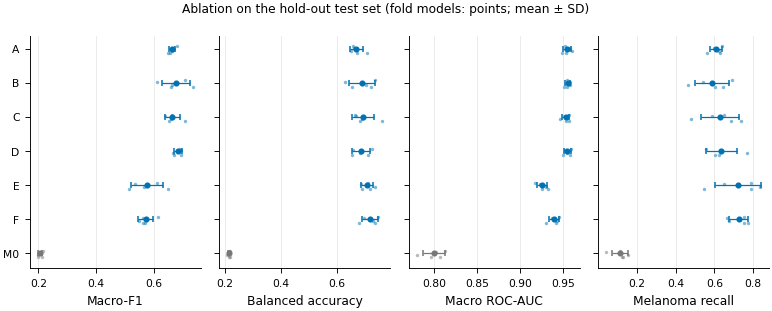

  saved figure: fig_ablation_overview.png, fig_ablation_overview.pdf


In [22]:
# [RQ-01][RQ-02][RQ-03] Consolidated ablation table
KEY = ["accuracy", "bal_acc", "macro_precision", "macro_recall", "macro_f1", "weighted_f1", "micro_f1", "macro_auc", "weighted_auc", "micro_auc",
       "macro_ap", "mcc", "kappa", "macro_mcc_ovr", "micro_mcc_ovr", "macro_kappa_ovr", "micro_kappa_ovr", "ece", "brier", "top3_acc",
       "mel_recall", "mel_precision", "df_recall", "vasc_recall", "akiec_recall", "bcc_recall"]

def mean_sd(v):
    v = np.asarray(v, float)
    if len(v) == 0: return ""
    return f"{v.mean():.3f} ± {v.std(ddof=1):.3f}" if len(v) > 1 else f"{v[0]:.3f}"

rows, rows_num = [], []
for code in TABLE_ORDER:
    ft = fold_metrics[(fold_metrics.exp == code) & (fold_metrics.split == "test")] if len(fold_metrics) else pd.DataFrame()
    fv = fold_metrics[(fold_metrics.exp == code) & (fold_metrics.split == "val")] if len(fold_metrics) else pd.DataFrame()
    if ft.empty:
        rows.append({"config": code, "description": exp_label(code), "folds": "0/%d" % len(FOLDS)}); continue
    r = {"config": code, "description": exp_label(code), "folds": f"{len(ft)}/{len(FOLDS)}"}
    rn = {"config": code, "folds_done": len(ft)}
    for k in KEY:
        r[k] = mean_sd(ft[k]); rn[f"{k}_mean"] = ft[k].mean(); rn[f"{k}_sd"] = ft[k].std(ddof=1)
    r["cv_macro_f1"] = mean_sd(fv.macro_f1); r["cv_bal_acc"] = mean_sd(fv.bal_acc)
    if code in ens:
        base = EVAL_ALIASES[code][0] if code in EVAL_ALIASES else code
        groups = test_df.lesion_id.values
        ci = cluster_bootstrap(test_df.label.values, ens[code]["probs"], groups,
                               fns={k: BOOT_FNS[k] for k in ["macro_f1", "bal_acc", "macro_auc", "mel_recall"]}, seed=1)
        em = ens[code]["metrics"]
        for k in ["macro_f1", "bal_acc", "macro_auc", "mel_recall"]:
            r[f"ens_{k}"] = f"{em[k]:.3f} [{ci[k][0]:.3f}, {ci[k][1]:.3f}]"
            rn[f"ens_{k}"] = em[k]; rn[f"ens_{k}_lo"], rn[f"ens_{k}_hi"] = ci[k]
        for k in ["accuracy", "mcc", "kappa", "ece", "macro_ap"]:
            r[f"ens_{k}"] = f"{em[k]:.3f}"; rn[f"ens_{k}"] = em[k]
    rows.append(r); rows_num.append(rn)

ablation = pd.DataFrame(rows); ablation_num = pd.DataFrame(rows_num)
ablation.to_csv(DIRS["results"] / "ablation_table.csv", index=False)
ablation_num.to_csv(DIRS["results"] / "ablation_table_numeric.csv", index=False)
with open(DIRS["results"] / "ablation_table.md", "w") as f:
    try:
        f.write(ablation.fillna("").to_markdown(index=False))
    except ImportError:                      # 'tabulate' not installed
        f.write(ablation.fillna("").to_string(index=False))
main_cols = ["config", "description", "folds", "accuracy", "bal_acc", "macro_f1", "macro_auc", "mcc", "kappa", "ece", "mel_recall", "df_recall", "vasc_recall", "akiec_recall"]
with open(DIRS["results"] / "ablation_table.tex", "w") as f:
    f.write(ablation.reindex(columns=main_cols).fillna("--").to_latex(index=False, escape=True))
display(ablation.reindex(columns=main_cols + [c for c in ablation.columns if c.startswith("ens_")]).fillna(""))

# per-class table (mean ± SD across fold models on test)
if len(per_class_fold):
    pct = per_class_fold[per_class_fold.split == "test"].groupby(["exp", "cls"])[["precision", "recall", "f1", "auc", "ap", "specificity"]].agg(["mean", "std"])
    pct.to_csv(DIRS["results"] / "ablation_table_per_class.csv")

# ---- ablation overview figure: fold points + mean ± SD --------------------------------
plot_codes = [c for c in TABLE_ORDER if len(fold_metrics) and ((fold_metrics.exp == c) & (fold_metrics.split == "test")).any()]
if plot_codes:
    mets = [("macro_f1", "Macro-F1"), ("bal_acc", "Balanced accuracy"), ("macro_auc", "Macro ROC-AUC"), ("mel_recall", "Melanoma recall")]
    fig, axs = plt.subplots(1, 4, figsize=(FIG_W2, 0.25 * len(plot_codes) + 1.2), sharey=True)
    ypos = np.arange(len(plot_codes))[::-1]
    for ax, (m, lab) in zip(axs, mets):
        for yv, c in zip(ypos, plot_codes):
            v = fold_metrics[(fold_metrics.exp == c) & (fold_metrics.split == "test")][m].values
            col = "#D55E00" if c in ("H", "I", "J") else ("#0072B2" if EXPERIMENTS.get(c, Exp("x", "x", group="core")).group == "core" or c in EVAL_ALIASES else "#777777")
            ax.scatter(v, np.full(len(v), yv) + np.random.default_rng(0).uniform(-0.12, 0.12, len(v)), s=5, color=col, alpha=0.5, lw=0)
            if len(v) > 1:
                ax.errorbar(v.mean(), yv, xerr=v.std(ddof=1), fmt="o", ms=3, color=col, capsize=2, lw=0.8)
            else:
                ax.plot(v.mean(), yv, "o", ms=3, color=col)
        ax.set_xlabel(lab); ax.grid(axis="x")
    axs[0].set_yticks(ypos); axs[0].set_yticklabels(plot_codes)
    fig.suptitle("Ablation on the hold-out test set (fold models: points; mean ± SD)", fontsize=8)
    fig.tight_layout()
    save_fig(fig, "fig_ablation_overview")

## 19A. Validation-to-test gap
**Request:** R8-2 (address the validation-to-test gap explicitly), R3-6 (objective reporting of the validation–test gap).

**Purpose.** The original manuscript reported a mean validation AUC of 0.9420 but a much lower test performance without discussing the gap. Here the gap is reported for every arm, fold by fold, on the same metrics.

**Why a gap is expected.** (i) The validation fold selects the checkpoint (early stopping on validation macro AUC), so validation values are optimistically biased; (ii) validation and test folds differ in lesion composition and minority-class support; (iii) small minority-class support makes macro metrics noisy. The test values are the unbiased estimates to report as main results.

**Expected output.** `val_test_gap.csv` (fold-paired mean ± SD of test − validation) and `fig_val_test_gap`.

,exp,n_folds,macro_f1_gap_test_minus_val,bal_acc_gap_test_minus_val,macro_auc_gap_test_minus_val,mel_recall_gap_test_minus_val,ece_gap_test_minus_val
0,A,5,-0.036 ± 0.036,-0.029 ± 0.031,-0.004 ± 0.010,-0.045 ± 0.043,0.009 ± 0.012
1,B,5,-0.013 ± 0.041,-0.011 ± 0.040,-0.005 ± 0.005,-0.060 ± 0.034,0.010 ± 0.008
2,C,5,-0.020 ± 0.009,0.001 ± 0.013,-0.005 ± 0.006,-0.068 ± 0.036,0.008 ± 0.013
3,D,5,-0.008 ± 0.033,-0.004 ± 0.037,-0.008 ± 0.004,-0.057 ± 0.071,0.011 ± 0.008
4,E,5,-0.009 ± 0.012,0.008 ± 0.029,-0.001 ± 0.010,-0.051 ± 0.021,0.008 ± 0.012
5,F,5,-0.020 ± 0.019,-0.001 ± 0.021,-0.005 ± 0.008,-0.080 ± 0.019,0.019 ± 0.005
6,M0,5,0.002 ± 0.017,0.003 ± 0.011,0.030 ± 0.016,0.043 ± 0.038,0.013 ± 0.016


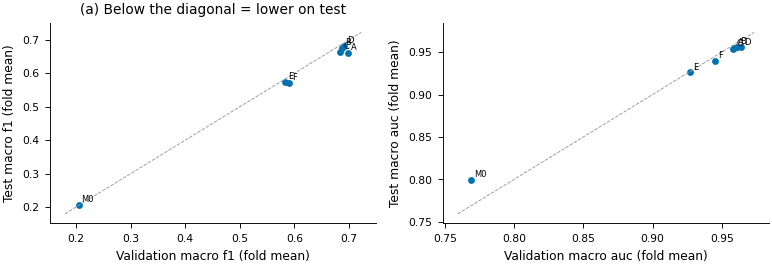

  saved figure: fig_val_test_gap.png, fig_val_test_gap.pdf


In [23]:
# [R8-2][R3-6] Validation-to-test gap
gap_rows = []
for code_ in TABLE_ORDER:
    fv = fold_metrics[(fold_metrics.exp == code_) & (fold_metrics.split == "val")] if len(fold_metrics) else pd.DataFrame()
    ft = fold_metrics[(fold_metrics.exp == code_) & (fold_metrics.split == "test")] if len(fold_metrics) else pd.DataFrame()
    if fv.empty or ft.empty:
        continue
    mm = fv.merge(ft, on="fold", suffixes=("_val", "_test"))
    r_ = dict(exp=code_, name=exp_label(code_), n_folds=len(mm))
    for m in ["macro_f1", "bal_acc", "macro_auc", "mel_recall", "ece"]:
        dlt = mm[f"{m}_test"] - mm[f"{m}_val"]
        r_.update({f"{m}_val": mean_sd(mm[f"{m}_val"]), f"{m}_test": mean_sd(mm[f"{m}_test"]), f"{m}_gap_test_minus_val": mean_sd(dlt)})
    gap_rows.append(r_)
gap_df = pd.DataFrame(gap_rows); gap_df.to_csv(DIRS["results"] / "val_test_gap.csv", index=False)
display(gap_df[[c for c in gap_df.columns if c in ("exp", "n_folds") or "gap" in c]] if len(gap_df) else "NOT RUN")
if len(gap_df):
    fig, axs = plt.subplots(1, 2, figsize=(FIG_W2, 2.6))
    for ax, m in zip(axs, ["macro_f1", "macro_auc"]):
        for code_ in gap_df.exp:
            fv = fold_metrics[(fold_metrics.exp == code_) & (fold_metrics.split == "val")][m].mean()
            ft = fold_metrics[(fold_metrics.exp == code_) & (fold_metrics.split == "test")][m].mean()
            ax.scatter(fv, ft, s=12, color="#0072B2"); ax.annotate(code_, (fv, ft), fontsize=5.5, xytext=(2, 2), textcoords="offset points")
        lo, hi = ax.get_xlim(); ax.plot([lo, hi], [lo, hi], color="#999999", lw=0.6, ls="--")
        ax.set_xlabel(f"Validation {m.replace('_', ' ')} (fold mean)"); ax.set_ylabel(f"Test {m.replace('_', ' ')} (fold mean)")
    axs[0].set_title("(a) Below the diagonal = lower on test"); fig.tight_layout(); save_fig(fig, "fig_val_test_gap")

## 20. Statistical comparison of ablation arms
**Request:** RQ-03 (paired, statistically appropriate comparisons).

**Design.** All arms share the same folds, the same fold seeds and the same test images, so comparisons are **paired**. Two complementary analyses are reported.

1. **Fold-level paired analysis** (variability due to the training data and optimisation). For each pre-specified contrast, the per-fold difference Δₖ = metric(arm₁, fold k) − metric(arm₂, fold k) on the test set: mean Δ, SD, paired *t* 95 % CI (n = 5), and the exact two-sided Wilcoxon signed-rank *p*. **With 5 folds the smallest attainable Wilcoxon p is 0.0625**, so this test cannot reach p < 0.05 and is reported descriptively. Holm correction is applied across the family of core contrasts on the primary metric (macro-F1).
2. **Ensemble paired lesion-cluster bootstrap** (variability due to the finite test set). The difference between the two arms' 5-fold ensembles is bootstrapped by resampling test lesions (B = 2000). The 95 % percentile CI of the difference is reported. A CI excluding 0 indicates a difference robust to test-set sampling for these trained models.

Neither analysis covers every source of variance (for example, re-drawing the test split). State this limitation in the manuscript. No test was chosen after seeing results. The contrast list below is fixed in advance.

**Expected output.** `stat_contrasts_folds.csv`, `stat_contrasts_ensemble_bootstrap.csv`, `fig_contrasts_forest`.

,arm1,arm2,question,family,metric,n_folds,mean_diff,sd_diff,ci_lo,ci_hi,wilcoxon_p,folds_arm1_better,wilcoxon_p_holm_primary
0,B,A,Metadata (without CBAM),core,macro_f1,5,0.0131,0.0522,-0.0518,0.0779,0.6250,3,1.000
5,D,C,Metadata (with CBAM),core,macro_f1,5,0.0194,0.0358,-0.0251,0.0639,0.3125,4,1.000
10,C,A,CBAM (without metadata),core,macro_f1,5,0.0015,0.0311,-0.0371,0.0402,0.8125,2,1.000
15,D,B,CBAM (with metadata),core,macro_f1,5,0.0079,0.0468,-0.0503,0.0661,1.0000,3,1.000
20,E,D,Imbalance strategy,core,macro_f1,5,-0.1084,0.0493,-0.1696,-0.0473,0.0625,0,0.375
25,F,E,MixUp/CutMix,core,macro_f1,5,-0.0039,0.0547,-0.0718,0.0640,1.0000,3,1.000
30,B,M0,Image information over metadata-only,supp,macro_f1,5,0.4683,0.0458,0.4114,0.5252,0.0625,5,NaN
35,A,M0,Image-only vs metadata-only,supp,macro_f1,5,0.4552,0.0112,0.4413,0.4692,0.0625,5,NaN


,arm1,arm2,question,family,metric,diff,ci_lo,ci_hi,ci_excludes_0
0,B,A,Metadata (without CBAM),core,macro_f1,0.0114,-0.0271,0.0533,False
4,D,C,Metadata (with CBAM),core,macro_f1,0.0115,-0.0579,0.0768,False
8,C,A,CBAM (without metadata),core,macro_f1,0.0009,-0.0494,0.0539,False
12,D,B,CBAM (with metadata),core,macro_f1,0.0009,-0.0552,0.0493,False
16,E,D,Imbalance strategy,core,macro_f1,-0.0912,-0.1679,-0.0144,True
20,F,E,MixUp/CutMix,core,macro_f1,-0.0184,-0.0535,0.0174,False
24,B,M0,Image information over metadata-only,supp,macro_f1,0.5011,0.4408,0.5535,True
28,A,M0,Image-only vs metadata-only,supp,macro_f1,0.4896,0.4119,0.5503,True


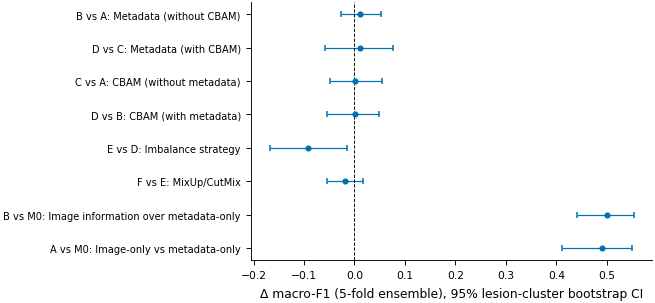

  saved figure: fig_contrasts_forest.png, fig_contrasts_forest.pdf


In [24]:
# [RQ-03] Paired statistics
CONTRASTS = [  # (arm1, arm2, question, family)
    ("B", "A", "Metadata (without CBAM)", "core"), ("D", "C", "Metadata (with CBAM)", "core"),
    ("C", "A", "CBAM (without metadata)", "core"), ("D", "B", "CBAM (with metadata)", "core"),
    ("E", "D", "Imbalance strategy", "core"), ("F", "E", "MixUp/CutMix", "core"),
    ("G", "E", "Focal loss + label smoothing", "core"), ("H", "E", "MixUp/CutMix + Focal/LS", "core"),
    ("J", "I", "Test-time augmentation", "core"),
    ("H", "S1_1P", "Two-phase vs single-phase fine-tuning", "supp"),
    ("E", "E_OS", "Class weights (given resampling + minority aug)", "supp"),
    ("E_OS", "E_RS", "Minority augmentation (given resampling)", "supp"),
    ("E_RS", "D", "Resampling alone", "supp"), ("E_CW", "D", "Class weights alone", "supp"),
    ("G", "G_F", "Label smoothing (given focal)", "supp"), ("G", "G_LS", "Focal (given label smoothing)", "supp"),
    ("G_F", "E", "Focal loss alone", "supp"), ("G_LS", "E", "Label smoothing alone", "supp"),
    ("F_CM", "E", "CutMix alone", "supp"), ("F_MU", "E", "MixUp alone", "supp"), ("F", "F_CM", "MixUp (given CutMix)", "supp"),
    ("H", "H_SGD", "Adam vs SGD (optimiser)", "supp"),
    ("B", "M0", "Image information over metadata-only", "supp"),
    ("A", "M0", "Image-only vs metadata-only", "supp"),
    ("H", "H_noAge", "Age (retrained without it)", "supp"), ("H", "H_noSex", "Sex (retrained without it)", "supp"),
    ("H", "H_noSite", "Anatomical site (retrained without it)", "supp"),
    ("H", "BM_R50", "SkinNet vs ResNet50", "bench"), ("H", "BM_D121", "SkinNet vs DenseNet121", "bench"),
    ("H", "BM_V2S", "SkinNet vs EfficientNetV2-S", "bench"), ("H", "BM_VIT", "SkinNet vs ViT-B/16", "bench"),
    ("H", "BM_CNXT", "SkinNet vs ConvNeXt-Tiny", "bench"),
]
STAT_METRICS = ["macro_f1", "bal_acc", "macro_auc", "mcc", "mel_recall"]

def holm(pvals):
    p = np.asarray(pvals, float); order = np.argsort(p); adj = np.empty_like(p); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (len(p) - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

stat_rows = []
ft = fold_metrics[fold_metrics.split == "test"] if len(fold_metrics) else pd.DataFrame(columns=["exp", "fold"])
for a1, a2, q, fam in CONTRASTS:
    A = ft[ft.exp == a1].set_index("fold"); B = ft[ft.exp == a2].set_index("fold")
    common = sorted(set(A.index) & set(B.index))
    if len(common) < 2:
        continue
    for m in STAT_METRICS:
        d = (A.loc[common, m] - B.loc[common, m]).values
        n = len(d); sd = d.std(ddof=1)
        tcrit = stats.t.ppf(0.975, n - 1)
        try:
            pw = stats.wilcoxon(d, alternative="two-sided", method="exact").pvalue if np.any(d != 0) else 1.0
        except Exception:
            pw = np.nan
        stat_rows.append(dict(arm1=a1, arm2=a2, question=q, family=fam, metric=m, n_folds=n, mean_diff=d.mean(), sd_diff=sd,
                              ci_lo=d.mean() - tcrit * sd / math.sqrt(n), ci_hi=d.mean() + tcrit * sd / math.sqrt(n),
                              wilcoxon_p=pw, folds_arm1_better=int((d > 0).sum())))
stat_folds = pd.DataFrame(stat_rows)
if len(stat_folds):
    stat_folds["wilcoxon_p_holm_primary"] = np.nan          # Holm within each pre-specified family (core, bench), primary metric
    for fam_ in ["core", "bench"]:
        mask = (stat_folds.family == fam_) & (stat_folds.metric == "macro_f1") & (stat_folds.n_folds == len(FOLDS))
        if mask.any():
            stat_folds.loc[mask, "wilcoxon_p_holm_primary"] = holm(stat_folds.loc[mask, "wilcoxon_p"].fillna(1).values)
stat_folds.to_csv(DIRS["results"] / "stat_contrasts_folds.csv", index=False)

boot_rows = []
for a1, a2, q, fam in CONTRASTS:
    if a1 in ens and a2 in ens:
        fns = {k: BOOT_FNS[k] for k in ["macro_f1", "bal_acc", "macro_auc", "mel_recall"]}
        ci = cluster_bootstrap(test_df.label.values, ens[a1]["probs"], test_df.lesion_id.values, fns=fns, seed=7, probs_b=ens[a2]["probs"])
        for k in fns:
            boot_rows.append(dict(arm1=a1, arm2=a2, question=q, family=fam, metric=k,
                                  diff=ens[a1]["metrics"][k] - ens[a2]["metrics"][k], ci_lo=ci[k][0], ci_hi=ci[k][1],
                                  ci_excludes_0=bool(ci[k][0] > 0 or ci[k][1] < 0)))
stat_boot = pd.DataFrame(boot_rows)
stat_boot.to_csv(DIRS["results"] / "stat_contrasts_ensemble_bootstrap.csv", index=False)
if len(stat_folds):
    display(stat_folds[stat_folds.metric == "macro_f1"].round(4))
if len(stat_boot):
    display(stat_boot[stat_boot.metric == "macro_f1"].round(4))

if len(stat_boot):
    sb = stat_boot[stat_boot.metric == "macro_f1"].reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(FIG_W1 + 1.2, 0.28 * len(sb) + 0.8))
    yv = np.arange(len(sb))[::-1]
    ax.errorbar(sb["diff"], yv, xerr=[sb["diff"] - sb.ci_lo, sb.ci_hi - sb["diff"]], fmt="o", ms=3, color="#0072B2", capsize=2, lw=0.8)
    ax.axvline(0, color="black", lw=0.6, ls="--")
    ax.set_yticks(yv); ax.set_yticklabels([f"{r.arm1} vs {r.arm2}: {r.question}" for r in sb.itertuples()], fontsize=6.5)
    ax.set_xlabel("Δ macro-F1 (5-fold ensemble), 95% lesion-cluster bootstrap CI")
    save_fig(fig, "fig_contrasts_forest")

## 20A. Benchmark comparison under the same protocol
**Request:** R1-6 (attention-based, transformer and hybrid architectures; efficiency), R3-5 (retrain competitors under the same split and statistically compare), R4-10 (fair comparison), R2 minor (Table 9 layout).

**Purpose.** Compare Full SkinNet (H, no TTA) with five retrained image encoders that share SkinNet's metadata head and training recipe: ResNet50 (residual CNN), DenseNet121 (dense CNN), EfficientNetV2-S (modern CNN), ConvNeXt-Tiny (transformer-inspired CNN), ViT-B/16 (pure transformer). All use the same folds, test set, preprocessing, imbalance handling and selection rule, so differences are attributable to the image encoder (and SkinNet's refinement + CBAM block).

**Reporting rule.** Paired fold-wise differences with Holm correction within the benchmark family (Section 20), plus 5-fold-ensemble bootstrap CIs. Results of other *published* studies use different splits and must be presented in a separate table **without** SkinNet's value repeated in every row (reviewer 2, Table 9); they cannot establish superiority.

**Expected output.** `benchmark_table.csv` (+ `.md`), `fig_benchmark_comparison`. Efficiency columns are added in Section 26.

In [25]:
# [R1-6][R3-5][R4-10] Benchmark table
BENCH = ["I"] + [c for c in ["BM_R50", "BM_D121", "BM_V2S", "BM_VIT", "BM_CNXT"] if c in EXPERIMENTS
                 and (c in PROFILES[CFG["RUN_PROFILE"]] or (len(fold_metrics) and (fold_metrics.exp == c).any()))]
brow = []
for code_ in BENCH:
    f_ = fold_metrics[(fold_metrics.exp == code_) & (fold_metrics.split == "test")] if len(fold_metrics) else pd.DataFrame()
    if f_.empty:
        brow.append(dict(model=exp_label(code_), code=code_, folds=f"0/{len(FOLDS)}")); continue
    r_ = dict(model=exp_label(code_) if code_ != "I" else "SkinNet (Full, no TTA)", code=code_, folds=f"{len(f_)}/{len(FOLDS)}")
    for m in ["macro_f1", "bal_acc", "macro_auc", "mcc", "mel_recall", "ece"]:
        r_[f"{m} (fold mean ± SD)"] = mean_sd(f_[m])
        r_[f"{m} (ensemble)"] = round(ens[code_]["metrics"][m], 4) if code_ in ens else np.nan
    if len(stat_folds) and code_ != "I":
        s_ = stat_folds[(stat_folds.arm1 == "H") & (stat_folds.arm2 == code_) & (stat_folds.metric == "macro_f1")]
        if len(s_):
            r_.update(delta_macro_f1_H_minus_model=round(s_.mean_diff.iat[0], 4), wilcoxon_p=s_.wilcoxon_p.iat[0],
                      holm_p=s_.wilcoxon_p_holm_primary.iat[0])
    brow.append(r_)
bench_tab = pd.DataFrame(brow)
bench_tab.to_csv(DIRS["results"] / "benchmark_table.csv", index=False)
try:
    (DIRS["results"] / "benchmark_table.md").write_text(bench_tab.to_markdown(index=False))
except Exception:
    pass
display(bench_tab)
_have = [c for c in BENCH if len(fold_metrics) and ((fold_metrics.exp == c) & (fold_metrics.split == "test")).any()]
if _have:
    fig, ax = plt.subplots(figsize=(FIG_W1 + 0.8, 2.4))
    for i, c in enumerate(_have):
        v = fold_metrics[(fold_metrics.exp == c) & (fold_metrics.split == "test")].macro_f1.values
        ax.scatter(np.full(len(v), i) + np.linspace(-0.12, 0.12, len(v)), v, s=10, color="#0072B2" if c == "I" else "#999999", zorder=3)
        ax.hlines(v.mean(), i - 0.25, i + 0.25, color="black", lw=1)
    ax.set_xticks(range(len(_have))); ax.set_xticklabels(["SkinNet" if c == "I" else c.replace("BM_", "") for c in _have], rotation=30, ha="right")
    ax.set_ylabel("Test macro-F1 (fold models)"); ax.set_title("Same folds, same protocol")
    save_fig(fig, "fig_benchmark_comparison")

,model,code,folds
0,Full SkinNet without TTA,I,0/5
1,ResNet50 + metadata (same training protocol),BM_R50,0/5
2,ViT-B/16 + metadata (same training protocol),BM_VIT,0/5
3,ConvNeXt-Tiny + metadata (same training protocol),BM_CNXT,0/5


## 21. Test-time augmentation: I (without TTA) vs J (with TTA)
**Request:** RQ-08.

**Purpose.** Quantify the effect of TTA on the *same trained H models* and the *same test images*.

**Verification.** TTA is applied only inside `make_eval_dataset`. The training pipeline never receives TTA transforms, and no test information is used to choose TTA views (the 5 views are fixed in advance). All individual views are stored (`view_probs`), so the effect of the number of views can be inspected without re-running inference.

**Expected output.** Fold-wise I vs J table (`tta_comparison.csv`), a views-count analysis for the ensemble, and `fig_tta_effect`.

In [26]:
# [RQ-08] TTA analysis
tta_rows = []
for fold in FOLDS:
    zi, zj = load_preds("I", fold, "test"), load_preds("J", fold, "test_tta")
    if zi is None or zj is None:
        continue
    assert (zi["image_id"] == zj["image_id"]).all()
    mi, _ = compute_metrics(zi["y_true"].astype(int), zi["probs"]); mj, _ = compute_metrics(zj["y_true"].astype(int), zj["probs"])
    for k in ["accuracy", "bal_acc", "macro_f1", "macro_auc", "mel_recall", "ece"]:
        tta_rows.append(dict(fold=fold, metric=k, no_tta=mi[k], tta=mj[k], diff=mj[k] - mi[k]))
tta_df = pd.DataFrame(tta_rows)
tta_df.to_csv(DIRS["results"] / "tta_comparison.csv", index=False)
if len(tta_df):
    display(tta_df.pivot_table(index="metric", values=["no_tta", "tta", "diff"], aggfunc=["mean", "std"]).round(4))
    view_curve = []
    vp = [load_preds("J", f, "test_tta")["view_probs"] for f in FOLDS if load_preds("J", f, "test_tta") is not None]
    if len(vp) == len(FOLDS):
        vp = np.stack(vp)                                         # folds x views x N x C
        for v in range(1, vp.shape[1] + 1):
            pe = vp[:, :v].mean(axis=(0, 1))
            view_curve.append(dict(n_views=v, macro_f1=BOOT_FNS["macro_f1"](test_df.label.values, pe),
                                   bal_acc=BOOT_FNS["bal_acc"](test_df.label.values, pe)))
        view_curve = pd.DataFrame(view_curve); view_curve.to_csv(DIRS["results"] / "tta_views_curve.csv", index=False)
    fig, axs = plt.subplots(1, 2, figsize=(FIG_W2 * 0.75, 2.2))
    sub = tta_df[tta_df.metric == "macro_f1"]
    for r in sub.itertuples():
        axs[0].plot([0, 1], [r.no_tta, r.tta], "-o", ms=3, color="#0072B2", lw=0.8)
    axs[0].set_xticks([0, 1]); axs[0].set_xticklabels(["I: no TTA", "J: TTA"]); axs[0].set_ylabel("Test macro-F1 (fold models)")
    axs[0].set_title("(a) Paired by fold")
    if isinstance(view_curve, pd.DataFrame) and len(view_curve):
        axs[1].plot(view_curve.n_views, view_curve.macro_f1, "-o", ms=3, label="macro-F1", color="#D55E00")
        axs[1].plot(view_curve.n_views, view_curve.bal_acc, "-s", ms=3, label="balanced acc.", color="#009E73")
        axs[1].set_xlabel("Number of TTA views (ensemble)"); axs[1].legend(); axs[1].set_title("(b) Views")
    fig.tight_layout()
    save_fig(fig, "fig_tta_effect")
else:
    print("TTA comparison not available yet: H has not finished any fold.")

TTA comparison not available yet: H has not finished any fold.


## 21A. Run-to-run reproducibility (repeated training of H, fold 1)
**Request:** R4-9 and R3 minor comment ("complete reproducibility" claim).

**Purpose.** GPU training in TensorFlow is not bit-wise deterministic by default (cuDNN autotuning, atomic reductions), even with fixed seeds. `H_REP` retrains Full SkinNet on fold 1 with **exactly the same seed and configuration**. The difference to H fold 1 quantifies run-to-run variability and replaces the claim of complete reproducibility with a measured statement. (`DETERMINISTIC_OPS=True` enables TensorFlow op determinism at a speed cost; it is off by default.)

**Expected output.** `reproducibility_check.csv`: prediction agreement, maximum/mean absolute probability difference, metric differences.

In [27]:
# [R4-9] Reproducibility check
za, zb = load_preds("H", 1, "test"), load_preds("H_REP", 1, "test")
if za is None or zb is None:
    print("NOT RUN: needs H fold 1 and H_REP fold 1.")
    repro = pd.DataFrame()
else:
    ma, _ = compute_metrics(za["y_true"].astype(int), za["probs"]); mb, _ = compute_metrics(zb["y_true"].astype(int), zb["probs"])
    repro = pd.DataFrame([dict(label_agreement=float((za["probs"].argmax(1) == zb["probs"].argmax(1)).mean()),
                               max_abs_prob_diff=float(np.abs(za["probs"] - zb["probs"]).max()),
                               mean_abs_prob_diff=float(np.abs(za["probs"] - zb["probs"]).mean()),
                               **{f"delta_{k}": mb[k] - ma[k] for k in ["macro_f1", "bal_acc", "macro_auc", "mel_recall", "ece"]},
                               deterministic_ops=CFG["DETERMINISTIC_OPS"], gpu=HW.get("gpu_name"))])
    display(repro.round(4))
repro.to_csv(DIRS["results"] / "reproducibility_check.csv", index=False)

NOT RUN: needs H fold 1 and H_REP fold 1.


## 21B. Batch-size sensitivity (H, fold 1)
**Request:** R6 ("BS analysis for training and validation"). The comment is ambiguous; it is answered in two ways: the **Brier score (BS)** of training and validation per epoch (Section 23, training curves) and this **batch-size** sensitivity check. Batch 8 and 32 keep the number of images per epoch fixed (steps scaled accordingly) and the learning-rate schedule unchanged.

**Expected output.** `batch_size_sensitivity.csv` with validation and test metrics for batch 8, 16 (H) and 32.

In [28]:
# [R6] Batch-size sensitivity
bs_rows = []
for code_, bs_ in [("H_BS8", 8), ("H", BATCH_SIZE), ("H_BS32", 32)]:
    for kind in ["val", "test"]:
        z_ = load_preds(code_, 1, kind)
        if z_ is None:
            continue
        m_, _ = compute_metrics(z_["y_true"].astype(int), z_["probs"])
        bs_rows.append(dict(exp=code_, batch_size=bs_, split=kind, **{k: m_[k] for k in ["macro_f1", "bal_acc", "macro_auc", "mcc", "ece", "brier"]}))
bs_tab = pd.DataFrame(bs_rows)
bs_tab.to_csv(DIRS["results"] / "batch_size_sensitivity.csv", index=False)
display(bs_tab.round(4) if len(bs_tab) else "NOT RUN: batch-size arms (profile 'full') not trained.")

"NOT RUN: batch-size arms (profile 'full') not trained."

## 21C. Do resampling and mixing create synthetic patterns? Train-versus-validation gap per class
**Request:** R7-4 (individual and combined effect of class weighting, capped oversampling, focal loss, CutMix, MixUp and label smoothing; could rebalancing and augmentation introduce synthetic patterns?), R8-8.

**Method.** The individual effects are measured by the controlled arms (E_RS resampling only, E_CW class weights only, E_OS resampling + minority augmentation, E all three; G_F focal only, G_LS label smoothing only; F_CM CutMix only, F_MU MixUp only; Section 20). To test for *synthetic patterns*, every arm in `TRAIN_PRED_EXPS` also predicts its **raw, non-resampled training fold** without augmentation. If oversampling makes the network memorise repeated minority images (or artefacts of their augmentation), the per-class **training recall will far exceed the validation recall** for the oversampled classes, and more so in arms with resampling (E_RS, E_OS, E, H) than without (D, E_CW). The per-class gap (train − validation recall and log-loss) is reported against each class's oversampling factor.

**Expected output.** `synthetic_pattern_check.csv`, `synthetic_pattern_summary.csv`, `fig_synthetic_pattern_check`.

,exp,class_group,recall_train,recall_val,recall_gap,logloss_gap
0,D,classes not oversampled,0.9412,0.8869,0.0543,0.1417
1,D,classes oversampled by the resampling arms,0.8863,0.6581,0.2283,0.7623
2,E,classes not oversampled,0.5882,0.5647,0.0235,0.1263
3,E,classes oversampled by the resampling arms,0.9575,0.7241,0.2333,0.8985
4,F,classes not oversampled,0.5525,0.5418,0.0107,0.0584
5,F,classes oversampled by the resampling arms,0.9682,0.7494,0.2188,0.6525


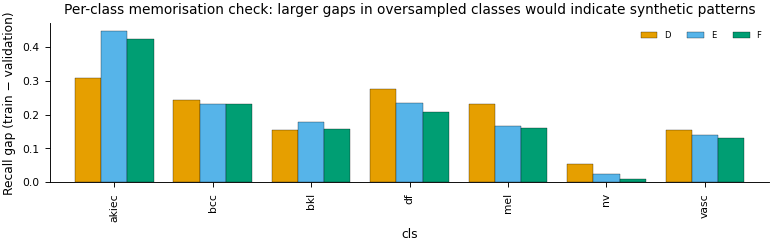

  saved figure: fig_synthetic_pattern_check.png, fig_synthetic_pattern_check.pdf


In [29]:
# [R7-4][R8-8] Train-vs-validation gap per class (memorisation of oversampled / augmented patterns)
imb = pd.read_csv(DIRS["results"] / "imbalance_report.csv") if (DIRS["results"] / "imbalance_report.csv").exists() else pd.DataFrame()
sp_rows = []
for code_ in [c for c in ["D", "E_CW", "E_RS", "E_OS", "E", "F_CM", "F_MU", "F", "G", "H"] if c in EXPERIMENTS]:
    for fold in exp_folds(EXPERIMENTS[code_]):
        ztr, zva = load_preds(code_, fold, "train"), load_preds(code_, fold, "val")
        if ztr is None or zva is None:
            continue
        for c in range(N_CLASSES):
            mt, mv = ztr["y_true"] == c, zva["y_true"] == c
            if mt.sum() == 0 or mv.sum() == 0:
                continue
            fac = np.nan
            if len(imb):
                r_ = imb[(imb.fold == fold) & (imb.cls == CLASS_NAMES[c])]
                fac = float(r_.final.iat[0] / max(r_.original.iat[0], 1)) if len(r_) else np.nan
            sp_rows.append(dict(exp=code_, fold=fold, cls=CLASS_NAMES[c], resampled=EXPERIMENTS[code_].resample, oversample_factor=fac,
                                recall_train=float((ztr["probs"][mt].argmax(1) == c).mean()), recall_val=float((zva["probs"][mv].argmax(1) == c).mean()),
                                logloss_train=float(-np.log(np.clip(ztr["probs"][mt, c], 1e-7, 1)).mean()),
                                logloss_val=float(-np.log(np.clip(zva["probs"][mv, c], 1e-7, 1)).mean())))
sp = pd.DataFrame(sp_rows)
if len(sp):
    sp["recall_gap"] = sp.recall_train - sp.recall_val; sp["logloss_gap"] = sp.logloss_val - sp.logloss_train
    sp.to_csv(DIRS["results"] / "synthetic_pattern_check.csv", index=False)
    sp["class_group"] = np.where(sp.oversample_factor > 1.01, "classes oversampled by the resampling arms", "classes not oversampled")
    sp_sum = sp.groupby(["exp", "class_group"])[["recall_train", "recall_val", "recall_gap", "logloss_gap"]].mean().round(4).reset_index()
    sp_sum.to_csv(DIRS["results"] / "synthetic_pattern_summary.csv", index=False)
    display(sp_sum)
    piv = sp.groupby(["exp", "cls"]).recall_gap.mean().unstack().reindex(columns=CLASS_NAMES)
    fig, ax = plt.subplots(figsize=(FIG_W2, 2.4))
    piv.T.plot.bar(ax=ax, width=0.8, edgecolor="black", lw=0.2, color=(OKABE_ITO * 2)[:piv.shape[0]])
    ax.axhline(0, color="black", lw=0.5); ax.set_ylabel("Recall gap (train − validation)")
    ax.set_title("Per-class memorisation check: larger gaps in oversampled classes would indicate synthetic patterns")
    ax.legend(ncol=5, fontsize=5.5); fig.tight_layout(); save_fig(fig, "fig_synthetic_pattern_check")
else:
    print("NOT RUN: needs training-fold predictions (arms in TRAIN_PRED_EXPS).")

## 22. Melanoma operating-point analysis (thresholds chosen on validation only)
**Request:** R2-M3, R3-5, R7-1; RQ-02 (melanoma recall), and the brief's requirement not to optimise on the test set.

**Purpose.** Show how melanoma sensitivity trades against specificity, and report test performance at operating points **fixed on validation data**.

**Method.**
* Melanoma is scored one-vs-rest by p(mel). For each fold model, the threshold *t* is the largest value that reaches a target validation sensitivity (0.80, 0.85, 0.90, 0.95), computed on that fold's **validation** predictions. The threshold is then applied unchanged to the fold model's **test** predictions. The default arg-max rule is included for reference.
* For the 5-fold ensemble, thresholds are chosen on the pooled out-of-fold validation predictions (an approximation, because the ensemble itself has no held-out validation set) and applied to the ensemble test probabilities.
* Reported on test: sensitivity, specificity, PPV and NPV with Wilson 95 % CIs. The test ROC curve is drawn **for description only**; operating points are marked where the validation-derived thresholds land.

**Expected output.** `melanoma_operating_points.csv`, `fig_melanoma_operating_points`.


**Why not a recall target of 0.50 [R3-5].** The original manuscript used a melanoma recall target of 0.50 without a clinical rationale. Here, operating points are defined by **sensitivity targets of 0.80, 0.85, 0.90 and 0.95 chosen on validation data only**, which bracket the sensitivity usually expected of a triage aid, and are then reported unchanged on the test set and on BCN20000 (Section 22A) together with the specificity they cost.

**Statement for Abstract and Conclusion [R2-M3, R7-1].** Whatever the measured values, the manuscript should state explicitly that the system is a research prototype evaluated retrospectively and is **not suitable as a stand-alone melanoma screening tool**; any clinical use would require prospective, multi-centre validation.

In [30]:
# [RQ-02] Melanoma thresholds from validation, evaluated on test
MEL_TARGETS = [0.80, 0.85, 0.90, 0.95]
MEL_EXP = "J" if "J" in ens else ("I" if "I" in ens else None)

def thr_for_sensitivity(y_bin, score, target):
    pos = np.sort(score[y_bin == 1])[::-1]
    if len(pos) == 0:
        return np.nan
    k = int(math.ceil(target * len(pos))) - 1
    return float(pos[min(max(k, 0), len(pos) - 1)])

def binary_report(y_bin, pred):
    tp = int(((pred == 1) & (y_bin == 1)).sum()); fn = int(((pred == 0) & (y_bin == 1)).sum())
    tn = int(((pred == 0) & (y_bin == 0)).sum()); fp = int(((pred == 1) & (y_bin == 0)).sum())
    out = dict(tp=tp, fn=fn, tn=tn, fp=fp)
    for name, k, n in [("sensitivity", tp, tp + fn), ("specificity", tn, tn + fp), ("ppv", tp, tp + fp), ("npv", tn, tn + fn)]:
        out[name] = k / n if n else np.nan; out[f"{name}_ci"] = wilson_ci(k, n)
    return out

mel_rows = []
code_for_mel = MEL_EXP or "I"
for fold in FOLDS:
    zv, zt = load_preds(code_for_mel, fold, "val"), load_preds(code_for_mel, fold, "test" if code_for_mel == "I" else "test_tta")
    if zv is None or zt is None:
        continue
    yv, yt = (zv["y_true"] == MEL_IDX).astype(int), (zt["y_true"] == MEL_IDX).astype(int)
    rules = [("argmax", None)] + [(f"val_sens>={t:.2f}", thr_for_sensitivity(yv, zv["probs"][:, MEL_IDX], t)) for t in MEL_TARGETS]
    for rule, thr in rules:
        pred = (zt["probs"].argmax(1) == MEL_IDX).astype(int) if thr is None else (zt["probs"][:, MEL_IDX] >= thr).astype(int)
        mel_rows.append(dict(level="fold", fold=fold, rule=rule, threshold=thr, **binary_report(yt, pred)))
if MEL_EXP:
    oof_p = np.concatenate([load_preds(MEL_EXP, f, "val")["probs"][:, MEL_IDX] for f in FOLDS])
    oof_y = np.concatenate([(load_preds(MEL_EXP, f, "val")["y_true"] == MEL_IDX).astype(int) for f in FOLDS])
    pe, yt = ens[MEL_EXP]["probs"], (test_df.label.values == MEL_IDX).astype(int)
    for rule, thr in [("argmax", None)] + [(f"val_sens>={t:.2f}", thr_for_sensitivity(oof_y, oof_p, t)) for t in MEL_TARGETS]:
        pred = (pe.argmax(1) == MEL_IDX).astype(int) if thr is None else (pe[:, MEL_IDX] >= thr).astype(int)
        mel_rows.append(dict(level="ensemble", fold=0, rule=rule, threshold=thr, **binary_report(yt, pred)))
mel_df = pd.DataFrame(mel_rows)
mel_df.to_csv(DIRS["results"] / "melanoma_operating_points.csv", index=False)
if len(mel_df):
    display(mel_df.groupby(["level", "rule"])[["threshold", "sensitivity", "specificity", "ppv", "npv"]].mean().round(3))
if MEL_EXP:
    fpr, tpr, _ = roc_curve(yt, pe[:, MEL_IDX])
    fig, ax = plt.subplots(figsize=(FIG_W1, FIG_W1 * 0.9))
    ax.plot(fpr, tpr, color="#D55E00", label=f"Test ROC (AUC {roc_auc_score(yt, pe[:, MEL_IDX]):.3f})")
    ens_ops = mel_df[mel_df.level == "ensemble"]
    for r, mk in zip(ens_ops.itertuples(), ["s", "o", "^", "v", "D"]):
        ax.plot(1 - r.specificity, r.sensitivity, mk, ms=4, color="black", mfc="white", label=r.rule)
    ax.plot([0, 1], [0, 1], ls=":", lw=0.6, color="grey")
    ax.set_xlabel("1 − specificity"); ax.set_ylabel("Sensitivity"); ax.set_title(f"Melanoma vs rest ({MEL_EXP}, 5-fold ensemble)")
    ax.legend(loc="lower right", fontsize=6)
    save_fig(fig, "fig_melanoma_operating_points")

## 22A. External validation on BCN20000 (frozen models)
**Request:** R7-2 (independent, multi-centre validation), R1-8 (external validation plan), R2-M3 and R7-1 (melanoma sensitivity), R3-5 (cautious interpretation).

**Protocol (fixed before looking at BCN20000 results).**
1. Every trained fold model of the arms in `CFG['EXT_EVAL_EXPS']` is applied **unchanged** to BCN20000: no retraining, fine-tuning, recalibration, re-weighting or threshold tuning on BCN20000. Metadata is transformed with the preprocessors fitted on the corresponding HAM10000 training fold.
2. Metrics are computed on the 7 HAM10000 classes (SCC excluded) for each fold model (mean ± SD) and for the 5-fold ensemble, with **lesion-cluster bootstrap 95 % CIs** (BCN20000 `lesion_id`).
3. **Melanoma operating points** use the thresholds chosen on the HAM10000 validation folds (Section 22) and are applied unchanged to BCN20000.
4. **SCC (out-of-distribution):** where the model sends SCC images, and whether the maximum softmax probability separates SCC from in-distribution images (AUROC).
5. **Site-mapping sensitivity:** Full SkinNet is re-evaluated with every BCN20000 site set to `unknown`, to show how much of the external performance depends on the (coarser) site mapping.
6. Full SkinNet is also evaluated with TTA on BCN20000 (J-ext).

**Interpretation.** A drop from the internal test set to BCN20000 is expected (different centre, devices, population and a tertiary-referral case mix with difficult sites such as nails and mucosa). Report it as the generalisation gap; do not tune anything to close it.

**Expected output.** `external_fold_metrics.csv`, `external_ensemble_metrics.csv`, `external_per_class.csv`, `external_melanoma_operating_points.csv`, `external_scc_ood.csv`, `external_site_sensitivity.csv`, `fig_external_validation`, `fig_cm_external_H`.

External inference: 0.0 min


,exp,name,folds_ext,macro_f1_internal,bal_acc_internal,macro_auc_internal,mel_recall_internal,macro_f1_external,bal_acc_external,macro_auc_external,mel_recall_external
0,M0,Metadata-only baseline (CE),5,0.206 ± 0.007,0.213 ± 0.004,0.799 ± 0.013,0.114 ± 0.043,0.131 ± 0.004,0.204 ± 0.003,0.657 ± 0.004,0.031 ± 0.014
1,A,EfficientNetB3 only (image-only baseline),5,0.662 ± 0.012,0.671 ± 0.023,0.955 ± 0.005,0.610 ± 0.031,0.359 ± 0.021,0.384 ± 0.018,0.794 ± 0.020,0.517 ± 0.063
2,B,EfficientNetB3 + Metadata,5,0.675 ± 0.049,0.690 ± 0.046,0.956 ± 0.003,0.589 ± 0.088,0.361 ± 0.025,0.398 ± 0.014,0.804 ± 0.009,0.493 ± 0.104
3,C,EfficientNetB3 + CBAM,5,0.663 ± 0.026,0.694 ± 0.041,0.953 ± 0.004,0.629 ± 0.100,0.350 ± 0.017,0.386 ± 0.016,0.788 ± 0.026,0.469 ± 0.109
4,D,EfficientNetB3 + CBAM + Metadata,5,0.683 ± 0.013,0.687 ± 0.032,0.956 ± 0.004,0.636 ± 0.079,0.347 ± 0.014,0.392 ± 0.018,0.807 ± 0.026,0.454 ± 0.053


,exp,n_scc,scc_predicted_as_akiec,scc_predicted_as_bcc,scc_predicted_as_bkl,scc_predicted_as_df,scc_predicted_as_mel,scc_predicted_as_nv,scc_predicted_as_vasc,msp_mean_in,msp_mean_scc,auroc_ood_by_low_msp
0,M0,431,0.000,0.000,0.462,0.000,0.109,0.429,0.0,0.667,0.474,0.748
1,A,431,0.095,0.053,0.677,0.030,0.097,0.046,0.0,0.697,0.673,0.539
2,B,431,0.114,0.053,0.664,0.049,0.093,0.028,0.0,0.695,0.656,0.562
3,C,431,0.102,0.070,0.691,0.039,0.067,0.030,0.0,0.695,0.644,0.575
4,D,431,0.058,0.037,0.791,0.037,0.056,0.021,0.0,0.726,0.723,0.505


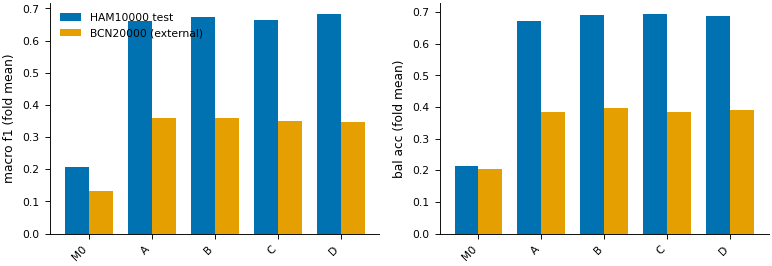

  saved figure: fig_external_validation.png, fig_external_validation.pdf


In [31]:
# [R7-2][R1-8][R7-1] External validation
EXT_READY = bool(globals().get("BCN_AVAILABLE")) and globals().get("bcn_df") is not None

def unit_model(code, fold):
    """Rebuild an arm's model and load its final (best Phase-2) weights; returns (model, metadata preprocessor) or None."""
    exp = EXPERIMENTS[code]; d = unit_dir(code, fold, create=False)
    if not read_status(d).get("done") or not (d / "best_p2.weights.h5").exists():
        return None
    mp = MetaPreprocessor(CFG["LOC_ENCODING"], features=exp.meta_features).fit(get_fold_frames(fold)[0])
    clear_keras_session(); gc.collect()
    model = build_skinnet(exp, mp.dense_dim, n_loc=len(mp.loc_vocab), weights="cfg")   # training architecture (see Section 24)
    set_phase(model, 2)
    model.load_weights(d / "best_p2.weights.h5")
    return model, mp

ext_fold_rows, ext_pc_rows, ext_ens, ext_probs = [], [], {}, {}
if not EXT_READY:
    print("NOT RUN: BCN20000 not available.")
else:
    bcn_in = bcn_df[bcn_df.label >= 0].reset_index(drop=True)
    bcn_ood = bcn_df[bcn_df.label < 0].reset_index(drop=True)
    t_start = time.time()
    for code_ in [c for c in dict.fromkeys(CFG["EXT_EVAL_EXPS"] + ["H"]) if c in EXPERIMENTS]:
        exp = EXPERIMENTS[code_]
        for fold in exp_folds(exp):
            d = unit_dir(code_, fold, create=False)
            need = [("ext", None)] + ([("ext_tta", "tta"), ("ext_nosite", "nosite")] if code_ == "H" else [])
            if all((d / f"preds_{k}.npz").exists() for k, _ in need) or not read_status(d).get("done"):
                continue
            if (time.time() - SESSION_T0) / 3600 > CFG["SESSION_BUDGET_H"] + 0.5:
                print("Session time exhausted: remaining external predictions will be made in the next session."); break
            um = unit_model(code_, fold)
            if um is None:
                continue
            model, mp = um
            for k, variant in need:
                if (d / f"preds_{k}.npz").exists():
                    continue
                frame = bcn_df.assign(localization="unknown") if variant == "nosite" else bcn_df
                dd, ll = mp.transform(frame)
                if variant == "tta":
                    views = np.stack([predict_probs(model, make_eval_dataset(frame, dd, ll, exp, tta_view=v, cache=BCN_CACHE)) for v in range(CFG["TTA_VIEWS"])])
                    save_preds(d / f"preds_{k}.npz", frame, views.mean(0), views=views)
                else:
                    save_preds(d / f"preds_{k}.npz", frame, predict_probs(model, make_eval_dataset(frame, dd, ll, exp, cache=BCN_CACHE)))
            del model; clear_keras_session(); release_host_memory()
    print(f"External inference: {(time.time() - t_start) / 60:.1f} min")

    def load_ext(code_, fold, kind="ext"):
        base, kind = ("H", "ext_tta") if code_ == "J" else (("H", kind) if code_ == "I" else (code_, kind))
        p_ = unit_dir(base, fold, create=False) / f"preds_{kind}.npz"
        return dict(np.load(p_, allow_pickle=False)) if p_.exists() else None

    in_mask = bcn_df.label.values >= 0
    y_ext, g_ext = bcn_df.label.values[in_mask], bcn_df.lesion_id.values[in_mask]
    for code_ in [c for c in CFG["EXT_EVAL_EXPS"] if c in EXPERIMENTS and c != "H"] + ["I", "J"]:
        base = "H" if code_ in ("I", "J") else code_
        fl = {f: load_ext(code_, f) for f in exp_folds(EXPERIMENTS[base])}
        fl = {f: z for f, z in fl.items() if z is not None}
        for f, z in fl.items():
            assert (z["image_id"] == bcn_df.image_id.values).all()
            m_, pc_ = compute_metrics(y_ext, z["probs"][in_mask])
            ext_fold_rows.append(dict(exp=code_, fold=f, **m_)); ext_pc_rows.append(pc_.assign(exp=code_, fold=f))
        if len(fl) == CFG["N_FOLDS"]:
            pe = np.mean([z["probs"] for z in fl.values()], 0); ext_probs[code_] = pe
            m_, pc_ = compute_metrics(y_ext, pe[in_mask])
            ci = cluster_bootstrap(y_ext, pe[in_mask], g_ext, fns={k: BOOT_FNS[k] for k in ["macro_f1", "bal_acc", "macro_auc", "mel_recall"]}, seed=11)
            ext_ens[code_] = dict(m_, **{f"{k}_ci": v for k, v in ci.items()})
            ext_pc_rows.append(pc_.assign(exp=code_, fold=0))
    ext_fold = pd.DataFrame(ext_fold_rows); ext_fold.to_csv(DIRS["results"] / "external_fold_metrics.csv", index=False)
    ext_ens_df = pd.DataFrame([dict(exp=c, **v) for c, v in ext_ens.items()])
    ext_ens_df.to_csv(DIRS["results"] / "external_ensemble_metrics.csv", index=False)
    (pd.concat(ext_pc_rows, ignore_index=True) if ext_pc_rows else pd.DataFrame()).to_csv(DIRS["results"] / "external_per_class.csv", index=False)

    # ---- internal vs external summary ----
    summ = []
    for code_ in ext_fold.exp.unique() if len(ext_fold) else []:
        fi = fold_metrics[(fold_metrics.exp == code_) & (fold_metrics.split == "test")]
        fe = ext_fold[ext_fold.exp == code_]
        summ.append(dict(exp=code_, name=exp_label(code_), folds_ext=len(fe),
                         **{f"{m}_internal": mean_sd(fi[m]) for m in ["macro_f1", "bal_acc", "macro_auc", "mel_recall"]},
                         **{f"{m}_external": mean_sd(fe[m]) for m in ["macro_f1", "bal_acc", "macro_auc", "mel_recall"]}))
    ext_summary = pd.DataFrame(summ); ext_summary.to_csv(DIRS["results"] / "external_vs_internal.csv", index=False)
    display(ext_summary)

    # ---- melanoma operating points with HAM-validation thresholds ----
    em_rows = []
    yb_ext = (y_ext == MEL_IDX).astype(int)
    for code_ in ["I", "J"]:
        for f in FOLDS:
            zv, ze = load_preds("I", f, "val"), load_ext(code_, f)
            if zv is None or ze is None:
                continue
            yv = (zv["y_true"] == MEL_IDX).astype(int)
            for rule, thr in [("argmax", None)] + [(f"val_sens>={t:.2f}", thr_for_sensitivity(yv, zv["probs"][:, MEL_IDX], t)) for t in MEL_TARGETS]:
                pr_ = ze["probs"][in_mask]
                pred = (pr_.argmax(1) == MEL_IDX).astype(int) if thr is None else (pr_[:, MEL_IDX] >= thr).astype(int)
                em_rows.append(dict(exp=code_, level="fold", fold=f, rule=rule, threshold=thr, **binary_report(yb_ext, pred)))
        if code_ in ext_probs and MEL_EXP:
            for rule, thr in [("argmax", None)] + [(f"val_sens>={t:.2f}", thr_for_sensitivity(oof_y, oof_p, t)) for t in MEL_TARGETS]:
                pr_ = ext_probs[code_][in_mask]
                pred = (pr_.argmax(1) == MEL_IDX).astype(int) if thr is None else (pr_[:, MEL_IDX] >= thr).astype(int)
                em_rows.append(dict(exp=code_, level="ensemble", fold=0, rule=rule, threshold=thr, **binary_report(yb_ext, pred)))
    ext_mel = pd.DataFrame(em_rows); ext_mel.to_csv(DIRS["results"] / "external_melanoma_operating_points.csv", index=False)
    if len(ext_mel):
        display(ext_mel.groupby(["exp", "level", "rule"])[["sensitivity", "specificity", "ppv"]].mean().round(3))

    # ---- SCC out-of-distribution ----
    ood_rows = []
    for code_, pe in ext_probs.items():
        if (~in_mask).sum() == 0:
            break
        pred_ood = pe[~in_mask].argmax(1)
        msp = pe.max(1); is_ood = (~in_mask).astype(int)
        ood_rows.append(dict(exp=code_, n_scc=int((~in_mask).sum()),
                             **{f"scc_predicted_as_{c}": float((pred_ood == i).mean()) for i, c in enumerate(CLASS_NAMES)},
                             msp_mean_in=float(msp[in_mask].mean()), msp_mean_scc=float(msp[~in_mask].mean()),
                             auroc_ood_by_low_msp=roc_auc_score(is_ood, -msp) if 0 < is_ood.sum() < len(is_ood) else np.nan))
    ext_ood = pd.DataFrame(ood_rows); ext_ood.to_csv(DIRS["results"] / "external_scc_ood.csv", index=False)
    if len(ext_ood):
        display(ext_ood.round(3))

    # ---- site-mapping sensitivity (H) ----
    ss_rows = []
    for f in FOLDS:
        za, zb = load_ext("H", f, "ext"), load_ext("H", f, "ext_nosite")
        if za is None or zb is None:
            continue
        ma, _ = compute_metrics(y_ext, za["probs"][in_mask]); mb, _ = compute_metrics(y_ext, zb["probs"][in_mask])
        ss_rows.append(dict(fold=f, **{f"{k}_mapped_sites": ma[k] for k in ["macro_f1", "bal_acc", "mel_recall"]},
                            **{f"{k}_all_unknown": mb[k] for k in ["macro_f1", "bal_acc", "mel_recall"]}))
    ext_site = pd.DataFrame(ss_rows); ext_site.to_csv(DIRS["results"] / "external_site_sensitivity.csv", index=False)
    if len(ext_site):
        display(ext_site.round(4))

    # ---- figures ----
    if len(ext_fold):
        codes_ = [c for c in ["M0", "A", "B", "C", "D", "I", "J", "BM_R50", "BM_D121", "BM_V2S", "BM_VIT", "BM_CNXT"] if c in set(ext_fold.exp)]
        fig, axs = plt.subplots(1, 2, figsize=(FIG_W2, 2.6))
        xs = np.arange(len(codes_)); w = 0.38
        for j, m in enumerate(["macro_f1", "bal_acc"]):
            vi = [fold_metrics[(fold_metrics.exp == c) & (fold_metrics.split == "test")][m].mean() for c in codes_]
            ve = [ext_fold[ext_fold.exp == c][m].mean() for c in codes_]
            axs[j].bar(xs - w / 2, vi, w, label="HAM10000 test", color="#0072B2")
            axs[j].bar(xs + w / 2, ve, w, label="BCN20000 (external)", color="#E69F00")
            axs[j].set_xticks(xs); axs[j].set_xticklabels(codes_, rotation=45, ha="right"); axs[j].set_ylabel(m.replace("_", " ") + " (fold mean)")
        axs[0].legend(loc="upper left")
        fig.tight_layout(); save_fig(fig, "fig_external_validation")
    if "I" in ext_probs:
        cm_ = confusion_matrix(y_ext, ext_probs["I"][in_mask].argmax(1), labels=range(N_CLASSES))
        cmn = cm_ / np.maximum(cm_.sum(1, keepdims=True), 1)
        fig, ax = plt.subplots(figsize=(FIG_W1, FIG_W1 * 0.9))
        im = ax.imshow(cmn, cmap=SEQ_CMAP, vmin=0, vmax=1)
        for i in range(N_CLASSES):
            for j in range(N_CLASSES):
                ax.text(j, i, f"{cm_[i, j]}", ha="center", va="center", fontsize=6, color="white" if cmn[i, j] > 0.6 else "black")
        ax.set_xticks(range(N_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=45); ax.set_yticks(range(N_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
        ax.set_xlabel("Predicted"); ax.set_ylabel("True (BCN20000)"); ax.set_title("Full SkinNet, 5-fold ensemble, external")
        fig.colorbar(im, ax=ax, fraction=0.046, label="Row-normalised"); save_fig(fig, "fig_cm_external_H")

## 22B. Decision-curve analysis for melanoma (clinical utility)
**Request:** R4-7 (clinical utility not established), R7-1 (recall-oriented strategies), R1-8 (clinical translation), R2-M3.

**Method.** Net benefit NB(p_t) = TP/N − FP/N · p_t / (1 − p_t) of referring a lesion when the predicted melanoma probability ≥ p_t, for threshold probabilities p_t = 1–50 % (Vickers & Elkin, 2006). It is compared with the default strategies *refer all* and *refer none* (NB = 0), on the internal test set and on BCN20000, for Full SkinNet without (I) and with TTA (J), 5-fold ensemble. A model has clinical utility at p_t only where its net benefit exceeds both defaults. No threshold is tuned on the test set or BCN20000.

**Expected output.** `decision_curve_melanoma.csv`, `decision_curve_summary.csv`, `fig_decision_curve_melanoma`.

In [32]:
# [R4-7][R7-1][R1-8] Decision-curve analysis (melanoma)
PT = np.round(np.arange(0.01, 0.51, 0.01), 2)
def net_benefit(yb, p, pt):
    pred = p >= pt; n = len(yb)
    return (np.sum(pred & (yb == 1)) - np.sum(pred & (yb == 0)) * pt / (1 - pt)) / n
dca_rows = []
sets = {}
if "I" in ens: sets[("HAM10000 test", "I")] = (test_df.label.values, ens["I"]["probs"])
if "J" in ens: sets[("HAM10000 test", "J")] = (test_df.label.values, ens["J"]["probs"])
if globals().get("ext_probs"):
    for c_ in ["I", "J"]:
        if c_ in ext_probs:
            sets[("BCN20000 external", c_)] = (y_ext, ext_probs[c_][in_mask])
for (dset, c_), (y_, p_) in sets.items():
    yb = (y_ == MEL_IDX).astype(int); prev = yb.mean()
    for pt in PT:
        dca_rows.append(dict(dataset=dset, model=c_, pt=pt, nb_model=net_benefit(yb, p_[:, MEL_IDX], pt),
                             nb_refer_all=prev - (1 - prev) * pt / (1 - pt), nb_refer_none=0.0, prevalence=prev))
dca = pd.DataFrame(dca_rows)
if len(dca):
    dca.to_csv(DIRS["results"] / "decision_curve_melanoma.csv", index=False)
    dca["useful"] = dca.nb_model > np.maximum(dca.nb_refer_all, 0) + 1e-6       # tolerance: ties with a default strategy are not a benefit
    summ_ = dca.groupby(["dataset", "model"]).apply(lambda g: pd.Series(dict(
        pt_range_with_benefit=(f"{g.pt[g.useful].min():.2f}–{g.pt[g.useful].max():.2f}" if g.useful.any() else "none"),
        n_thresholds_with_benefit=int(g.useful.sum()), max_nb_gain=float((g.nb_model - np.maximum(g.nb_refer_all, 0)).max())))).reset_index()
    summ_.to_csv(DIRS["results"] / "decision_curve_summary.csv", index=False); display(summ_)
    dsets = list(dict.fromkeys(dca.dataset))
    fig, axs = plt.subplots(1, len(dsets), figsize=(FIG_W2, 2.4), squeeze=False)
    for ax, ds_ in zip(axs[0], dsets):
        g = dca[dca.dataset == ds_]
        for c_, col in [("I", "#0072B2"), ("J", "#D55E00")]:
            gg = g[g.model == c_]
            if len(gg):
                ax.plot(gg.pt, gg.nb_model, color=col, label=f"SkinNet {'with' if c_ == 'J' else 'without'} TTA")
        g0 = g[g.model == g.model.iat[0]]
        ax.plot(g0.pt, g0.nb_refer_all, color="#999999", ls="--", label="Refer all"); ax.axhline(0, color="black", lw=0.6, label="Refer none")
        ax.set_ylim(min(-0.05, g.nb_model.min() - 0.01), max(g0.prevalence.iat[0] * 1.1, 0.02)); ax.set_xlabel("Threshold probability")
        ax.set_ylabel("Net benefit"); ax.set_title(ds_)
    axs[0, 0].legend(fontsize=6); fig.tight_layout(); save_fig(fig, "fig_decision_curve_melanoma")
else:
    print("NOT RUN: needs the 5-fold ensemble of H.")

NOT RUN: needs the 5-fold ensemble of H.


## 23. Final-model figures: confusion matrices, ROC, PR, calibration, per-class recall with CIs, training curves
**Request:** RQ-02, RQ-11.

**Purpose.** Publication figures for the pre-specified final model (J = Full SkinNet with TTA, 5-fold ensemble). The same figures are produced for I (no TTA) so that both can be shown. Nothing here selects a model.

**Contents.**
* Confusion matrix: counts and row-normalised (recall) panels, with class supports.
* One-vs-rest ROC and PR curves per class, with macro-average AUC and AP.
* Reliability diagram with ECE; confidence histogram.
* Per-class recall with **lesion-cluster bootstrap** 95 % CIs (primary) and Wilson intervals (secondary). Small classes (df n = 10, vasc n = 29, akiec n = 48) show wide intervals, reported as they are.
* Training curves for H (all folds): training loss and validation macro-AUC per epoch, with the phase boundary.

**Expected output.** `fig_cm_<code>`, `fig_roc_pr_<code>`, `fig_calibration_<code>`, `fig_per_class_recall_<code>`, `fig_training_curves_H` (loss, **training and validation Brier score** [R6], selection metric), and `per_class_ci_<code>.csv`.

In [33]:
# [RQ-02][RQ-11] Final-model figures
def plot_confusion(code, probs):
    y = test_df.label.values; cm = confusion_matrix(y, probs.argmax(1), labels=range(N_CLASSES))
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    fig, axs = plt.subplots(1, 2, figsize=(FIG_W2, 3.1))
    for ax, mat, title, fmt in [(axs[0], cm, "(a) Counts", "d"), (axs[1], cmn, "(b) Row-normalised (recall)", ".2f")]:
        im = ax.imshow(mat, cmap=SEQ_CMAP, vmin=0, vmax=mat.max() if fmt == "d" else 1)
        for i in range(N_CLASSES):
            for j in range(N_CLASSES):
                v = mat[i, j]
                ax.text(j, i, format(v, fmt), ha="center", va="center", fontsize=6,
                        color="white" if v > (mat.max() * 0.6 if fmt == "d" else 0.6) else "black")
        ax.set_xticks(range(N_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
        ax.set_yticks(range(N_CLASSES)); ax.set_yticklabels([f"{c} (n={n})" for c, n in zip(CLASS_NAMES, cm.sum(1))])
        ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title(title)
        fig.colorbar(im, ax=ax, fraction=0.045, pad=0.03)
    fig.suptitle(f"{code}: {exp_label(code)} — hold-out test set (5-fold ensemble)", fontsize=8)
    fig.tight_layout(); save_fig(fig, f"fig_cm_{code}")

def plot_roc_pr(code, probs):
    y = test_df.label.values; yb = np.eye(N_CLASSES)[y]
    fig, axs = plt.subplots(1, 2, figsize=(FIG_W2, 3.0))
    for c in range(N_CLASSES):
        fpr, tpr, _ = roc_curve(yb[:, c], probs[:, c]); pr, rc, _ = precision_recall_curve(yb[:, c], probs[:, c])
        axs[0].plot(fpr, tpr, color=CLASS_COLORS[CLASS_NAMES[c]], lw=1, label=f"{CLASS_NAMES[c]} ({roc_auc_score(yb[:, c], probs[:, c]):.3f})")
        axs[1].plot(rc, pr, color=CLASS_COLORS[CLASS_NAMES[c]], lw=1, label=f"{CLASS_NAMES[c]} ({average_precision_score(yb[:, c], probs[:, c]):.3f})")
        axs[1].axhline(yb[:, c].mean(), color=CLASS_COLORS[CLASS_NAMES[c]], lw=0.4, ls=":")
    m, _ = compute_metrics(y, probs)
    axs[0].plot([0, 1], [0, 1], ":", color="grey", lw=0.6)
    axs[0].set(xlabel="False positive rate", ylabel="True positive rate", title=f"(a) ROC — macro AUC {m['macro_auc']:.3f}")
    axs[1].set(xlabel="Recall", ylabel="Precision", title=f"(b) Precision–recall — macro AP {m['macro_ap']:.3f}")
    for ax in axs:
        ax.legend(title="class (AUC / AP)", loc="lower right" if ax is axs[0] else "upper right", fontsize=6); ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
    fig.tight_layout(); save_fig(fig, f"fig_roc_pr_{code}")

def plot_calibration(code, probs):
    y = test_df.label.values; conf, pred = probs.max(1), probs.argmax(1)
    bins = np.linspace(0, 1, CFG["ECE_BINS"] + 1); mids, accs, cnts = [], [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        msk = (conf > lo) & (conf <= hi)
        if msk.any():
            mids.append(conf[msk].mean()); accs.append((pred[msk] == y[msk]).mean()); cnts.append(msk.sum())
    fig, axs = plt.subplots(2, 1, figsize=(FIG_W1, 3.6), gridspec_kw=dict(height_ratios=[3, 1]), sharex=True)
    axs[0].plot([0, 1], [0, 1], ":", color="grey", lw=0.7, label="perfect calibration")
    axs[0].plot(mids, accs, "-o", ms=3, color="#0072B2", label=f"model (ECE = {ece_score(y, probs):.3f})")
    axs[0].set_ylabel("Accuracy"); axs[0].legend(loc="upper left"); axs[0].set_title(f"Reliability diagram — {code}")
    axs[1].hist(conf, bins=bins, color="#999999", edgecolor="white", lw=0.3); axs[1].set_xlabel("Top-class confidence"); axs[1].set_ylabel("Images")
    fig.tight_layout(); save_fig(fig, f"fig_calibration_{code}")

def plot_per_class_recall(code, probs):
    y, g = test_df.label.values, test_df.lesion_id.values
    ci = cluster_bootstrap(y, probs, g, fns={f"{c}_recall": BOOT_FNS[f"{c}_recall"] for c in CLASS_NAMES}, seed=3)
    pc = per_class_table(y, probs); rows = []
    for i, c in enumerate(CLASS_NAMES):
        k = int(((probs.argmax(1) == i) & (y == i)).sum()); n = int((y == i).sum()); w = wilson_ci(k, n)
        rows.append(dict(cls=c, n=n, recall=pc.recall[i], boot_lo=ci[f"{c}_recall"][0], boot_hi=ci[f"{c}_recall"][1],
                         wilson_lo=w[0], wilson_hi=w[1], precision=pc.precision[i], f1=pc.f1[i]))
    t = pd.DataFrame(rows); t.to_csv(DIRS["results"] / f"per_class_ci_{code}.csv", index=False)
    fig, ax = plt.subplots(figsize=(FIG_W1 + 0.6, 2.4)); x = np.arange(N_CLASSES)
    ax.bar(x, t.recall, color=[CLASS_COLORS[c] for c in CLASS_NAMES], edgecolor="black", lw=0.3)
    ax.errorbar(x - 0.12, t.recall, yerr=[t.recall - t.boot_lo, t.boot_hi - t.recall], fmt="none", ecolor="black", capsize=2, lw=0.8, label="lesion-cluster bootstrap 95% CI")
    ax.errorbar(x + 0.12, t.recall, yerr=[t.recall - t.wilson_lo, t.wilson_hi - t.recall], fmt="none", ecolor="#D55E00", capsize=2, lw=0.8, label="Wilson 95% CI (image-level)")
    ax.set_xticks(x); ax.set_xticklabels([f"{c}\nn={n}" for c, n in zip(CLASS_NAMES, t.n)])
    ax.set_ylabel("Recall (sensitivity)"); ax.set_ylim(0, 1.05); ax.legend(loc="lower right", fontsize=6)
    ax.set_title(f"Per-class recall — {code} (test set)")
    fig.tight_layout(); save_fig(fig, f"fig_per_class_recall_{code}")
    return t

for code in ["I", "J"]:
    if code in ens:
        plot_confusion(code, ens[code]["probs"]); plot_roc_pr(code, ens[code]["probs"])
        plot_calibration(code, ens[code]["probs"]); display(plot_per_class_recall(code, ens[code]["probs"]).round(3))
    else:
        print(f"{code}: 5-fold ensemble not available yet (H incomplete).")

# ---- training curves for H -------------------------------------------------
hist = []
for fold in FOLDS:
    for ph in (1, 2):
        p = DIRS["runs"] / "H" / f"fold_{fold}" / f"history_p{ph}.csv"
        if p.exists():
            hist.append(pd.read_csv(p).assign(fold=fold))
if hist:
    hist = pd.concat(hist); fig, axs = plt.subplots(1, 3, figsize=(FIG_W2, 2.4))
    for fold, g in hist.groupby("fold"):
        n1 = int((g.phase == 1).sum()); xs = np.where(g.phase == 1, g.epoch, g.epoch + n1)
        col = OKABE_ITO[(fold - 1) % len(OKABE_ITO)]
        axs[0].plot(xs, g.train_loss, color=col, lw=0.9, label=f"fold {fold}")
        if "train_brier" in g:                              # [R6] Brier score, training (dashed) and validation (solid)
            axs[1].plot(xs, g.train_brier, color=col, lw=0.8, ls="--"); axs[1].plot(xs, g.val_brier, color=col, lw=0.9)
        axs[2].plot(xs, g.val_macro_auc, color=col, lw=0.9)
        for ax in axs:
            ax.axvline(n1 + 0.5, color=col, lw=0.4, ls=":")
    axs[0].set(xlabel="Epoch (dotted = phase switch)", ylabel="Training loss", title="(a) Training loss")
    axs[1].set(xlabel="Epoch", ylabel="Brier score", title="(b) Brier: train (dashed), val (solid)")
    axs[2].set(xlabel="Epoch", ylabel="Validation macro ROC-AUC", title="(c) Selection metric")
    axs[0].legend(ncol=2); fig.tight_layout(); save_fig(fig, "fig_training_curves_H")
    hist.to_csv(DIRS["results"] / "training_history_H.csv", index=False)

I: 5-fold ensemble not available yet (H incomplete).
J: 5-fold ensemble not available yet (H incomplete).


## 23A. Exact per-class numbers for the manuscript text
**Request:** R2 minor (bkl recall reported as 0.400 in the text but 68/172 ≈ 0.395 in the table), R4-11 (claims about why classes perform well must be supported), R2 minor (Table 8 readability).

**Purpose.** One machine-generated source for every per-class number quoted in the text, tables and figures: support, true positives, predicted count, and recall / precision written as exact fractions with three decimals. Copy numbers only from `manuscript_numbers.csv` / `.md`.

In [34]:
# [R2 minor][R4-11] Exact per-class numbers (5-fold ensemble, test set)
mn_rows = []
for code_ in [c for c in ["I", "J"] if c in ens]:
    yt, yp_ = test_df.label.values, ens[code_]["probs"].argmax(1)
    cm_ = confusion_matrix(yt, yp_, labels=range(N_CLASSES))
    for c in range(N_CLASSES):
        tp, sup, npred = int(cm_[c, c]), int(cm_[c].sum()), int(cm_[:, c].sum())
        rec, pre = tp / max(sup, 1), tp / max(npred, 1)
        mn_rows.append(dict(model=code_, cls=CLASS_NAMES[c], support=sup, true_positives=tp, predicted=npred,
                            recall=f"{tp}/{sup} = {rec:.3f}", precision=f"{tp}/{npred} = {pre:.3f}",
                            f1=f"{(2 * pre * rec / (pre + rec)) if pre + rec else 0:.3f}"))
mn = pd.DataFrame(mn_rows)
mn.to_csv(DIRS["results"] / "manuscript_numbers.csv", index=False)
try:
    (DIRS["results"] / "manuscript_numbers.md").write_text(mn.to_markdown(index=False))
except Exception:
    pass
display(mn if len(mn) else "NOT RUN")

'NOT RUN'

## 24. Explainability: Grad-CAM, CBAM spatial attention, success and error cases
**Request:** RQ-09.

**Purpose.** Show which image regions drive the Full SkinNet predictions for representative **correct** and **incorrect** test cases.

**Method.**
* Model: H trained on fold `XAI_FOLD` (default 1, fixed in advance), rebuilt and loaded from `best_p2.weights.h5`. Predictions are the clean (no-TTA) test predictions of that fold model.
* **Grad-CAM** on the output of the CBAM spatial-attention layer (the last spatial feature map before global pooling, 10 × 10 × 384 at 300 px). The gradient is taken for the predicted class; the map is ReLU-rectified, normalised and bilinearly upsampled.
* **CBAM spatial attention** map: the sigmoid 7 × 7-conv attention computed on the channel-attended features.
* **Case selection rule (deterministic, not hand-picked):** for each class, the correct test image with the highest predicted probability for its true class, and the misclassified image with the highest confidence in the wrong class; plus the three melanoma false negatives with the highest p(nv). Lesions are not repeated.
* Limitation: Grad-CAM at 10 × 10 resolution is coarse and shows association, not causation. These figures do not validate clinical reasoning.

**Expected output.** `fig_xai_success_cases`, `fig_xai_error_cases`, `xai_cases.csv`.

In [35]:
# [RQ-09] Grad-CAM and attention maps
def load_trained(code, fold):
    exp = EXPERIMENTS[code]; d = DIRS["runs"] / code / f"fold_{fold}"; st = read_status(d)
    wpath = d / "best_p2.weights.h5"
    if not (st.get("done") and wpath.exists()):
        return None, None
    tr, _, _ = get_fold_frames(fold); mp = MetaPreprocessor(CFG["LOC_ENCODING"], features=exp.meta_features).fit(tr)
    clear_keras_session(); gc.collect()
    model = build_skinnet(exp, mp.dense_dim, n_loc=len(mp.loc_vocab), weights="cfg")   # same architecture as in training: keras EfficientNet adds an ImageNet-std Rescaling layer only when built with ImageNet weights; the checkpoint then overwrites all weights
    set_phase(model, 2)
    model.load_weights(wpath)
    return model, mp

def get_image(row_idx):
    if IMAGE_CACHE is not None:
        return np.asarray(IMAGE_CACHE[row_idx]).astype(np.float32)
    return load_image(df.filepath.values[row_idx]).numpy()

def gradcam_and_attention(model, exp, img, meta_vec, loc_idx):
    target = "spatial_attention" if exp.use_cbam else "refine_out"
    grad_model = keras.Model(model.inputs, [model.get_layer(target).output, model.output])
    x = {"image_input": tf.constant(img[None])}
    if exp.use_meta:
        x["meta_input"] = tf.constant(meta_vec[None])
        if CFG["LOC_ENCODING"] == "embedding":
            x["loc_index_input"] = tf.constant(loc_idx[None])
    with tf.GradientTape() as tape:
        fmap, pred = grad_model(x, training=False)
        fmap = tf.cast(fmap, tf.float32); tape.watch(fmap)
        cls = int(tf.argmax(pred[0])); score = pred[:, cls]
    grads = tape.gradient(score, fmap)
    if grads is None:          # recompute with watched intermediate (graph-mode safety)
        with tf.GradientTape() as tape:
            fmap, pred = grad_model(x, training=False); score = tf.cast(pred[:, cls], tf.float32)
        grads = tf.cast(tape.gradient(score, fmap), tf.float32); fmap = tf.cast(fmap, tf.float32)
    w = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(w * fmap, -1))[0].numpy()
    cam = cam / (cam.max() + 1e-8)
    cam = tf.image.resize(cam[..., None], [S, S], method="bilinear").numpy()[..., 0]
    attn = None
    if exp.use_cbam:
        sa = model.get_layer("spatial_attention")
        feat = keras.Model(model.inputs, model.get_layer("channel_attention").output)(x, training=False)
        attn = tf.image.resize(sa.attention_map(feat), [S, S], method="bilinear").numpy()[0, ..., 0]
    return cam, attn, pred.numpy()[0]

def select_cases(z):
    y, p = z["y_true"].astype(int), z["probs"]; yp = p.argmax(1)
    tdf = test_df.assign(y=y, yp=yp, p_true=p[np.arange(len(y)), y], p_pred=p.max(1), p_nv=p[:, CLASS_NAMES.index("nv")])
    succ, err, used = [], [], set()
    for c in range(N_CLASSES):
        s_ = tdf[(tdf.y == c) & (tdf.yp == c) & ~tdf.lesion_id.isin(used)].sort_values("p_true", ascending=False).head(1)
        e_ = tdf[(tdf.y == c) & (tdf.yp != c) & ~tdf.lesion_id.isin(used)].sort_values("p_pred", ascending=False).head(1)
        for frame, lst in [(s_, succ), (e_, err)]:
            if len(frame):
                lst.append(frame.iloc[0]); used.add(frame.iloc[0].lesion_id)
    mel_fn = tdf[(tdf.y == MEL_IDX) & (tdf.yp != MEL_IDX) & ~tdf.lesion_id.isin(used)].sort_values("p_nv", ascending=False).head(3)
    return succ, err + [r for _, r in mel_fn.iterrows()]

def plot_cases(model, exp, mp, cases, name, title):
    if not cases:
        print(f"No cases for {name}"); return []
    fig, axs = plt.subplots(len(cases), 3, figsize=(FIG_W1 + 0.8, 1.25 * len(cases) + 0.3))
    axs = np.atleast_2d(axs); rows = []
    for i, r in enumerate(cases):
        img = get_image(int(r.row_idx)); dv, lv = mp.transform(test_df.iloc[[int(np.where(test_df.image_id == r.image_id)[0][0])]])
        cam, attn, pr = gradcam_and_attention(model, exp, img, dv[0], lv[0])
        axs[i, 0].imshow(img / 255.0); axs[i, 1].imshow(img / 255.0); axs[i, 1].imshow(cam, cmap="jet", alpha=0.45)
        if attn is not None:
            axs[i, 2].imshow(img / 255.0); axs[i, 2].imshow(attn, cmap="viridis", alpha=0.5)
        axs[i, 0].set_ylabel(f"true {CLASS_NAMES[r.y]}\npred {CLASS_NAMES[r.yp]} ({pr.max():.2f})", fontsize=6)
        for ax in axs[i]:
            ax.set_xticks([]); ax.set_yticks([])
        rows.append(dict(set=name, image_id=r.image_id, lesion_id=r.lesion_id, true=CLASS_NAMES[r.y], pred=CLASS_NAMES[r.yp], p_pred=float(pr.max())))
    for j, t in enumerate(["Image", "Grad-CAM (pred. class)", "CBAM spatial attention"]):
        axs[0, j].set_title(t, fontsize=7)
    fig.suptitle(title, fontsize=8); fig.tight_layout(); save_fig(fig, name)
    return rows

XAI_CODE, XAI_FOLD = "H", CFG["XAI_FOLD"]
xai_model, xai_mp = load_trained(XAI_CODE, XAI_FOLD)
if xai_model is None:
    print(f"Explainability skipped: {XAI_CODE} fold {XAI_FOLD} not trained yet.")
else:
    ztest = load_preds(XAI_CODE, XAI_FOLD, "test")
    succ, err = select_cases(ztest)
    xrows = plot_cases(xai_model, EXPERIMENTS[XAI_CODE], xai_mp, succ, "fig_xai_success_cases", f"Correct predictions (Full SkinNet, fold {XAI_FOLD})")
    xrows += plot_cases(xai_model, EXPERIMENTS[XAI_CODE], xai_mp, err, "fig_xai_error_cases", f"Errors incl. melanoma false negatives (fold {XAI_FOLD})")
    pd.DataFrame(xrows).to_csv(DIRS["results"] / "xai_cases.csv", index=False)
    del xai_model; clear_keras_session(); gc.collect()

Explainability skipped: H fold 1 not trained yet.


## 25. Error analysis
**Request:** RQ-02 (do not hide poor class-specific performance), RQ-09 (error cases).

**Purpose.** Describe *where* the final model fails, using the J ensemble predictions (or I if TTA predictions are unavailable).

**Contents.** (i) The most frequent confusion pairs, with the fraction of the true class affected; (ii) recall by diagnosis-confirmation type (`dx_type`: histopathology, follow-up, consensus, confocal) and by sex/age band. This is descriptive subgroup reporting; small subgroup sizes are shown with each value.

**Expected output.** `error_confusion_pairs.csv`, `error_subgroups.csv`, `fig_error_pairs`.

In [36]:
# [RQ-02][RQ-09] Error analysis
EA = "J" if "J" in ens else ("I" if "I" in ens else None)
if EA is None:
    print("Error analysis skipped: final ensemble not available yet.")
else:
    y, yp = test_df.label.values, ens[EA]["probs"].argmax(1)
    cm = confusion_matrix(y, yp, labels=range(N_CLASSES))
    pairs = [dict(true=CLASS_NAMES[i], pred=CLASS_NAMES[j], n=int(cm[i, j]), frac_of_true=cm[i, j] / max(cm[i].sum(), 1))
             for i in range(N_CLASSES) for j in range(N_CLASSES) if i != j and cm[i, j] > 0]
    pairs = pd.DataFrame(pairs).sort_values("n", ascending=False); pairs.to_csv(DIRS["results"] / "error_confusion_pairs.csv", index=False)
    display(pairs.head(12).round(3))
    tdf = test_df.assign(correct=(y == yp), age_band=pd.cut(test_df.age, [-1, 30, 45, 60, 75, 120], labels=["≤30", "31–45", "46–60", "61–75", ">75"]))
    sub = []
    for col in ["dx_type", "sex", "age_band"]:
        for val, g in tdf.groupby(col, observed=True):
            sub.append(dict(variable=col, value=str(val), n=len(g), accuracy=g.correct.mean(),
                            bal_acc=balanced_accuracy_score(g.label, yp[g.index]) if g.label.nunique() > 1 else np.nan))
    sub = pd.DataFrame(sub); sub.to_csv(DIRS["results"] / "error_subgroups.csv", index=False); display(sub.round(3))
    top = pairs.head(10).iloc[::-1]
    fig, ax = plt.subplots(figsize=(FIG_W1, 2.6))
    ax.barh([f"{a} → {b}" for a, b in zip(top["true"], top.pred)], top.n, color="#999999", edgecolor="black", lw=0.3)
    for i, (n, fr) in enumerate(zip(top.n, top.frac_of_true)):
        ax.text(n, i, f" {fr:.0%}", va="center", fontsize=6)
    ax.set_xlabel("Misclassified test images (label: % of true class)"); ax.set_title(f"Most frequent confusions ({EA})")
    save_fig(fig, "fig_error_pairs")

Error analysis skipped: final ensemble not available yet.


## 24A. Contribution of each metadata feature: permutation importance and SHAP
**Request:** R7-3 (individual contribution of age, sex and anatomical site), R1-4 (SHAP).

**Purpose.** Quantify how much each clinical variable contributes to the predictions of the multimodal models B, D and H, complementing the retrained leave-one-feature-out arms (H_noAge, H_noSex, H_noSite, profile `full`) and the image-only / metadata-only baselines (A, M0).

**Method.**
* The model is split into the image path (image → 384-d image features) and the fusion head ([image features, metadata] → probabilities) (`split_image_head`). Image features are computed once per test image, so metadata perturbations need only the small head. The split reproduces the full model's predictions (checked).
* **Permutation importance** (all folds): the columns of one feature group (age; sex one-hot; site one-hot) are permuted jointly across test images (`N_PERM_REPEATS` repeats); the drop in test macro-F1, balanced accuracy and macro AUC is recorded.
* **SHAP (exact, interventional)** on fold `XAI_FOLD`: with M = 3 feature groups, Shapley values are computed *exactly* over all 2³ coalitions; absent groups take values from `SHAP_BACKGROUND` rows of the HAM10000 **training** fold (interventional/independent masking). This equals what `shap`'s exact explainer with an independent masker over the three groups computes, but without sampling error. Efficiency (Σ SHAP = f(x) − E[f]) is checked. SHAP values are reported for the predicted-class probability and for the melanoma probability.

**Expected output.** `metadata_permutation_importance.csv`, `metadata_shap_values.csv`, `metadata_shap_summary.csv`, `fig_metadata_importance`.

I0000 00:00:1790481143.133043      74 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


,exp,feature,macro_f1_mean,bal_acc_mean,macro_auc_mean,mel_recall_mean,macro_f1_sd,macro_auc_sd
0,B,age,0.0104,0.0037,0.0047,0.0141,0.0079,0.0015
1,B,sex,0.0018,-0.0001,-0.0002,0.0053,0.0052,0.0009
2,B,site,0.0237,0.0134,0.0043,-0.0044,0.0147,0.0023
3,D,age,0.0130,0.0070,0.0065,0.0121,0.0136,0.0017
4,D,sex,-0.0000,0.0006,0.0001,0.0084,0.0084,0.0006
5,D,site,0.0428,0.0408,0.0065,0.0114,0.0147,0.0042


,exp,true,shap_age_pred,shap_sex_pred,shap_site_pred
0,B,akiec,0.0267,0.0146,0.0861
1,B,bcc,0.0210,0.0164,0.0749
2,B,bkl,0.0308,0.0078,0.0623
3,B,df,0.0248,0.0101,0.0756
4,B,mel,0.0310,0.0105,0.0636
5,B,nv,0.0486,0.0085,0.0371
6,B,vasc,0.0053,0.0025,0.0140
7,D,akiec,0.0213,0.0236,0.0701
8,D,bcc,0.0323,0.0282,0.0694
9,D,bkl,0.0283,0.0105,0.0475


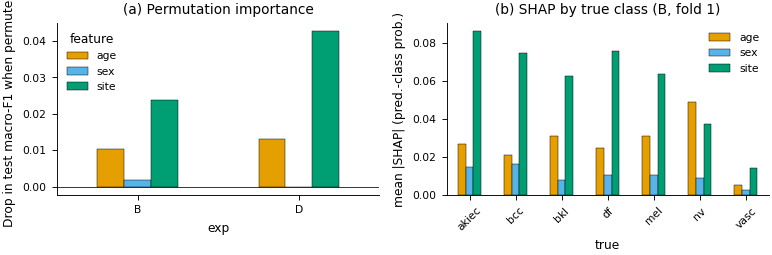

  saved figure: fig_metadata_importance.png, fig_metadata_importance.pdf


In [37]:
# [R7-3][R1-4] Metadata permutation importance and exact group SHAP
from itertools import combinations
META_XAI_EXPS = [c for c in ["B", "D", "H"] if c in EXPERIMENTS]

def image_features(feat_model, exp, frame, dd, ll):
    ds = make_eval_dataset(frame, dd, ll, exp).map(lambda x, y: x["image_input"])
    return feat_model.predict(ds, verbose=0).astype(np.float32)

def head_predict(head, feats, meta, bs=4096):
    return head.predict([feats, meta], batch_size=bs, verbose=0).astype(np.float32)

perm_rows, shap_rows = [], []
for code_ in META_XAI_EXPS:
    exp = EXPERIMENTS[code_]
    for fold in exp_folds(exp):
        model, mp = load_trained(code_, fold)
        if model is None:
            continue
        feat_model, head = split_image_head(model)
        dte, lte = mp.transform(test_df)
        feats = image_features(feat_model, exp, test_df, dte, lte)
        base = head_predict(head, feats, dte)
        ref = load_preds(code_, fold, "test")["probs"]
        assert np.abs(base - ref).max() < 0.02, "image/head split does not reproduce the full model"
        y = test_df.label.values
        mb, _ = compute_metrics(y, base)
        groups = mp.feature_groups()
        rng = np.random.default_rng(SEED + fold)
        for g, cols in groups.items():
            for r in range(CFG["N_PERM_REPEATS"]):
                dp = dte.copy(); dp[:, cols] = dte[rng.permutation(len(dte))][:, cols]
                mpm, _ = compute_metrics(y, head_predict(head, feats, dp))
                perm_rows.append(dict(exp=code_, fold=fold, feature=g, repeat=r,
                                      **{f"drop_{k}": mb[k] - mpm[k] for k in ["macro_f1", "bal_acc", "macro_auc", "mel_recall"]}))
        if fold == CFG["XAI_FOLD"]:
            tr_, _, _ = get_fold_frames(fold)
            bg_rows = tr_.sample(min(CFG["SHAP_BACKGROUND"], len(tr_)), random_state=SEED)
            bg, _ = mp.transform(bg_rows); B = len(bg); names = list(groups)
            M = len(names); w_ = {k: math.factorial(k) * math.factorial(M - k - 1) / math.factorial(M) for k in range(M)}
            pred_cls = base.argmax(1)
            for s0 in range(0, len(dte), 256):
                sl = slice(s0, min(s0 + 256, len(dte))); n = sl.stop - sl.start
                v = {}
                for k in range(M + 1):
                    for S_ in combinations(range(M), k):
                        mix = np.repeat(bg[None], n, 0).copy()                   # n x B x d
                        for gi in S_:
                            mix[:, :, groups[names[gi]]] = dte[sl][:, None, groups[names[gi]]]
                        pr = head_predict(head, np.repeat(feats[sl], B, 0), mix.reshape(n * B, -1)).reshape(n, B, -1).mean(1)
                        v[S_] = pr
                phi = {nm: np.zeros((n, N_CLASSES), np.float32) for nm in names}
                for j, nm in enumerate(names):
                    others = [i for i in range(M) if i != j]
                    for k in range(M):
                        for S_ in combinations(others, k):
                            phi[nm] += w_[k] * (v[tuple(sorted(S_ + (j,)))] - v[S_])
                eff = v[tuple(range(M))] - v[()] - sum(phi.values())
                assert np.abs(eff).max() < 1e-3, "SHAP efficiency check failed"
                for i in range(n):
                    ii = sl.start + i
                    shap_rows.append(dict(exp=code_, fold=fold, image_id=test_df.image_id.iat[ii], true=CLASS_NAMES[y[ii]],
                                          pred=CLASS_NAMES[pred_cls[ii]], base_value_pred=float(v[()][i, pred_cls[ii]]),
                                          **{f"shap_{nm}_pred": float(phi[nm][i, pred_cls[ii]]) for nm in names},
                                          **{f"shap_{nm}_mel": float(phi[nm][i, MEL_IDX]) for nm in names},
                                          **{f"shap_{nm}_true": float(phi[nm][i, y[ii]]) for nm in names}))
        del model, feat_model, head; clear_keras_session(); release_host_memory()

perm_df = pd.DataFrame(perm_rows); perm_df.to_csv(DIRS["results"] / "metadata_permutation_importance.csv", index=False)
shap_df = pd.DataFrame(shap_rows); shap_df.to_csv(DIRS["results"] / "metadata_shap_values.csv", index=False)
if len(perm_df):
    perm_sum = perm_df.groupby(["exp", "feature"]).agg(**{f"{k}_mean": (f"drop_{k}", "mean") for k in ["macro_f1", "bal_acc", "macro_auc", "mel_recall"]},
                                                      **{f"{k}_sd": (f"drop_{k}", "std") for k in ["macro_f1", "macro_auc"]}).reset_index()
    display(perm_sum.round(4))
if len(shap_df):
    cols_ = [c for c in shap_df.columns if c.startswith("shap_") and c.endswith("_pred")]
    shap_sum = shap_df.groupby(["exp", "true"])[cols_].apply(lambda g: g.abs().mean()).reset_index()
    shap_sum.to_csv(DIRS["results"] / "metadata_shap_summary.csv", index=False)
    display(shap_sum.round(4))
    fig, axs = plt.subplots(1, 2, figsize=(FIG_W2, 2.5))
    if len(perm_df):
        pv = perm_df.groupby(["exp", "feature"]).drop_macro_f1.mean().unstack()
        pv.plot.bar(ax=axs[0], color=OKABE_ITO[:pv.shape[1]], edgecolor="black", lw=0.3, rot=0)
        axs[0].axhline(0, color="black", lw=0.5); axs[0].set_ylabel("Drop in test macro-F1 when permuted"); axs[0].set_title("(a) Permutation importance")
    h_ = shap_df[shap_df.exp == ("H" if "H" in set(shap_df.exp) else shap_df.exp.iat[0])]
    hv = h_.groupby("true")[cols_].apply(lambda g: g.abs().mean()).reindex([c for c in CLASS_NAMES if c in set(h_.true)])
    hv.columns = [c.replace("shap_", "").replace("_pred", "") for c in hv.columns]
    hv.plot.bar(ax=axs[1], color=OKABE_ITO[:hv.shape[1]], edgecolor="black", lw=0.3, rot=45)
    axs[1].set_ylabel("mean |SHAP| (pred.-class prob.)"); axs[1].set_title(f"(b) SHAP by true class ({h_.exp.iat[0]}, fold {CFG['XAI_FOLD']})")
    fig.tight_layout(); save_fig(fig, "fig_metadata_importance")
else:
    print("NOT RUN: no trained multimodal model available.")

## 24B. LIME explanations and quantitative faithfulness of the image explanations
**Request:** R1-4 (additional explainability frameworks with qualitative *and quantitative* analyses; success and error case studies).

**Method.**
* **LIME** (`lime_image`, fixed seed): the image is split into `LIME_SEGMENTS` SLIC superpixels; `LIME_SAMPLES` perturbed copies (superpixels replaced by their mean colour) are classified with the patient's own metadata held fixed; a weighted linear surrogate gives each superpixel's contribution to the predicted class.
* **Faithfulness** (deletion / insertion, Petsiuk et al., 2018 style): pixels are ranked by an explanation map (Grad-CAM, LIME, or a random map as control) and progressively replaced by a blurred copy of the image (deletion) or revealed on the blurred copy (insertion) in `FAITH_STEPS` steps. The area under the curve of the originally predicted class probability is recorded: **lower deletion AUC and higher insertion AUC mean a more faithful explanation**. Cases: `N_FAITH_CASES` test images of fold `XAI_FOLD`, chosen by fixed row order stratified by class (not hand-picked). Paired Wilcoxon tests compare methods.
* The same success and error cases as Section 24 are shown with Grad-CAM and LIME side by side.

**Expected output.** `xai_faithfulness.csv`, `xai_faithfulness_summary.csv`, `fig_xai_lime_cases`, `fig_xai_faithfulness`.

In [38]:
# [R1-4] LIME and deletion/insertion faithfulness
from scipy.ndimage import gaussian_filter
_trapz = getattr(np, "trapezoid", None) or np.trapz
try:
    from lime import lime_image
    from lime.wrappers.scikit_image import SegmentationAlgorithm
    LIME_OK = True
except Exception as e:
    LIME_OK = False; print("LIME not available (pip install lime):", e)

faith_rows = []
xai_model, xai_mp = load_trained("H", CFG["XAI_FOLD"])
if xai_model is None or not LIME_OK:
    print("NOT RUN: needs trained H fold", CFG["XAI_FOLD"], "and the lime package.")
else:
    expH = EXPERIMENTS["H"]
    dte_all, lte_all = xai_mp.transform(test_df)
    def clf_fn_for(meta_vec):
        def f(images):
            images = np.asarray(images, np.float32)
            out = xai_model.predict({"image_input": images, "meta_input": np.repeat(meta_vec[None], len(images), 0)},
                                    batch_size=32, verbose=0)
            return out.astype(np.float64)
        return f
    segmenter = SegmentationAlgorithm("slic", n_segments=CFG["LIME_SEGMENTS"], compactness=10, sigma=1, start_label=0)
    import lime.lime_image as _lime_mod
    _lime_mod.tqdm = lambda it, *a, **k: it                 # silence LIME's progress bars (display only)
    lime_exp = lime_image.LimeImageExplainer(random_state=SEED)
    import inspect
    _lime_kw = {"progress_bar": False} if "progress_bar" in inspect.signature(lime_exp.explain_instance).parameters else {}
    def lime_map(img, meta_vec, label):
        e = lime_exp.explain_instance(img.astype(np.float64), clf_fn_for(meta_vec), labels=(label,), top_labels=None, hide_color=None,
                                      num_samples=CFG["LIME_SAMPLES"], batch_size=32, segmentation_fn=segmenter, random_seed=SEED, **_lime_kw)
        heat = np.zeros(e.segments.shape, np.float32)
        for seg, wgt in e.local_exp[label]:
            heat[e.segments == seg] = wgt
        return heat, e.segments
    def curve_auc(img, meta_vec, sal, label, mode):
        blur = gaussian_filter(img, sigma=(S / 25, S / 25, 0))
        order = np.argsort(-sal.ravel(), kind="stable"); n = order.size
        frames = []
        for k in np.linspace(0, 1, CFG["FAITH_STEPS"] + 1):
            m = np.zeros(n, bool); m[order[:int(round(k * n))]] = True; m = m.reshape(sal.shape)[..., None]
            frames.append(np.where(m, blur, img) if mode == "deletion" else np.where(m, img, blur))
        pr = clf_fn_for(meta_vec)(np.stack(frames))[:, label]
        return float(_trapz(pr, dx=1.0 / CFG["FAITH_STEPS"])), pr
    # deterministic case list: fixed row order, round-robin over classes
    per_cls = [test_df.index[test_df.label == c].tolist() for c in range(N_CLASSES)]
    cases, k = [], 0
    while len(cases) < min(CFG["N_FAITH_CASES"], len(test_df)) and any(per_cls):
        c = k % N_CLASSES; k += 1
        if per_cls[c]:
            cases.append(per_cls[c].pop(0))
    rng = np.random.default_rng(SEED); curves = {"gradcam": [], "lime": [], "random": []}
    t0 = time.time()
    for ii in cases:
        r = test_df.iloc[ii]; img = get_image(int(r.row_idx)); mv = dte_all[ii]
        cam, _, pr = gradcam_and_attention(xai_model, expH, img, mv, lte_all[ii])
        label = int(pr.argmax())
        lm, _ = lime_map(img, mv, label)
        for name, sal in [("gradcam", cam), ("lime", lm), ("random", rng.random(cam.shape))]:
            d_auc, d_curve = curve_auc(img, mv, sal, label, "deletion")
            i_auc, i_curve = curve_auc(img, mv, sal, label, "insertion")
            curves[name].append((d_curve, i_curve))
            faith_rows.append(dict(image_id=r.image_id, true=CLASS_NAMES[int(r.label)], pred=CLASS_NAMES[label], method=name,
                                   deletion_auc=d_auc, insertion_auc=i_auc, p_pred=float(pr.max())))
    print(f"Faithfulness on {len(cases)} cases: {(time.time() - t0) / 60:.1f} min")
    faith = pd.DataFrame(faith_rows); faith.to_csv(DIRS["results"] / "xai_faithfulness.csv", index=False)
    fsum = faith.groupby("method")[["deletion_auc", "insertion_auc"]].agg(["mean", "std"]).round(4)
    tests = []
    for a, b_ in [("gradcam", "random"), ("lime", "random"), ("gradcam", "lime")]:
        for m in ["deletion_auc", "insertion_auc"]:
            xa = faith[faith.method == a].set_index("image_id")[m]; xb = faith[faith.method == b_].set_index("image_id")[m]
            dd_ = (xa - xb.loc[xa.index]).values
            try:
                pw = stats.wilcoxon(dd_).pvalue if np.any(dd_ != 0) else 1.0
            except Exception:
                pw = np.nan
            tests.append(dict(comparison=f"{a} vs {b_}", metric=m, mean_diff=dd_.mean(), wilcoxon_p=pw, n=len(dd_)))
    fsum.to_csv(DIRS["results"] / "xai_faithfulness_summary.csv"); pd.DataFrame(tests).to_csv(DIRS["results"] / "xai_faithfulness_tests.csv", index=False)
    display(fsum); display(pd.DataFrame(tests).round(4))

    fig, axs = plt.subplots(1, 2, figsize=(FIG_W2, 2.3)); xs = np.linspace(0, 1, CFG["FAITH_STEPS"] + 1)
    for name, col in [("gradcam", "#D55E00"), ("lime", "#0072B2"), ("random", "#999999")]:
        axs[0].plot(xs, np.mean([c[0] for c in curves[name]], 0), color=col, label=name)
        axs[1].plot(xs, np.mean([c[1] for c in curves[name]], 0), color=col, label=name)
    axs[0].set(xlabel="Fraction of pixels removed", ylabel="p(predicted class)", title="(a) Deletion (lower = more faithful)")
    axs[1].set(xlabel="Fraction of pixels revealed", ylabel="p(predicted class)", title="(b) Insertion (higher = more faithful)")
    axs[0].legend(); fig.tight_layout(); save_fig(fig, "fig_xai_faithfulness")

    # ---- qualitative LIME vs Grad-CAM on the success / error cases of Section 24 ----
    ztest = load_preds("H", CFG["XAI_FOLD"], "test")
    succ, err = select_cases(ztest)
    show = (succ[:4] + err[:4])
    if show:
        fig, axs = plt.subplots(len(show), 3, figsize=(FIG_W1 + 0.8, 1.2 * len(show) + 0.3)); axs = np.atleast_2d(axs)
        from skimage.segmentation import mark_boundaries
        for i, r in enumerate(show):
            ii = int(np.where(test_df.image_id == r.image_id)[0][0]); img = get_image(int(r.row_idx)); mv = dte_all[ii]
            cam, _, pr = gradcam_and_attention(xai_model, expH, img, mv, lte_all[ii]); label = int(pr.argmax())
            lm, segs = lime_map(img, mv, label)
            top = lm >= np.quantile(lm, 0.8)
            axs[i, 0].imshow(img / 255.0); axs[i, 1].imshow(img / 255.0); axs[i, 1].imshow(cam, cmap="jet", alpha=0.45)
            axs[i, 2].imshow(mark_boundaries(img / 255.0 * top[..., None] + 0.25 * img / 255.0 * (~top[..., None]), segs, color=(1, 1, 0)))
            axs[i, 0].set_ylabel(f"true {CLASS_NAMES[int(r.y)]}\npred {CLASS_NAMES[label]} ({pr.max():.2f})", fontsize=6)
            for ax in axs[i]:
                ax.set_xticks([]); ax.set_yticks([])
        for j, t in enumerate(["Image", "Grad-CAM", "LIME (top 20 % superpixels)"]):
            axs[0, j].set_title(t, fontsize=7)
        fig.suptitle("Success (top) and error (bottom) cases: Grad-CAM vs LIME", fontsize=8); fig.tight_layout(); save_fig(fig, "fig_xai_lime_cases")
    del xai_model; clear_keras_session(); release_host_memory()

NOT RUN: needs trained H fold 1 and the lime package.


## 26. Computational analysis
**Request:** R2 minor (inference latency and model size), R1-6 (efficiency comparison), R6 (computational complexity); earlier RQ-11.

**Purpose.** Report the computational cost of the main configurations measured on the hardware this notebook runs on (target: Kaggle Tesla P100-PCIE-16GB).

**Method.**
* **Parameters.** Total, and trainable in Phase 1 (frozen backbone) and Phase 2 (backbone unfrozen, BatchNorm frozen), counted from the model graph.
* **Model size.** Size of a saved `.weights.h5` file (FP32 storage).
* **FLOPs.** Counted with the TensorFlow profiler on a frozen FP32 graph at batch size 1 (`float_ops`, multiply and add counted separately, so FLOPs ≈ 2 × MACs). If the profiler fails, the entry is marked *Requires verification*; no value is estimated.
* **Latency / throughput.** Forward pass only (`training=False`) with the mixed-precision policy used for training, inputs already in device memory (data loading excluded). 10 warm-up calls, then the median of 50 timed calls. Batch 1 = per-image latency; batch `2 × BATCH_SIZE` = throughput. TTA latency = 5 views.
* **Peak GPU memory.** Peak allocator memory during the inference measurement (TensorFlow counter; excludes CUDA context).
* **Training cost.** Seconds per epoch and GPU-hours per unit, read from the saved training logs of completed units.

**Expected output.** `computational_analysis.csv`, `training_cost.csv`, `fig_computational_cost`. On CPU (smoke test) the numbers are meaningless and are labelled with the hardware string.

I0000 00:00:1790481796.013715      23 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1790481796.014010      23 single_machine.cc:376] Starting new session
I0000 00:00:1790481796.029261      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790481796.030971      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
I0000 00:00:1790481862.263849      23 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1790481862.264094      23 single_machine.cc:376] Starting new session
I0000 00:00:1790481862.279527      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> 

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


I0000 00:00:1790482011.389984      23 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1790482011.390183      23 single_machine.cc:376] Starting new session
I0000 00:00:1790482011.405739      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790482011.407424      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


ViT input normalisation: {'scale': [0.007843137718737125, 0.007843137718737125, 0.007843137718737125], 'offset': [-1.0, -1.0, -1.0], 'source': 'preset image converter'}


I0000 00:00:1790482045.839206      23 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1790482045.839412      23 single_machine.cc:376] Starting new session
I0000 00:00:1790482045.854903      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790482045.856644      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


I0000 00:00:1790482094.088843      23 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1790482094.089064      23 single_machine.cc:376] Starting new session
I0000 00:00:1790482094.104432      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790482094.106122      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


,exp,name,params_total,trainable_phase1,trainable_phase2,weights_file_mb,gflops_per_image,flops_status,latency_ms_batch1,latency_ms_per_image_tta5,throughput_img_s,batch_for_throughput,peak_gpu_mem_mb_inference
0,A,EfficientNetB3 only (image-only baseline),12120118,1331207.0,11940143,47.217,4.002,measured,14.333,71.665,181.587,32,1275.225
1,B,EfficientNetB3 + Metadata,12128950,1340039.0,11948975,47.257,4.002,measured,14.285,71.425,181.444,32,1378.465
2,C,EfficientNetB3 + CBAM,12157080,1368169.0,11977105,47.372,4.003,measured,14.521,72.607,179.942,32,1484.973
3,D,EfficientNetB3 + CBAM + Metadata,12165912,1377001.0,11985937,47.412,4.003,measured,14.990,74.951,180.129,32,1661.155
4,H,Full SkinNet,12165912,1377001.0,11985937,47.412,4.003,measured,15.899,79.495,179.239,32,1688.479
5,M0,Metadata-only baseline (CE),44423,NaN,43655,0.204,0.000,measured,1.043,NaN,27957.145,32,1037.985
6,BM_R50,ResNet50 + metadata (same training protocol),24156423,567943.0,24049415,92.641,14.493,measured,8.886,44.428,236.884,32,1622.294
7,BM_VIT,ViT-B/16 + metadata (same training protocol),86039687,240263.0,86038919,328.684,33.813,measured,9.818,49.091,174.843,32,1751.141
8,BM_CNXT,ConvNeXt-Tiny + metadata (same training protocol),28061159,240263.0,28060391,107.454,14.858,measured,9.003,45.015,165.670,32,1530.103


Hardware: Tesla T4 | Intel(R) Xeon(R) CPU @ 2.00GHz | TF 2.20.0 | mixed_float16


fold        unit_gpu_h        peak_gpu_mb_train        p1_epochs_run      p1_s_per_epoch        p2_epochs_run        p2_s_per_epoch        
    mean    std       mean    std              mean    std          mean  std           mean    std          mean    std           mean     std
exp                                                                                                                                            
A    3.0  1.581      0.666  0.033          1920.283  0.023          15.0  0.0         70.298  3.858          10.8  1.789        113.493   6.370
B    3.0  1.581      0.719  0.085          1920.301  0.000          15.0  0.0         73.285  2.788          12.6  4.278        110.141  12.807
C    3.0  1.581      0.700  0.077          1920.605  0.000          15.0  0.0         65.888  6.036          11.6  2.702        119.701   9.280
D    3.0  1.581      0.706  0.039          1920.760  0.157          15.0  0.0         63.225  5.087          10.8  1.643        124.703  14.190
E    3.0  1.581      0.702  0.080          1919.458  0.000          15.0  0.0         64.964  3.741          11.6  3.578        125.447  14.537
F    3.0  1.581      0.538  0.040          1908.956  0.055           NaN  NaN            NaN    NaN          14.6  1.342        123.670   5.449
M0   3.0  1.581      0.024  0.011           209.959  0.000           NaN  NaN            NaN    NaN          21.4  8.355          3.857   1.006

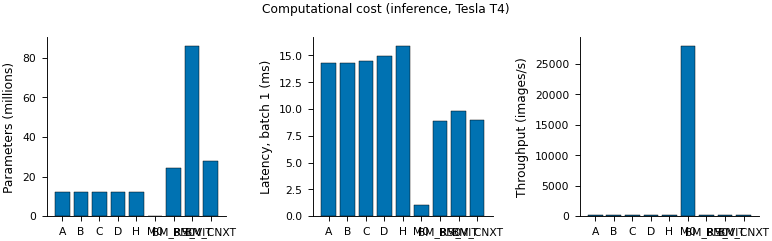

  saved figure: fig_computational_cost.png, fig_computational_cost.pdf


,key_0,model,code,folds,params_total,gflops_per_image,weights_file_mb,latency_ms_batch1,throughput_img_s,train_gpu_h_per_fold
0,H,Full SkinNet without TTA,I,0/5,12165912,4.002786,47.411888,15.899016,179.238563,NaN
1,BM_R50,ResNet50 + metadata (same training protocol),BM_R50,0/5,24156423,14.492850,92.640930,8.885567,236.883583,NaN
2,BM_VIT,ViT-B/16 + metadata (same training protocol),BM_VIT,0/5,86039687,33.813163,328.684296,9.818295,174.843404,NaN
3,BM_CNXT,ConvNeXt-Tiny + metadata (same training protocol),BM_CNXT,0/5,28061159,14.858163,107.453537,9.002948,165.670439,NaN


In [39]:
# [RQ-11] Computational analysis
from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2

HW_STR = f"{HW['gpu_name'] or 'CPU only'} | {HW['cpu_model']} | TF {HW['tensorflow']} | {keras.mixed_precision.global_policy().name}"
N_WARM, N_TIME = (2, 5) if SMOKE_TEST else (10, 50)
COMP_EXPS = [c for c in ["A", "B", "C", "D", "H", "M0", "BM_R50", "BM_D121", "BM_V2S", "BM_VIT", "BM_CNXT"]
             if c in EXPERIMENTS and (EXPERIMENTS[c].backbone != "vit_b16" or VIT_READY)
             and (not c.startswith("BM_") or c in PROFILES[CFG["RUN_PROFILE"]] or read_status(unit_dir(c, 1, create=False)).get("done"))]
_tr, _, _ = get_fold_frames(1)
_mp = MetaPreprocessor(CFG["LOC_ENCODING"]).fit(_tr)

def dummy_inputs(model, batch):
    out = []
    for t in model.inputs:
        dt, shp = tf.as_dtype(t.dtype), [batch] + list(t.shape[1:])
        out.append(tf.random.uniform(shp, 0, 1, dtype=dt) if dt.is_floating else tf.zeros(shp, dtype=dt))
    return out

def count_flops(exp):
    """FLOPs of one forward pass (batch 1) on a frozen FP32 graph. Returns None if the profiler fails or RAM is low."""
    if HW.get("ram_gb") and host_rss_gb() > 0.6 * HW["ram_gb"]:
        print(f"  FLOP count skipped for {exp.code}: host RAM {host_rss_gb():.1f} GB in use (restart the kernel and re-run this cell)")
        return None
    old = keras.mixed_precision.global_policy().name
    try:
        keras.mixed_precision.set_global_policy("float32")
        m = build_skinnet(exp, _mp.dense_dim, n_loc=len(_mp.loc_vocab), weights="cfg")
        spec = [tf.TensorSpec([1] + list(t.shape[1:]), tf.as_dtype(t.dtype)) for t in m.inputs]
        conc = tf.function(lambda *x: m(list(x), training=False)).get_concrete_function(*spec)
        frozen = convert_variables_to_constants_v2(conc)
        with tf.Graph().as_default() as g:
            tf.graph_util.import_graph_def(frozen.graph.as_graph_def(), name="")
            opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()
            opts["output"] = "none"
            prof = tf.compat.v1.profiler.profile(graph=g, run_meta=tf.compat.v1.RunMetadata(), cmd="op", options=opts)
        return int(prof.total_float_ops) if prof is not None else None
    except Exception as e:
        print(f"  FLOP count failed for {exp.code}: {type(e).__name__}: {e}")
        return None
    finally:
        keras.mixed_precision.set_global_policy(old)
        clear_keras_session(); release_host_memory()

def time_forward(fn, xs):
    for _ in range(N_WARM):
        _ = fn(xs).numpy()
    ts = []
    for _ in range(N_TIME):
        t0 = time.perf_counter(); _ = fn(xs).numpy(); ts.append(time.perf_counter() - t0)
    return float(np.median(ts))

comp_rows = []
def _comp_one(code_):
    exp = EXPERIMENTS[code_]
    flops = count_flops(exp)
    clear_keras_session(); gc.collect()
    model = build_skinnet(exp, _mp.dense_dim, n_loc=len(_mp.loc_vocab), weights="cfg")
    set_phase(model, 1); p1_tr, _ = count_params(model)
    set_phase(model, 2); p2_tr, p2_nt = count_params(model)
    tmp = DIRS["logs"] / f"_size_probe_{code_}.weights.h5"
    model.save_weights(tmp); size_mb = tmp.stat().st_size / 2**20; tmp.unlink()
    fwd = tf.function(lambda x: model(x, training=False))
    if GPUS:
        try: tf.config.experimental.reset_memory_stats("GPU:0")
        except Exception: pass
    x1, xb = dummy_inputs(model, 1), dummy_inputs(model, 2 * BATCH_SIZE)
    lat1 = time_forward(fwd, x1)
    latb = time_forward(fwd, xb)
    peak = None
    if GPUS:
        try: peak = tf.config.experimental.get_memory_info("GPU:0")["peak"] / 2**20
        except Exception: pass
    comp_rows.append(dict(exp=code_, name=exp.name, params_total=p2_tr + p2_nt, trainable_phase1=p1_tr if exp.two_phase else np.nan,
                          trainable_phase2=p2_tr, weights_file_mb=size_mb,
                          gflops_per_image=flops / 1e9 if flops else np.nan,
                          flops_status="measured" if flops else "Requires verification",
                          latency_ms_batch1=lat1 * 1e3, latency_ms_per_image_tta5=lat1 * 1e3 * CFG["TTA_VIEWS"] if exp.use_image else np.nan,
                          throughput_img_s=2 * BATCH_SIZE / latb, batch_for_throughput=2 * BATCH_SIZE,
                          peak_gpu_mem_mb_inference=peak, hardware=HW_STR))
    del model, fwd; clear_keras_session(); release_host_memory()

for code_ in COMP_EXPS:                   # a model that cannot be built is reported, never stops the notebook
    try:
        _comp_one(code_)
    except Exception as e:
        print(f"  ⚠ computational analysis skipped for {code_}: {type(e).__name__}: {str(e)[:200]}")
        comp_rows.append(dict(exp=code_, name=EXPERIMENTS[code_].name, flops_status="Requires verification (model could not be built)", hardware=HW_STR))
        clear_keras_session(); release_host_memory()

comp = pd.DataFrame(comp_rows)
comp.to_csv(DIRS["results"] / "computational_analysis.csv", index=False)
display(comp.drop(columns=["hardware"]).round(3))
print("Hardware:", HW_STR)

# ---- training cost from logs of completed units ----
cost_rows = []
for code_, exp in EXPERIMENTS.items():
    for f in range(1, CFG["N_FOLDS"] + 1):
        d = unit_dir(code_, f, create=False); st = read_status(d)
        if not st.get("done"):
            continue
        row = dict(exp=code_, fold=f, unit_gpu_h=st.get("unit_seconds", np.nan) / 3600, peak_gpu_mb_train=st.get("peak_gpu_mb", np.nan))
        for ph in (1, 2):
            hp = d / f"history_p{ph}.csv"
            if hp.exists() and st.get(f"p{ph}_seconds"):
                n_ep = len(pd.read_csv(hp)); row[f"p{ph}_epochs_run"] = n_ep
                row[f"p{ph}_s_per_epoch"] = st[f"p{ph}_seconds"] / max(n_ep, 1)
        cost_rows.append(row)
train_cost = pd.DataFrame(cost_rows)
if len(train_cost):
    train_cost.to_csv(DIRS["results"] / "training_cost.csv", index=False)
    display(train_cost.groupby("exp").agg(["mean", "std"]).round(3))
else:
    print("No completed training units yet: training cost not available.")

fig, axs = plt.subplots(1, 3, figsize=(FIG_W2, 2.3))
xs = np.arange(len(comp))
for ax, col, lab in zip(axs, ["params_total", "latency_ms_batch1", "throughput_img_s"],
                        ["Parameters (millions)", "Latency, batch 1 (ms)", "Throughput (images/s)"]):
    v = comp[col] / (1e6 if col == "params_total" else 1)
    ax.bar(xs, v, color="#0072B2", edgecolor="black", lw=0.3)
    ax.set_xticks(xs); ax.set_xticklabels(comp.exp); ax.set_ylabel(lab)
fig.suptitle(f"Computational cost (inference, {HW['gpu_name'] or 'CPU'})", fontsize=8)
fig.tight_layout()
save_fig(fig, "fig_computational_cost")

# ---- efficiency columns for the benchmark table (Section 20A) [R1-6] ----
if "bench_tab" in globals() and len(bench_tab):
    eff = comp.set_index("exp")[["params_total", "gflops_per_image", "weights_file_mb", "latency_ms_batch1", "throughput_img_s"]]
    bt = bench_tab.copy(); bt["_k"] = bt.code.replace({"I": "H"})
    bt = bt.merge(eff, left_on="_k", right_index=True, how="left").drop(columns="_k")
    if len(train_cost):
        bt = bt.merge(train_cost.groupby("exp").unit_gpu_h.mean().rename("train_gpu_h_per_fold"), left_on=bt.code.replace({"I": "H"}), right_index=True, how="left")
    bt.to_csv(DIRS["results"] / "benchmark_table_with_efficiency.csv", index=False)
    display(bt)

## 26B. Mixed precision: effect on accuracy, numerics, speed and memory
**Request:** R2-M1 (mixed precision is listed as a core contribution but not isolated).

**Method.** (a) **Accuracy:** Full SkinNet trained with FP16 mixed precision (H, fold 1) vs trained entirely in FP32 (H_FP32, fold 1, same seed and data), on validation and test. (b) **Numerics:** the trained FP16 model's weights are evaluated under an FP32 policy; label agreement and probability differences show how much FP16 arithmetic changes inference. (c) **Cost:** training step time and peak GPU memory (batch 16, full fine-tuning) and inference latency under each policy, on the same GPU. One fold is used because mixed precision is a computational technique; a repeated-run baseline (H_REP, Section 21A) gives the size of run-to-run noise for comparison.

**Expected output.** `mixed_precision_accuracy.csv`, `mixed_precision_cost.csv`.

In [40]:
# [R2-M1] Mixed precision vs FP32
mp_rows = []
for code_ in ["H", "H_FP32", "H_REP"]:
    for kind in ["val", "test"]:
        z_ = load_preds(code_, 1, kind) if code_ in EXPERIMENTS else None
        if z_ is not None:
            m_, _ = compute_metrics(z_["y_true"].astype(int), z_["probs"])
            mp_rows.append(dict(exp=code_, precision=EXPERIMENTS[code_].precision, split=kind,
                                **{k: m_[k] for k in ["macro_f1", "bal_acc", "macro_auc", "mcc", "mel_recall", "ece"]}))
mp_acc = pd.DataFrame(mp_rows)
m_h, mp_h = load_trained("H", 1)
if m_h is not None:                                # (b) same trained weights, FP32 arithmetic
    old = keras.mixed_precision.global_policy().name
    try:
        keras.mixed_precision.set_global_policy("float32")
        m32 = build_skinnet(EXPERIMENTS["H"], mp_h.dense_dim, n_loc=len(mp_h.loc_vocab), weights="cfg"); set_phase(m32, 2)
        m32.load_weights(DIRS["runs"] / "H" / "fold_1" / "best_p2.weights.h5")
        dte_, lte_ = mp_h.transform(test_df)
        p32 = predict_probs(m32, make_eval_dataset(test_df, dte_, lte_, EXPERIMENTS["H"]))
        p16 = load_preds("H", 1, "test")["probs"]
        mp_acc = pd.concat([mp_acc, pd.DataFrame([dict(exp="H weights, FP32 inference", precision="fp32 inference", split="test",
                                                        label_agreement_vs_fp16=float((p32.argmax(1) == p16.argmax(1)).mean()),
                                                        max_abs_prob_diff=float(np.abs(p32 - p16).max()))])], ignore_index=True)
        del m32
    finally:
        keras.mixed_precision.set_global_policy(old)
    del m_h; clear_keras_session(); release_host_memory()
mp_acc.to_csv(DIRS["results"] / "mixed_precision_accuracy.csv", index=False)
display(mp_acc.round(4) if len(mp_acc) else "NOT RUN")

cost_rows = []                                     # (c) speed and memory under each policy
n_steps = 3 if SMOKE_TEST else 20
for pol in ["mixed_float16", "float32"]:
    old = keras.mixed_precision.global_policy().name
    try:
        keras.mixed_precision.set_global_policy(pol); clear_keras_session()
        _m = build_skinnet(EXPERIMENTS["H"], _mp.dense_dim, n_loc=len(_mp.loc_vocab), weights="cfg"); set_phase(_m, 2)
        _m.compile(keras.optimizers.Adam(1e-5), SkinNetLoss(**LOSS_SETTINGS["focal_ls"]))
        xb = dummy_inputs(_m, BATCH_SIZE); yb_ = tf.one_hot(tf.zeros([BATCH_SIZE], tf.int32), N_CLASSES)
        xd = {t.name.split(":")[0]: v for t, v in zip(_m.inputs, xb)}
        if GPUS:
            try: tf.config.experimental.reset_memory_stats("GPU:0")
            except Exception: pass
        _m.train_on_batch(xd, yb_)
        t0 = time.perf_counter()
        for _ in range(n_steps):
            _m.train_on_batch(xd, yb_)
        step = (time.perf_counter() - t0) / n_steps
        peak = tf.config.experimental.get_memory_info("GPU:0")["peak"] / 2**20 if GPUS else np.nan
        fwd = tf.function(lambda x: _m(x, training=False)); lat = time_forward(fwd, dummy_inputs(_m, 1))
        cost_rows.append(dict(policy=pol, train_s_per_step_bs16=step, peak_gpu_mb_train=peak, latency_ms_batch1=lat * 1e3, hardware=HW_STR))
        del _m, fwd
    except Exception as e:
        cost_rows.append(dict(policy=pol, error=f"{type(e).__name__}: {str(e)[:150]}"))
    finally:
        keras.mixed_precision.set_global_policy(old); clear_keras_session(); release_host_memory()
mp_cost = pd.DataFrame(cost_rows); mp_cost.to_csv(DIRS["results"] / "mixed_precision_cost.csv", index=False)
display(mp_cost.round(4))

'NOT RUN'

,policy,train_s_per_step_bs16,peak_gpu_mb_train,latency_ms_batch1,hardware
0,mixed_float16,0.0735,2940.5952,15.5143,Tesla T4 | Intel(R) Xeon(R) CPU @ 2.00GHz | TF...
1,float32,0.1818,4531.4910,13.3859,Tesla T4 | Intel(R) Xeon(R) CPU @ 2.00GHz | TF...


## 26A. Release package and environment record
**Request:** R1-1 (open-source code, trained models, preprocessing scripts), R1-11 (hyper-parameters, software/hardware), R4-9 (reproducibility information actually supplied), R2 minor (L2 in the metadata branch), R8-4 (metadata dimension), R8-5 (per-fold scaler), R8-6 (site encoding).

**Contents of `/kaggle/working/skinnet_release/`.**
* `weights/H_fold{k}.weights.h5` — Full SkinNet, all folds (plus the other arms' weights if `RELEASE_ALL_WEIGHTS=True`).
* `preprocessing/metadata_fold{k}.json` — the metadata preprocessor of each training fold (age median and min/max, sex categories, site vocabulary, feature order).
* `skinnet_infer.py` — stand-alone inference script (image + age/sex/site → 7 probabilities), `README.md`, `config/` (cfg.json, experiments.json), `requirements_freeze.txt`, `environment.json`, `hyperparameters.csv`, `architecture_consistency.json`.
Upload this folder with the notebook to the public repository (e.g. GitHub + Zenodo DOI) and cite it in the manuscript.

**Expected output.** The release folder and `hyperparameters.csv`, `architecture_consistency.json`.

In [41]:
# [WORKER-SKIP]
# [R1-1][R1-11][R8-4][R8-5] Release package
RELEASE_ALL_WEIGHTS = False
REL = WORK / ("skinnet_release_smoke" if SMOKE_TEST else "skinnet_release")
for sub in ["weights", "preprocessing", "config"]:
    (REL / sub).mkdir(parents=True, exist_ok=True)
n_w = 0
for code_ in (EXPERIMENTS if RELEASE_ALL_WEIGHTS else ["H"]):
    for f in exp_folds(EXPERIMENTS[code_]):
        src = unit_dir(code_, f, create=False) / "best_p2.weights.h5"
        if src.exists():
            shutil.copy2(src, REL / "weights" / f"{code_}_fold{f}.weights.h5"); n_w += 1
for f in FOLDS:
    mpf = MetaPreprocessor(CFG["LOC_ENCODING"]).fit(get_fold_frames(f)[0])
    (REL / "preprocessing" / f"metadata_fold{f}.json").write_text(json.dumps(mpf.to_json(), indent=2))
for fn in ["cfg.json", "experiments.json", "environment.json"]:
    if (DIRS["config"] / fn).exists():
        shutil.copy2(DIRS["config"] / fn, REL / "config" / fn)
try:
    (REL / "requirements_freeze.txt").write_text(subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True, timeout=120).stdout)
except Exception as e:
    print("pip freeze failed:", e)
hp = pd.DataFrame([(k, json.dumps(v) if isinstance(v, (list, dict)) else v) for k, v in CFG.items()], columns=["parameter", "value"])
hp.to_csv(REL / "hyperparameters.csv", index=False); hp.to_csv(DIRS["results"] / "hyperparameters.csv", index=False)

# ---- architecture consistency report (reviewers 2 and 8) ----
_mp1 = MetaPreprocessor(CFG["LOC_ENCODING"]).fit(get_fold_frames(1)[0])
_mH = build_skinnet(EXPERIMENTS["H"], _mp1.dense_dim, n_loc=len(_mp1.loc_vocab), weights="cfg")
_md = _mH.get_layer("meta_dense")
consistency = dict(
    metadata_input_dimension=_mp1.dense_dim, metadata_feature_order=_mp1.feature_names(),
    metadata_encoding="age: median-imputed, min-max scaled on the training fold; sex: one-hot (male, female, unknown); "
                      f"site: one-hot over {len(_mp1.loc_vocab)} training-fold categories incl. 'unknown'",
    scaler_fitted="per training fold (Section 9 asserts); never on validation, test or BCN20000",
    meta_dense_units=_md.units, meta_dense_activation=_md.activation.__name__,
    meta_dense_l2=float(getattr(_md.kernel_regularizer, "l2", np.nan)) if _md.kernel_regularizer is not None else None,
    head_l2=CFG["L2"], dropout=[CFG["DROPOUT_1"], CFG["DROPOUT_2"]], dense_units=[CFG["DENSE_1"], CFG["DENSE_2"]],
    total_params_H=int(_mH.count_params()), loss=LOSS_SETTINGS["focal_ls"], optimizer="Adam, cosine decay with linear warm-up, clipnorm 1.0",
    gpu=HW.get("gpu_name"), tensorflow=HW["tensorflow"], keras=HW["keras"], precision=keras.mixed_precision.global_policy().name)
del _mH; clear_keras_session()
(REL / "architecture_consistency.json").write_text(json.dumps(consistency, indent=2, default=str))
(DIRS["results"] / "architecture_consistency.json").write_text(json.dumps(consistency, indent=2, default=str))
print(json.dumps(consistency, indent=1, default=str)[:1500])

import base64
_hdr = f"""# SkinNet model definition exported from the notebook (Section 13). Research use only.
import json, numpy as np, keras
from keras import layers
from types import SimpleNamespace
_reg = keras.saving.register_keras_serializable
def _safe_reg(package="skinnet", name=None):
    def deco(c):
        try:
            return _reg(package=package, name=name)(c)
        except ValueError:          # already registered in this process
            return c
    return deco
keras.saving.register_keras_serializable = _safe_reg
SYNTHETIC = False
CFG = json.loads({json.dumps(json.dumps(CFG, default=str))})
S = CFG["IMG_SIZE"]; N_CLASSES = 7; KERAS_HUB_OK = False
H_EXP = SimpleNamespace(code="H", use_image=True, use_meta=True, use_cbam=True, backbone="effb3")
class MetaVector:
    def __init__(self, spec):
        self.s = spec; self.dense_dim = len(spec["feature_order"])
    def vector(self, age, sex, site):
        s = self.s; a = s["age_median"] if age is None else float(age)
        v = [(a - s["age_min"]) / max(s["age_max"] - s["age_min"], 1e-9)]
        sex = sex if sex in ("male", "female") else "unknown"
        v += [float(sex == c) for c in s["sex_categories"]]
        site = site if site in s["loc_vocab"] else "unknown"
        v += [float(site == c) for c in s["loc_vocab"]]
        return np.asarray(v, np.float32)
"""
(REL / "skinnet_model.py").write_text(_hdr + base64.b64decode("IyBbUlEtMDFdW1JRLTA1XVtSUS0xMF0gTW9kZWwgYnVpbGRlcgpAa2VyYXMuc2F2aW5nLnJlZ2lzdGVyX2tlcmFzX3NlcmlhbGl6YWJsZShwYWNrYWdlPSJza2lubmV0IikKY2xhc3MgQ2hhbm5lbEF0dGVudGlvbihsYXllcnMuTGF5ZXIpOgogICAgZGVmIF9faW5pdF9fKHNlbGYsIGNoYW5uZWxzLCByYXRpbz04LCAqKmt3KToKICAgICAgICBzdXBlcigpLl9faW5pdF9fKCoqa3cpCiAgICAgICAgc2VsZi5jaGFubmVscywgc2VsZi5yYXRpbyA9IGNoYW5uZWxzLCByYXRpbwogICAgICAgIHNlbGYuZDEgPSBsYXllcnMuRGVuc2UobWF4KDEsIGNoYW5uZWxzIC8vIHJhdGlvKSwgYWN0aXZhdGlvbj0icmVsdSIsIHVzZV9iaWFzPUZhbHNlKQogICAgICAgIHNlbGYuZDIgPSBsYXllcnMuRGVuc2UoY2hhbm5lbHMsIHVzZV9iaWFzPUZhbHNlKQogICAgICAgIHNlbGYuZ2FwLCBzZWxmLmdtcCA9IGxheWVycy5HbG9iYWxBdmVyYWdlUG9vbGluZzJEKCksIGxheWVycy5HbG9iYWxNYXhQb29saW5nMkQoKQogICAgZGVmIGNhbGwoc2VsZiwgeCk6CiAgICAgICAgYXR0biA9IGtlcmFzLm9wcy5zaWdtb2lkKHNlbGYuZDIoc2VsZi5kMShzZWxmLmdhcCh4KSkpICsgc2VsZi5kMihzZWxmLmQxKHNlbGYuZ21wKHgpKSkpCiAgICAgICAgcmV0dXJuIHggKiBrZXJhcy5vcHMucmVzaGFwZShrZXJhcy5vcHMuY2FzdChhdHRuLCB4LmR0eXBlKSwgKC0xLCAxLCAxLCBzZWxmLmNoYW5uZWxzKSkKICAgIGRlZiBnZXRfY29uZmlnKHNlbGYpOgogICAgICAgIHJldHVybiB7KipzdXBlcigpLmdldF9jb25maWcoKSwgImNoYW5uZWxzIjogc2VsZi5jaGFubmVscywgInJhdGlvIjogc2VsZi5yYXRpb30KCkBrZXJhcy5zYXZpbmcucmVnaXN0ZXJfa2VyYXNfc2VyaWFsaXphYmxlKHBhY2thZ2U9InNraW5uZXQiKQpjbGFzcyBTcGF0aWFsQXR0ZW50aW9uKGxheWVycy5MYXllcik6CiAgICBkZWYgX19pbml0X18oc2VsZiwgKiprdyk6CiAgICAgICAgc3VwZXIoKS5fX2luaXRfXygqKmt3KQogICAgICAgIHNlbGYuY29udiA9IGxheWVycy5Db252MkQoMSwgNywgcGFkZGluZz0ic2FtZSIsIGFjdGl2YXRpb249InNpZ21vaWQiLCB1c2VfYmlhcz1GYWxzZSwgZHR5cGU9ImZsb2F0MzIiKQogICAgZGVmIGF0dGVudGlvbl9tYXAoc2VsZiwgeCk6CiAgICAgICAgcG9vbGVkID0ga2VyYXMub3BzLmNvbmNhdGVuYXRlKFtrZXJhcy5vcHMuY2FzdChrZXJhcy5vcHMubWVhbih4LCAtMSwga2VlcGRpbXM9VHJ1ZSksICJmbG9hdDMyIiksCiAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICBrZXJhcy5vcHMuY2FzdChrZXJhcy5vcHMubWF4KHgsIC0xLCBrZWVwZGltcz1UcnVlKSwgImZsb2F0MzIiKV0sIC0xKQogICAgICAgIHJldHVybiBzZWxmLmNvbnYocG9vbGVkKQogICAgZGVmIGNhbGwoc2VsZiwgeCk6CiAgICAgICAgcmV0dXJuIGtlcmFzLm9wcy5jYXN0KGtlcmFzLm9wcy5jYXN0KHgsICJmbG9hdDMyIikgKiBzZWxmLmF0dGVudGlvbl9tYXAoeCksIHguZHR5cGUpCgpkZWYgcmVmaW5lbWVudF9ibG9jayh4LCBvdXRfY2gpOgogICAgb3V0ID0gbGF5ZXJzLkRlcHRod2lzZUNvbnYyRCgzLCBwYWRkaW5nPSJzYW1lIiwgdXNlX2JpYXM9RmFsc2UsIG5hbWU9InJlZmluZV9kdyIpKHgpCiAgICBvdXQgPSBsYXllcnMuQWN0aXZhdGlvbigicmVsdSIsIG5hbWU9InJlZmluZV9yZWx1MSIpKGxheWVycy5CYXRjaE5vcm1hbGl6YXRpb24obmFtZT0icmVmaW5lX2JuMSIpKG91dCkpCiAgICBvdXQgPSBsYXllcnMuQ29udjJEKG91dF9jaCwgMSwgcGFkZGluZz0ic2FtZSIsIHVzZV9iaWFzPUZhbHNlLCBuYW1lPSJyZWZpbmVfcHciKShvdXQpCiAgICBvdXQgPSBsYXllcnMuQWN0aXZhdGlvbigicmVsdSIsIG5hbWU9InJlZmluZV9yZWx1MiIpKGxheWVycy5CYXRjaE5vcm1hbGl6YXRpb24obmFtZT0icmVmaW5lX2JuMiIpKG91dCkpCiAgICBpZiB4LnNoYXBlWy0xXSAhPSBvdXRfY2g6CiAgICAgICAgeCA9IGxheWVycy5CYXRjaE5vcm1hbGl6YXRpb24obmFtZT0icmVmaW5lX3Byb2pfYm4iKShsYXllcnMuQ29udjJEKG91dF9jaCwgMSwgcGFkZGluZz0ic2FtZSIsIHVzZV9iaWFzPUZhbHNlLCBuYW1lPSJyZWZpbmVfcHJvaiIpKHgpKQogICAgcmV0dXJuIGxheWVycy5BZGQobmFtZT0icmVmaW5lX291dCIpKFtvdXQsIHhdKQoKZGVmIGdldF9iYWNrYm9uZSh3ZWlnaHRzKToKICAgIHRyeToKICAgICAgICByZXR1cm4ga2VyYXMuYXBwbGljYXRpb25zLkVmZmljaWVudE5ldEIzKGluY2x1ZGVfdG9wPUZhbHNlLCB3ZWlnaHRzPXdlaWdodHMsIGlucHV0X3NoYXBlPShTLCBTLCAzKSkKICAgIGV4Y2VwdCBFeGNlcHRpb24gYXMgZToKICAgICAgICBwYXRoID0gQ0ZHLmdldCgiQkFDS0JPTkVfV0VJR0hUU19QQVRIIikKICAgICAgICBpZiB3ZWlnaHRzID09ICJpbWFnZW5ldCIgYW5kIHBhdGg6CiAgICAgICAgICAgIGJiID0ga2VyYXMuYXBwbGljYXRpb25zLkVmZmljaWVudE5ldEIzKGluY2x1ZGVfdG9wPUZhbHNlLCB3ZWlnaHRzPU5vbmUsIGlucHV0X3NoYXBlPShTLCBTLCAzKSkKICAgICAgICAgICAgYmIubG9hZF93ZWlnaHRzKHBhdGgpOyByZXR1cm4gYmIKICAgICAgICByYWlzZSBSdW50aW1lRXJyb3IoIkNvdWxkIG5vdCBvYnRhaW4gSW1hZ2VOZXQgd2VpZ2h0cy4gVHVybiBLYWdnbGUgSW50ZXJuZXQgT04gb3Igc2V0IEJBQ0tCT05FX1dFSUdIVFNfUEFUSC4iKSBmcm9tIGUKCkBrZXJhcy5zYXZpbmcucmVnaXN0ZXJfa2VyYXNfc2VyaWFsaXphYmxlKHBhY2thZ2U9InNraW5uZXQiKQpjbGFzcyBJbnB1dE5vcm1hbGl6ZShsYXllcnMuTGF5ZXIpOgogICAgIiIiQmFja2JvbmUtc3BlY2lmaWMgaW5wdXQgbm9ybWFsaXNhdGlvbiBmcm9tIFJHQiBbMCwgMjU1XSAoZmxvYXQzMiBhcml0aG1ldGljKS4iIiIKICAgIGRlZiBfX2luaXRfXyhzZWxmLCBtb2RlPSJ0b3JjaCIsIHNjYWxlPU5vbmUsIG9mZnNldD1Ob25lLCAqKmt3KToKICAgICAgICBrdy5zZXRkZWZhdWx0KCJkdHlwZSIsICJmbG9hdDMyIikKICAgICAgICBzdXBlcigpLl9faW5pdF9fKCoqa3cpCiAgICAgICAgc2VsZi5tb2RlLCBzZWxmLnNjYWxlLCBzZWxmLm9mZnNldCA9IG1vZGUsIHNjYWxlLCBvZmZzZXQKICAgIGRlZiBjYWxsKHNlbGYsIHgpOgogICAgICAgIHggPSBrZXJhcy5vcHMuY2FzdCh4LCAiZmxvYXQzMiIpCiAgICAgICAgaWYgc2VsZi5tb2RlID09ICJjYWZmZSI6ICAgICAgICAgICAgICAgICAgICAgIyBSZXNOZXQ1MDogUkdCLT5CR1IsIEltYWdlTmV0IG1lYW4gc3VidHJhY3Rpb24KICAgICAgICAgICAgeCA9IGtlcmFzLm9wcy5mbGlwKHgsIGF4aXM9LTEpIC0ga2VyYXMub3BzLmNvbnZlcnRfdG9fdGVuc29yKFsxMDMuOTM5LCAxMTYuNzc5LCAxMjMuNjhdLCAiZmxvYXQzMiIpCiAgICAgICAgZWxpZiBzZWxmLm1vZGUgPT0gInRvcmNoIjogICAgICAgICAgICAgICAgICAgIyBEZW5zZU5ldDEyMTogWzAsMV0gdGhlbiBJbWFnZU5ldCBtZWFuL3N0ZAogICAgICAgICAgICB4ID0gKHggLyAyNTUuMCAtIGtlcmFzLm9wcy5jb252ZXJ0X3RvX3RlbnNvcihbMC40ODUsIDAuNDU2LCAwLjQwNl0sICJmbG9hdDMyIikpIC8ga2VyYXMub3BzLmNvbnZlcnRfdG9fdGVuc29yKFswLjIyOSwgMC4yMjQsIDAuMjI1XSwgImZsb2F0MzIiKQogICAgICAgIGVsaWYgc2VsZi5tb2RlID09ICJzY2FsZV9vZmZzZXQiOiAgICAgICAgICAgICMgVmlUOiBwcmVzZXQgaW1hZ2UtY29udmVydGVyIHNjYWxlL29mZnNldAogICAgICAgICAgICB4ID0geCAqIGtlcmFzLm9wcy5jb252ZXJ0X3RvX3RlbnNvcihucC5hc2FycmF5KHNlbGYuc2NhbGUsICJmbG9hdDMyIikpICsga2VyYXMub3BzLmNvbnZlcnRfdG9fdGVuc29yKG5wLmFzYXJyYXkoc2VsZi5vZmZzZXQsICJmbG9hdDMyIikpCiAgICAgICAgcmV0dXJuIHgKICAgIGRlZiBnZXRfY29uZmlnKHNlbGYpOgogICAgICAgIHJldHVybiB7KipzdXBlcigpLmdldF9jb25maWcoKSwgIm1vZGUiOiBzZWxmLm1vZGUsICJzY2FsZSI6IHNlbGYuc2NhbGUsICJvZmZzZXQiOiBzZWxmLm9mZnNldH0KCkBrZXJhcy5zYXZpbmcucmVnaXN0ZXJfa2VyYXNfc2VyaWFsaXphYmxlKHBhY2thZ2U9InNraW5uZXQiKQpjbGFzcyBDbGFzc1Rva2VuKGxheWVycy5MYXllcik6CiAgICBkZWYgY2FsbChzZWxmLCB4KToKICAgICAgICByZXR1cm4geFs6LCAwLCA6XQoKQkFDS0JPTkVTID0geyAgICMgbmFtZTogKGNvbnN0cnVjdG9yLCBpbnB1dCBub3JtYWxpc2F0aW9uLCBvdXRwdXQga2luZCwgZGlzcGxheSBuYW1lKQogICAgImVmZmIzIjogKE5vbmUsIE5vbmUsICJtYXAiLCAiRWZmaWNpZW50TmV0QjMiKSwKICAgICJyZXNuZXQ1MCI6IChsYW1iZGEgKiprOiBrZXJhcy5hcHBsaWNhdGlvbnMuUmVzTmV0NTAoKiprKSwgImNhZmZlIiwgIm1hcCIsICJSZXNOZXQ1MCIpLAogICAgImRlbnNlbmV0MTIxIjogKGxhbWJkYSAqKms6IGtlcmFzLmFwcGxpY2F0aW9ucy5EZW5zZU5ldDEyMSgqKmspLCAidG9yY2giLCAibWFwIiwgIkRlbnNlTmV0MTIxIiksCiAgICAiY29udm5leHRfdGlueSI6IChsYW1iZGEgKiprOiBrZXJhcy5hcHBsaWNhdGlvbnMuQ29udk5lWHRUaW55KGluY2x1ZGVfcHJlcHJvY2Vzc2luZz1UcnVlLCAqKmspLCBOb25lLCAibWFwIiwgIkNvbnZOZVh0LVRpbnkiKSwKICAgICJlZmZ2MnMiOiAobGFtYmRhICoqazoga2VyYXMuYXBwbGljYXRpb25zLkVmZmljaWVudE5ldFYyUyhpbmNsdWRlX3ByZXByb2Nlc3Npbmc9VHJ1ZSwgKiprKSwgTm9uZSwgIm1hcCIsICJFZmZpY2llbnROZXRWMi1TIiksCiAgICAidml0X2IxNiI6IChOb25lLCAic2NhbGVfb2Zmc2V0IiwgInZlYyIsICJWaVQtQi8xNiIpLAp9ClZJVF9OT1JNID0ge30KX1ZJVF9TUkMgPSBbXQoKZGVmIHZpdF9wcmVzZXRfc291cmNlKCk6CiAgICAiIiJMb2NhbCBjb3B5IG9mIHRoZSBLZXJhc0h1YiBWaVQgcHJlc2V0IGF0dGFjaGVkIGFzIGEgS2FnZ2xlICpNb2RlbCogaW5wdXQgKEFkZCBJbnB1dCAtPiBNb2RlbHMgLT4ga2VyYXMvdml0IC0+CiAgICB2aXRfYmFzZV9wYXRjaDE2XzIyNF9pbWFnZW5ldCkuIEthZ2dsZSByZWZ1c2VzIHRvIGF0dGFjaCBtb2RlbHMgZHVyaW5nIGEgY29tbWl0dGVkIChub24taW50ZXJhY3RpdmUpIHJ1biwgc28gdGhlIHByZXNldAogICAgbXVzdCBiZSBhdHRhY2hlZCBiZWZvcmVoYW5kOyB0aGUgZGlyZWN0b3J5IGlzIGZvdW5kIGF1dG9tYXRpY2FsbHkgdW5kZXIgL2thZ2dsZS9pbnB1dC4iIiIKICAgIGlmIF9WSVRfU1JDOgogICAgICAgIHJldHVybiBfVklUX1NSQ1swXQogICAgaWYgKFZJVF9ESVIgLyAiY29uZmlnLmpzb24iKS5leGlzdHMoKTogICAgICAgICAgICAgICAjIHBhdGggc2V0IGluIFNlY3Rpb24gMgogICAgICAgIF9WSVRfU1JDLmFwcGVuZChzdHIoVklUX0RJUikpOyByZXR1cm4gX1ZJVF9TUkNbMF0KICAgIGhpdHMgPSBbXQogICAgZm9yIHBhdCBpbiBbIi9rYWdnbGUvaW5wdXQvKi8qLyovKi9jb25maWcuanNvbiIsICIva2FnZ2xlL2lucHV0LyovKi8qLyovKi9jb25maWcuanNvbiIsICIva2FnZ2xlL2lucHV0LyovKi8qL2NvbmZpZy5qc29uIiwKICAgICAgICAgICAgICAgICIva2FnZ2xlL2lucHV0LyovKi8qLyovKi8qL2NvbmZpZy5qc29uIl06CiAgICAgICAgaGl0cyArPSBbUGF0aChoKS5wYXJlbnQgZm9yIGggaW4gZ2xvYi5nbG9iKHBhdCkgaWYgQ0ZHWyJWSVRfUFJFU0VUIl0gaW4gaF0KICAgIGlmIGhpdHM6CiAgICAgICAgX1ZJVF9TUkMuYXBwZW5kKHN0cihzb3J0ZWQoaGl0cylbLTFdKSkgICAgICAgICAgIyBoaWdoZXN0IHZlcnNpb24gaWYgc2V2ZXJhbCBhcmUgYXR0YWNoZWQKICAgIGVsc2U6CiAgICAgICAgX1ZJVF9TUkMuYXBwZW5kKENGR1siVklUX1BSRVNFVCJdKSAgICAgICAgICAgICAgICMgb25saW5lIHByZXNldDogd29ya3Mgb25seSBpbiBpbnRlcmFjdGl2ZSBzZXNzaW9ucwogICAgcmV0dXJuIF9WSVRfU1JDWzBdCgpkZWYgZ2V0X2NvbXBhcmF0b3JfYmFja2JvbmUobmFtZSwgd2VpZ2h0cyk6CiAgICAiIiJSZXR1cm5zIChiYWNrYm9uZSBtb2RlbCBuYW1lZCAnYmFja2JvbmUnLCBub3JtYWxpc2F0aW9uIGxheWVyIG9yIE5vbmUsIG91dHB1dCBraW5kKS4iIiIKICAgIGN0b3IsIG5vcm0sIGtpbmQsIF8gPSBCQUNLQk9ORVNbbmFtZV0KICAgIGlmIG5hbWUgPT0gInZpdF9iMTYiOgogICAgICAgIGltcG9ydCBrZXJhc19odWIKICAgICAgICB2cyA9IENGR1siVklUX1NJWkUiXQogICAgICAgIGlmIG5vdCBTWU5USEVUSUM6ICAgICAgICAgICAgICAgICAgICAgICAgICAgIyBwcmVzZXQgYXJjaGl0ZWN0dXJlOyB3ZWlnaHRzIGxvYWRlZCBvbmx5IGZvciB0cmFpbmluZwogICAgICAgICAgICBjb3JlID0ga2VyYXNfaHViLm1vZGVscy5WaVRCYWNrYm9uZS5mcm9tX3ByZXNldCh2aXRfcHJlc2V0X3NvdXJjZSgpLCBsb2FkX3dlaWdodHM9KHdlaWdodHMgPT0gImltYWdlbmV0IikpCiAgICAgICAgICAgIGlmIG5vdCBWSVRfTk9STToKICAgICAgICAgICAgICAgIHRyeToKICAgICAgICAgICAgICAgICAgICBjb252ID0ga2VyYXNfaHViLmxheWVycy5WaVRJbWFnZUNvbnZlcnRlci5mcm9tX3ByZXNldCh2aXRfcHJlc2V0X3NvdXJjZSgpKQogICAgICAgICAgICAgICAgICAgIFZJVF9OT1JNLnVwZGF0ZShzY2FsZT1ucC5hc2FycmF5KGNvbnYuc2NhbGUsICJmbG9hdDMyIikudG9saXN0KCksIG9mZnNldD1ucC5hc2FycmF5KGNvbnYub2Zmc2V0LCAiZmxvYXQzMiIpLnRvbGlzdCgpLCBzb3VyY2U9InByZXNldCBpbWFnZSBjb252ZXJ0ZXIiKQogICAgICAgICAgICAgICAgZXhjZXB0IEV4Y2VwdGlvbiBhcyBlOgogICAgICAgICAgICAgICAgICAgIFZJVF9OT1JNLnVwZGF0ZShzY2FsZT0xIC8gMTI3LjUsIG9mZnNldD0tMS4wLAogICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICBzb3VyY2U9ZiJbLTEsIDFdLCBhcyBpbiB0aGUgZ29vZ2xlL3ZpdC1iYXNlLXBhdGNoMTYtMjI0IHByZXByb2Nlc3NpbmcgY29uZmlnIChjb252ZXJ0ZXIgdW5hdmFpbGFibGU6IHt0eXBlKGUpLl9fbmFtZV9ffSkiKQogICAgICAgICAgICAgICAgcHJpbnQoIlZpVCBpbnB1dCBub3JtYWxpc2F0aW9uOiIsIFZJVF9OT1JNKQogICAgICAgIGVsc2U6CiAgICAgICAgICAgIGNvcmUgPSBrZXJhc19odWIubW9kZWxzLlZpVEJhY2tib25lKGltYWdlX3NoYXBlPSh2cywgdnMsIDMpLCBwYXRjaF9zaXplPTE2IGlmIHZzICUgMTYgPT0gMCBlbHNlIDgsIG51bV9sYXllcnM9MiwKICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICBudW1faGVhZHM9MiwgaGlkZGVuX2RpbT0zMiwgbWxwX2RpbT02NCkKICAgICAgICAgICAgVklUX05PUk0udXBkYXRlKHNjYWxlPTEgLyAxMjcuNSwgb2Zmc2V0PS0xLjAsIHNvdXJjZT0icmFuZG9tLWluaXQgY2hlY2siKQogICAgICAgIGlucCA9IGtlcmFzLklucHV0KChTLCBTLCAzKSwgZHR5cGU9ImZsb2F0MzIiKQogICAgICAgIHggPSBsYXllcnMuUmVzaXppbmcodnMsIHZzLCBkdHlwZT0iZmxvYXQzMiIpKGlucCkKICAgICAgICB4ID0gSW5wdXROb3JtYWxpemUoInNjYWxlX29mZnNldCIsIFZJVF9OT1JNWyJzY2FsZSJdLCBWSVRfTk9STVsib2Zmc2V0Il0pKHgpCiAgICAgICAgcmV0dXJuIGtlcmFzLk1vZGVsKGlucCwgQ2xhc3NUb2tlbigpKGNvcmUoeCkpLCBuYW1lPSJiYWNrYm9uZSIpLCBOb25lLCAidmVjIgogICAgYmIgPSBjdG9yKGluY2x1ZGVfdG9wPUZhbHNlLCB3ZWlnaHRzPXdlaWdodHMsIGlucHV0X3NoYXBlPShTLCBTLCAzKSkgICAgICMga2VlcCBkZWZhdWx0IG5hbWVzIChFZmZpY2llbnROZXRWMiB1c2VzIGBuYW1lYCBpbnRlcm5hbGx5KQogICAgcmV0dXJuIGJiLCAoSW5wdXROb3JtYWxpemUobm9ybSwgbmFtZT0iaW5wdXRfbm9ybWFsaXplIikgaWYgbm9ybSBlbHNlIE5vbmUpLCBraW5kCgpkZWYgYnVpbGRfc2tpbm5ldChleHAsIG1ldGFfZGltLCBuX2xvYz1Ob25lLCB3ZWlnaHRzPSJjZmciKToKICAgICIiIndlaWdodHM6ICJjZmciIC0+IENGR1snQkFDS0JPTkVfV0VJR0hUUyddICh0cmFpbmluZyk7IE5vbmUgLT4gcmFuZG9tIGluaXQgKG9ubHkgZm9yIGxvYWRpbmcgdHJhaW5lZCB3ZWlnaHRzKS4iIiIKICAgIHdlaWdodHMgPSBDRkdbIkJBQ0tCT05FX1dFSUdIVFMiXSBpZiB3ZWlnaHRzID09ICJjZmciIGVsc2Ugd2VpZ2h0cwogICAgcmVnID0ga2VyYXMucmVndWxhcml6ZXJzLmwyKENGR1siTDIiXSkKICAgIGlucHV0cywgYnJhbmNoZXMgPSB7fSwgW10KICAgIGlmIGV4cC51c2VfaW1hZ2U6CiAgICAgICAgaW1nX2luID0ga2VyYXMuSW5wdXQoKFMsIFMsIDMpLCBuYW1lPSJpbWFnZV9pbnB1dCIsIGR0eXBlPSJmbG9hdDMyIik7IGlucHV0c1siaW1hZ2VfaW5wdXQiXSA9IGltZ19pbgogICAgICAgIGlmIGV4cC5iYWNrYm9uZSA9PSAiZWZmYjMiOgogICAgICAgICAgICBiYWNrYm9uZSA9IGdldF9iYWNrYm9uZSh3ZWlnaHRzKQogICAgICAgICAgICBiYWNrYm9uZS50cmFpbmFibGUgPSBGYWxzZQogICAgICAgICAgICB4ID0gYmFja2JvbmUoaW1nX2luLCB0cmFpbmluZz1GYWxzZSkKICAgICAgICAgICAgeCA9IHJlZmluZW1lbnRfYmxvY2soeCwgQ0ZHWyJSRUZJTkVfQ0giXSkKICAgICAgICAgICAgaWYgZXhwLnVzZV9jYmFtOgogICAgICAgICAgICAgICAgeCA9IENoYW5uZWxBdHRlbnRpb24oeC5zaGFwZVstMV0sIENGR1siQ0JBTV9SQVRJTyJdLCBuYW1lPSJjaGFubmVsX2F0dGVudGlvbiIpKHgpCiAgICAgICAgICAgICAgICB4ID0gU3BhdGlhbEF0dGVudGlvbihuYW1lPSJzcGF0aWFsX2F0dGVudGlvbiIpKHgpCiAgICAgICAgICAgIGZlYXQgPSBsYXllcnMuR2xvYmFsQXZlcmFnZVBvb2xpbmcyRChuYW1lPSJnYXAiKSh4KQogICAgICAgIGVsc2U6ICAgIyBbUjEtNl0gYmVuY2htYXJrOiBjb21wYXJhdG9yIGJhY2tib25lICsgdGhlIHNhbWUgbWV0YWRhdGEgZnVzaW9uIGhlYWQgYW5kIHRyYWluaW5nIHJlY2lwZQogICAgICAgICAgICBiYWNrYm9uZSwgbm9ybSwga2luZCA9IGdldF9jb21wYXJhdG9yX2JhY2tib25lKGV4cC5iYWNrYm9uZSwgd2VpZ2h0cykKICAgICAgICAgICAgYmFja2JvbmUudHJhaW5hYmxlID0gRmFsc2UKICAgICAgICAgICAgeCA9IG5vcm0oaW1nX2luKSBpZiBub3JtIGlzIG5vdCBOb25lIGVsc2UgaW1nX2luCiAgICAgICAgICAgIHggPSBiYWNrYm9uZSh4LCB0cmFpbmluZz1GYWxzZSkKICAgICAgICAgICAgZmVhdCA9IGxheWVycy5HbG9iYWxBdmVyYWdlUG9vbGluZzJEKG5hbWU9ImdhcCIpKHgpIGlmIGtpbmQgPT0gIm1hcCIgZWxzZSB4CiAgICAgICAgYnJhbmNoZXMuYXBwZW5kKGxheWVycy5BY3RpdmF0aW9uKCJsaW5lYXIiLCBkdHlwZT0iZmxvYXQzMiIsIG5hbWU9ImltZ19mZWF0dXJlcyIpKGZlYXQpKQogICAgaWYgZXhwLnVzZV9tZXRhOgogICAgICAgIG1ldGFfaW4gPSBrZXJhcy5JbnB1dCgobWV0YV9kaW0sKSwgbmFtZT0ibWV0YV9pbnB1dCIsIGR0eXBlPSJmbG9hdDMyIik7IGlucHV0c1sibWV0YV9pbnB1dCJdID0gbWV0YV9pbgogICAgICAgIG0gPSBtZXRhX2luCiAgICAgICAgaWYgQ0ZHWyJMT0NfRU5DT0RJTkciXSA9PSAiZW1iZWRkaW5nIjoKICAgICAgICAgICAgbG9jX2luID0ga2VyYXMuSW5wdXQoKDEsKSwgbmFtZT0ibG9jX2luZGV4X2lucHV0IiwgZHR5cGU9ImludDMyIik7IGlucHV0c1sibG9jX2luZGV4X2lucHV0Il0gPSBsb2NfaW4KICAgICAgICAgICAgZSA9IGxheWVycy5GbGF0dGVuKCkobGF5ZXJzLkVtYmVkZGluZyhuX2xvYywgQ0ZHWyJMT0NfRU1CX0RJTSJdLCBuYW1lPSJsb2NfZW1iZWRkaW5nIikobG9jX2luKSkKICAgICAgICAgICAgbSA9IGxheWVycy5Db25jYXRlbmF0ZShuYW1lPSJtZXRhX2NvbmNhdCIpKFttZXRhX2luLCBlXSkKICAgICAgICBicmFuY2hlcy5hcHBlbmQobGF5ZXJzLkRlbnNlKENGR1siTUVUQV9ERU5TRSJdLCBhY3RpdmF0aW9uPSJyZWx1Iiwga2VybmVsX3JlZ3VsYXJpemVyPXJlZywgZHR5cGU9ImZsb2F0MzIiLCBuYW1lPSJtZXRhX2RlbnNlIikobSkpCiAgICB6ID0gbGF5ZXJzLkNvbmNhdGVuYXRlKG5hbWU9ImZ1c2lvbiIsIGR0eXBlPSJmbG9hdDMyIikoYnJhbmNoZXMpIGlmIGxlbihicmFuY2hlcykgPiAxIGVsc2UgYnJhbmNoZXNbMF0KICAgIGggPSBsYXllcnMuRGVuc2UoQ0ZHWyJERU5TRV8xIl0sIGtlcm5lbF9yZWd1bGFyaXplcj1yZWcsIG5hbWU9ImRlbnNlXzEiKSh6KQogICAgaCA9IGxheWVycy5Ecm9wb3V0KENGR1siRFJPUE9VVF8xIl0sIG5hbWU9ImRyb3BfMSIpKGxheWVycy5BY3RpdmF0aW9uKCJyZWx1IikobGF5ZXJzLkJhdGNoTm9ybWFsaXphdGlvbihuYW1lPSJibl8xIikoaCkpKQogICAgaCA9IGxheWVycy5EZW5zZShDRkdbIkRFTlNFXzIiXSwga2VybmVsX3JlZ3VsYXJpemVyPXJlZywgbmFtZT0iZGVuc2VfMiIpKGgpCiAgICBoID0gbGF5ZXJzLkRyb3BvdXQoQ0ZHWyJEUk9QT1VUXzIiXSwgbmFtZT0iZHJvcF8yIikobGF5ZXJzLkFjdGl2YXRpb24oInJlbHUiKShsYXllcnMuQmF0Y2hOb3JtYWxpemF0aW9uKG5hbWU9ImJuXzIiKShoKSkpCiAgICBvdXQgPSBsYXllcnMuQWN0aXZhdGlvbigic29mdG1heCIsIGR0eXBlPSJmbG9hdDMyIiwgbmFtZT0ib3V0cHV0IikobGF5ZXJzLkRlbnNlKE5fQ0xBU1NFUywga2VybmVsX3JlZ3VsYXJpemVyPXJlZywgbmFtZT0ibG9naXRzIikoaCkpCiAgICByZXR1cm4ga2VyYXMuTW9kZWwoaW5wdXRzLCBvdXQsIG5hbWU9ZiJTa2luTmV0X3tleHAuY29kZX0iKQoKZGVmIHNldF9waGFzZShtb2RlbCwgcGhhc2UpOgogICAgIiIicGhhc2UgMTogZnJvemVuIGJhY2tib25lOyBwaGFzZSAyOiBiYWNrYm9uZSB0cmFpbmFibGUgZXhjZXB0IEJhdGNoTm9ybSBsYXllcnMuIiIiCiAgICBiYiA9IG5leHQoKGwgZm9yIGwgaW4gbW9kZWwubGF5ZXJzIGlmIGlzaW5zdGFuY2UobCwga2VyYXMuTW9kZWwpKSwgTm9uZSkgICAjIHRoZSAob25seSkgbmVzdGVkIGJhY2tib25lIG1vZGVsCiAgICBpZiBiYiBpcyBOb25lOgogICAgICAgIHJldHVybiAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgIyBtZXRhZGF0YS1vbmx5IG1vZGVsCiAgICBpZiBwaGFzZSA9PSAxOgogICAgICAgIGJiLnRyYWluYWJsZSA9IEZhbHNlCiAgICBlbHNlOgogICAgICAgIGJiLnRyYWluYWJsZSA9IFRydWUKICAgICAgICBzdGFjayA9IGxpc3QoYmIubGF5ZXJzKQogICAgICAgIHdoaWxlIHN0YWNrOiAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgIyBhbHNvIG5lc3RlZCBzdWItbW9kZWxzIChlLmcuIFZpVCBpbnNpZGUgaXRzIHdyYXBwZXIpCiAgICAgICAgICAgIGwgPSBzdGFjay5wb3AoKQogICAgICAgICAgICBpZiBpc2luc3RhbmNlKGwsIGxheWVycy5CYXRjaE5vcm1hbGl6YXRpb24pOgogICAgICAgICAgICAgICAgbC50cmFpbmFibGUgPSBGYWxzZQogICAgICAgICAgICBzdGFjayArPSBsaXN0KGdldGF0dHIobCwgImxheWVycyIsIFtdKSkKCmRlZiBzcGxpdF9pbWFnZV9oZWFkKG1vZGVsKToKICAgICIiIihmZWF0dXJlX21vZGVsOiBpbWFnZSAtPiBpbWdfZmVhdHVyZXMsIGhlYWRfbW9kZWw6IFtpbWdfZmVhdHVyZXMsIG1ldGFkYXRhXSAtPiBwcm9iYWJpbGl0aWVzKS4KICAgIFVzZWQgYnkgU0hBUCBhbmQgcGVybXV0YXRpb24gaW1wb3J0YW5jZSBzbyB0aGF0IHRoZSBleHBlbnNpdmUgaW1hZ2UgcGF0aCBydW5zIG9uY2UgcGVyIGltYWdlIFtSNy0zLCBSMS00XS4iIiIKICAgIGZlYXRfbW9kZWwgPSBrZXJhcy5Nb2RlbChtb2RlbC5nZXRfbGF5ZXIoImltYWdlX2lucHV0Iikub3V0cHV0LCBtb2RlbC5nZXRfbGF5ZXIoImltZ19mZWF0dXJlcyIpLm91dHB1dCkKICAgIGhlYWRfaW5wdXRzID0gW21vZGVsLmdldF9sYXllcigiaW1nX2ZlYXR1cmVzIikub3V0cHV0LCBtb2RlbC5nZXRfbGF5ZXIoIm1ldGFfaW5wdXQiKS5vdXRwdXRdCiAgICBpZiBDRkdbIkxPQ19FTkNPRElORyJdID09ICJlbWJlZGRpbmciOgogICAgICAgIGhlYWRfaW5wdXRzLmFwcGVuZChtb2RlbC5nZXRfbGF5ZXIoImxvY19pbmRleF9pbnB1dCIpLm91dHB1dCkKICAgIHJldHVybiBmZWF0X21vZGVsLCBrZXJhcy5Nb2RlbChoZWFkX2lucHV0cywgbW9kZWwub3V0cHV0KQoKZGVmIGNvdW50X3BhcmFtcyhtb2RlbCk6CiAgICB0ciA9IGludChzdW0obnAucHJvZCh2LnNoYXBlKSBmb3IgdiBpbiBtb2RlbC50cmFpbmFibGVfd2VpZ2h0cykpCiAgICBudCA9IGludChzdW0obnAucHJvZCh2LnNoYXBlKSBmb3IgdiBpbiBtb2RlbC5ub25fdHJhaW5hYmxlX3dlaWdodHMpKQogICAgcmV0dXJuIHRyLCBudA==").decode("utf-8"))
(REL / "skinnet_infer.py").write_text("""# SkinNet stand-alone inference. Usage:
#   python skinnet_infer.py image.jpg --age 55 --sex male --site back --fold 1
import argparse, json, tensorflow as tf
from skinnet_model import build_skinnet, set_phase, H_EXP, CFG, MetaVector
CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
ap = argparse.ArgumentParser(); ap.add_argument("image"); ap.add_argument("--age", type=float); ap.add_argument("--sex", default="unknown")
ap.add_argument("--site", default="unknown"); ap.add_argument("--fold", type=int, default=1); a = ap.parse_args()
mv = MetaVector(json.load(open(f"preprocessing/metadata_fold{a.fold}.json")))
model = build_skinnet(H_EXP, mv.dense_dim); set_phase(model, 2)   # ImageNet architecture; checkpoint overwrites the weights; model.load_weights(f"weights/H_fold{a.fold}.weights.h5")
img = tf.image.resize(tf.image.decode_image(tf.io.read_file(a.image), channels=3, expand_animations=False), [CFG["IMG_SIZE"]] * 2)
p = model.predict({"image_input": img[None], "meta_input": mv.vector(a.age, a.sex, a.site)[None]}, verbose=0)[0]
print(json.dumps(dict(zip(CLASSES, map(float, p))), indent=1))
""")
# check that the exported model file reproduces the notebook model (same weights -> same outputs)
try:
    import importlib.util
    spec_ = importlib.util.spec_from_file_location("skinnet_model_export", REL / "skinnet_model.py"); mod_ = importlib.util.module_from_spec(spec_)
    spec_.loader.exec_module(mod_)
    _m1 = mod_.build_skinnet(mod_.H_EXP, _mp1.dense_dim, n_loc=len(_mp1.loc_vocab))
    print("Exported skinnet_model.py builds the model:", _m1.count_params() == consistency["total_params_H"])
    del _m1; clear_keras_session()
except Exception as e:
    print("Exported model file check failed (Requires verification):", type(e).__name__, e)
(REL / "README.md").write_text(f"""# SkinNet release ({'SMOKE TEST - not for use' if SMOKE_TEST else 'research run'})
Generated {time.strftime('%Y-%m-%d')} by the SkinNet reviewer-revision notebook.
* weights/: {n_w} weight files (Full SkinNet, one per cross-validation fold). Research use only; not a medical device.
* preprocessing/: per-fold metadata preprocessing parameters.
* config/: exact configuration and experiment registry; hyperparameters.csv; requirements_freeze.txt; environment.json.
* Data: HAM10000 (Tschandl et al., 2018, CC BY-NC 4.0) and BCN20000 (Hernández-Pérez et al., 2024, CC BY 4.0) are not redistributed.
* Hardware: {HW.get('gpu_name')}; TensorFlow {HW['tensorflow']}; Keras {HW['keras']}.
* Training is not bit-wise deterministic on GPU; see results/reproducibility_check.csv for measured run-to-run variation.
""")
print(f"Release package: {REL} ({n_w} weight files)")

{
 "metadata_input_dimension": 19,
 "metadata_feature_order": [
  "age_minmax",
  "sex=male",
  "sex=female",
  "sex=unknown",
  "loc=abdomen",
  "loc=acral",
  "loc=back",
  "loc=chest",
  "loc=ear",
  "loc=face",
  "loc=foot",
  "loc=genital",
  "loc=hand",
  "loc=lower extremity",
  "loc=neck",
  "loc=scalp",
  "loc=trunk",
  "loc=upper extremity",
  "loc=unknown"
 ],
 "metadata_encoding": "age: median-imputed, min-max scaled on the training fold; sex: one-hot (male, female, unknown); site: one-hot over 15 training-fold categories incl. 'unknown'",
 "scaler_fitted": "per training fold (Section 9 asserts); never on validation, test or BCN20000",
 "meta_dense_units": 32,
 "meta_dense_activation": "relu",
 "meta_dense_l2": 0.0001,
 "head_l2": 0.0001,
 "dropout": [
  0.4,
  0.2
 ],
 "dense_units": [
  256,
  128
 ],
 "total_params_H": 12165912,
 "loss": {
  "gamma": 2.0,
  "alpha": 0.25,
  "label_smoothing": 0.1
 },
 "optimizer": "Adam, cosine decay with linear warm-up, clipnorm 1.0",
 

## 27. Final audit, manifest and results bundle
**Request:** all (RQ-01 – RQ-12); the final audit requested in the revision brief.

**Purpose.** Summarise, from the files actually produced, which requirements are met in *this* run. Each item is marked **PASS**, **FAIL**, **NOT RUN** (the experiment/units have not been executed yet) or **Requires verification** (cannot be established by code, e.g. manual inspection or a hardware-specific property).

**Implementation.** The checklist reads the saved audit files and the completeness of predictions; it does not assume anything that was not run. A manifest (file list with sizes and MD5 of result files) and a zip of `config/`, `results/`, `figures/` and `logs/` (model weights and the image cache excluded) are written for archiving with the manuscript.

**Expected output.** `results/final_audit_checklist.csv`, `results/manifest.json`, `/kaggle/working/skinnet_results_bundle.zip`.

In [42]:
# [ALL] Final audit checklist
def _load_json(p):
    try:
        with open(p) as f: return json.load(f)
    except Exception: return {}
leak = _load_json(DIRS["results"] / "leakage_audit.json")
core = list("ABCDEFGH")
def _units_done(codes):
    return sum(bool(read_status(unit_dir(c, f, create=False)).get("done")) for c in codes for f in range(1, CFG["N_FOLDS"] + 1))
n_core, n_core_total = _units_done(core), len(core) * CFG["N_FOLDS"]
n_figs = len(list(DIRS["figures"].glob("*.png")))

def st(ok, not_run=False):
    return "NOT RUN" if not_run else ("PASS" if ok else "FAIL")
_bm = [c for c in PROFILES[CFG["RUN_PROFILE"]] if c.startswith("BM_")]
def _policy_check():
    bad = []
    for p_ in DIRS["runs"].glob("*/fold_*/status.json"):
        s_ = read_status(p_.parent)
        if s_.get("done") and s_.get("exp") in EXPERIMENTS:
            want = "float32" if EXPERIMENTS[s_["exp"]].precision == "fp32" or not GPUS else "mixed_float16"
            if s_.get("dtype_policy") != want:
                bad.append(f"{s_['exp']}/f{s_.get('fold')}:{s_.get('dtype_policy')}")
    return "PASS" if not bad else f"FAIL ({len(bad)} units: {', '.join(bad[:6])})"
audit_rows = [
    ("GPU detected, FP16 policy", "PASS: " + str(HW.get("gpu_name")) if (GPUS and USE_FP16) else "Requires verification (no GPU / FP32)"),
    ("Test split stratified and lesion-grouped [R4-4]", "PASS" if CFG["TEST_SPLIT_MODE"] == "stratified_group" else "Original (unstratified) split selected"),
    ("Test vs train/val: no shared lesion", st(leak.get("test_vs_trainval_lesion_overlap", 1) == 0)),
    ("Train vs val: no shared lesion (all folds)", st(all(leak.get(f"fold{k}_train_vs_val_lesion_overlap", 1) == 0 for k in range(1, CFG["N_FOLDS"] + 1)))),
    ("Near-duplicate images across splits and vs BCN20000 (dHash screen)", "Requires verification (manual review of near_duplicate_pairs.csv, bcn_ham_near_duplicates.csv)"),
    ("Patient-level independence", "Requires verification (no patient ID in HAM10000; lesion-level only)"),
    ("Metadata/scalers/class weights fitted on training fold only", "PASS (asserted in Sections 9–10)"),
    ("Localization one-hot (no ordinal integer)", "PASS" if CFG["LOC_ENCODING"] == "onehot" else "Embedding mode selected"),
    ("MixUp/CutMix keep image, metadata and label aligned", "PASS (unit test, Section 11)"),
    ("Class weights act per sample in the loss", "PASS (unit test, Section 12)" if CFG["CLASS_WEIGHT_MODE"] == "per_sample" else "Legacy mode selected"),
    ("Checkpoint = best validation epoch (maximised)", "PASS (ValMonitor, Section 15)"),
    ("TTA only at inference, same test images for I and J", "PASS (Sections 11, 21)"),
    (f"Core ablation A–H trained ({n_core}/{n_core_total} units)", st(n_core == n_core_total, not_run=n_core < n_core_total)),
    ("I/J (TTA off/on) evaluated", st(True, not_run=not ("I" in ens and "J" in ens))),
    ("Metadata-only baseline M0", st(True, not_run=_units_done(["M0"]) < CFG["N_FOLDS"])),
    (f"Benchmarks retrained ({', '.join(_bm)} x all folds) [R1-6, R3-5]", st(True, not_run=_units_done(_bm) < len(_bm) * CFG["N_FOLDS"])),
    ("All units trained with FP16 mixed precision (H_FP32 in FP32) [R2-M1]", _policy_check()),
    ("External validation BCN20000 [R7-2]", st(True, not_run=not (DIRS["results"] / "external_ensemble_metrics.csv").exists() or len(globals().get("ext_ens", {})) == 0)),
    ("Metrics incl. MCC/kappa (macro/micro), ECE, Brier, per-class CIs", st(True, not_run=len(ens) == 0)),
    ("Paired fold-wise statistics", st(True, not_run=not (DIRS["results"] / "stat_contrasts_folds.csv").exists())),
    ("Grad-CAM / attention figures", st(True, not_run=not (DIRS["figures"] / "fig_xai_success_cases.png").exists())),
    ("LIME + faithfulness [R1-4]", st(True, not_run=not (DIRS["results"] / "xai_faithfulness.csv").exists())),
    ("SHAP + permutation importance of metadata [R7-3]", st(True, not_run=not (DIRS["results"] / "metadata_shap_values.csv").exists())),
    ("Repeated run of H (reproducibility) [R4-9]", st(True, not_run=not len(globals().get("repro", []))),),
    ("Computational analysis", "PASS on " + str(HW.get("gpu_name")) if GPUS else "NOT RUN on GPU (CPU values)"),
    ("Release package written [R1-1]", st((WORK / ("skinnet_release_smoke" if SMOKE_TEST else "skinnet_release") / "README.md").exists())),
    (f"Publication figures saved (PNG 600 dpi + PDF): {n_figs} figures", st(n_figs > 0)),
    ("Every result read from saved predictions (nothing fabricated)", "PASS (analysis sections only read files written by the training engine)"),
    ("Data used", "SYNTHETIC code check" if SYNTHETIC else ("SMOKE TEST on a real subset: results are NOT scientific" if SMOKE_TEST else "Full HAM10000 + BCN20000")),
]
audit_df = pd.DataFrame(audit_rows, columns=["check", "status"])
audit_df.to_csv(DIRS["results"] / "final_audit_checklist.csv", index=False)
display(audit_df)

# ---- manifest + bundle (weights and image cache excluded) ----
manifest = {"created": time.strftime("%Y-%m-%d %H:%M:%S"), "smoke_test": SMOKE_TEST, "hardware": HW, "cfg": CFG, "files": []}
for sub in ["config", "results", "figures", "logs"]:
    for p in sorted(DIRS[sub].rglob("*")):
        if p.is_file():
            manifest["files"].append({"path": str(p.relative_to(OUT)), "bytes": p.stat().st_size,
                                      "md5": hashlib.md5(p.read_bytes()).hexdigest() if p.stat().st_size < 50 * 2**20 else None})
with open(DIRS["results"] / "manifest.json", "w") as f:
    json.dump(manifest, f, indent=2, default=str)

import zipfile
bundle = WORK / "skinnet_results_bundle.zip"
with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as z:
    for sub in ["config", "results", "figures", "logs"]:
        for p in DIRS[sub].rglob("*"):
            if p.is_file():
                z.write(p, p.relative_to(WORK))
    for p in DIRS["runs"].rglob("*"):                    # per-unit logs and predictions, not weights
        if p.is_file() and p.suffix in {".csv", ".json", ".npz"}:
            z.write(p, p.relative_to(WORK))
print(f"Bundle: {bundle} ({bundle.stat().st_size / 2**20:.1f} MB), manifest with {len(manifest['files'])} files.")

,check,status
0,"GPU detected, FP16 policy",PASS: Tesla T4
1,Test split stratified and lesion-grouped [R4-4],PASS
2,Test vs train/val: no shared lesion,PASS
3,Train vs val: no shared lesion (all folds),PASS
4,Near-duplicate images across splits and vs BCN...,Requires verification (manual review of near_d...
5,Patient-level independence,Requires verification (no patient ID in HAM100...
6,Metadata/scalers/class weights fitted on train...,PASS (asserted in Sections 9–10)
7,Localization one-hot (no ordinal integer),PASS
8,"MixUp/CutMix keep image, metadata and label al...","PASS (unit test, Section 11)"
9,Class weights act per sample in the loss,"PASS (unit test, Section 12)"


Bundle: /kaggle/working/skinnet_results_bundle.zip (50.0 MB), manifest with 92 files.


## 28. Items to keep consistent in the manuscript
These are not code changes; they follow from the audit and must be reflected in the revised text (details in `SkinNet_Reviewer_Changes.docx`).
* Withdraw all results produced by the original notebook (finding F1: the saved checkpoints held epoch-1 weights). Report only numbers produced by this notebook.
* State the hyper-parameters that are actually used (Section 2; finding F7) and the preprocessing that actually happens (finding F6).
* Describe the dataset units as **images and lesions**, not patients (finding F8); state that patient-level independence cannot be verified.
* Describe the corrected metadata encoding (Section 9), class weighting (Section 12), MixUp λ and metadata mixing (Section 11), TTA views (Section 11) and the model-selection rule (Section 15).
* Pre-specify the primary metric (test macro-F1 of the 5-fold ensemble) and the statistical procedure (Section 20) before looking at the results.